In [13]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

project_root = Path.cwd().parent
sys.path.append(str(project_root))

from src.data_validation import validate_data

In [14]:
data_path = project_root / "data" / "interim" / "top8_counties_processed_no_fire_2006_2024.csv"
output_dir = project_root / "results" / "lstm"

counties = [
    "Fresno",
    "Kern",
    "Los Angeles",
    "Orange",
    "San Diego",
    "San Luis Obispo",
    "Tulare",
    "Ventura",
]

feature_columns = [
    "Precipitation",
    "Avg Rel Hum (%)",
    "Avg Wind Speed (mph)",
    "Wind Run (miles)",
    "windeventcount",
    "Avg Soil Temp (F)",
    "AQI_PM25",
    "AQI_PM10",
    "FIRE_Acres_Burned",
    "fungicide_lbs_prd_used",
    "rodent_lbs_prd_used",
]

evaluation_date = "2024-06-01"
horizons = (1, 3, 6)

feature_config = {
    "lookback": 24,
    "use_rate_features": True,
    "use_log_target": True,
    "include_calendar_features": True,
}

lstm_parameters = {
    "hidden_size": 16,
    "num_layers": 1,
    "dropout": 0.4,
    "epochs": 400,
    "learning_rate": 0.001,
    "weight_decay": 1e-5,
    "batch_size": 32,
    "seed": 42,
    "device": "auto",
    "verbose_every": 50,
}

In [15]:
data = pd.read_csv(data_path, parse_dates=["Year-Month"])

validate_data(
    data=data,
    required_columns=["County", "Year-Month", "rate_per_100k", "log1p_rate_per_100k", *feature_columns],
    county_col="County",
    date_col="Year-Month",
)

output_dir.mkdir(parents=True, exist_ok=True)

print(f"Loaded {len(data)} rows from {data_path}.")

Required-column check passed.
Duplicate-row check passed.
Monthly-continuity check passed.
Loaded 1768 rows from c:\Users\austi\Documents\VS Code Projects\ValleyFever-MediaSignals\data\interim\top8_counties_processed_no_fire_2006_2024.csv.


In [16]:
class DirectLSTM(nn.Module):
    def __init__(self, input_size, output_size, hidden_size=16, num_layers=1, dropout=0.4):
        super().__init__()

        lstm_dropout = dropout if num_layers > 1 else 0.0

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )

        self.output_dropout = nn.Dropout(dropout)
        self.output_layer = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        sequence_output, _ = self.lstm(x)
        final_timestep = sequence_output[:, -1, :]
        final_timestep = self.output_dropout(final_timestep)
        return self.output_layer(final_timestep)

In [17]:
def build_lstm_input_table(county_data, feature_columns, feature_config):
    """Construct the variables included at every timestep."""

    input_data = county_data[feature_columns].copy()

    if feature_config["use_rate_features"]:
        rate_column = "log1p_rate_per_100k" if feature_config["use_log_target"] else "rate_per_100k"
        input_data["rate_history"] = county_data[rate_column]

    if feature_config["include_calendar_features"]:
        month = input_data.index.month
        input_data["month_sin"] = np.sin(2 * np.pi * month / 12)
        input_data["month_cos"] = np.cos(2 * np.pi * month / 12)

    return input_data

In [18]:
def train_lstm_model(X_train, y_train, output_size, lstm_parameters):
    """Train one direct multi-output LSTM."""

    seed = lstm_parameters["seed"]

    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    requested_device = lstm_parameters["device"]
    device = torch.device("cuda" if requested_device == "auto" and torch.cuda.is_available() else "cpu" if requested_device == "auto" else requested_device)

    X_tensor = torch.tensor(X_train, dtype=torch.float32)
    y_tensor = torch.tensor(y_train, dtype=torch.float32)
    training_dataset = TensorDataset(X_tensor, y_tensor)

    generator = torch.Generator()
    generator.manual_seed(seed)

    training_loader = DataLoader(
        training_dataset,
        batch_size=lstm_parameters["batch_size"],
        shuffle=True,
        generator=generator,
    )

    model = DirectLSTM(
        input_size=X_train.shape[2],
        output_size=output_size,
        hidden_size=lstm_parameters["hidden_size"],
        num_layers=lstm_parameters["num_layers"],
        dropout=lstm_parameters["dropout"],
    ).to(device)

    loss_function = nn.MSELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=lstm_parameters["learning_rate"],
        weight_decay=lstm_parameters["weight_decay"],
    )

    training_losses = []

    for epoch in range(1, lstm_parameters["epochs"] + 1):
        model.train()
        epoch_loss = 0.0

        for X_batch, y_batch in training_loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()
            predictions = model(X_batch)
            loss = loss_function(predictions, y_batch)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(X_batch)

        epoch_loss /= len(training_dataset)
        training_losses.append(epoch_loss)

        verbose_every = lstm_parameters["verbose_every"]

        if verbose_every is not None and epoch % verbose_every == 0:
            print(f"Epoch {epoch}/{lstm_parameters['epochs']} | Loss: {epoch_loss:.6f}")

    return {
        "model": model,
        "device": device,
        "training_losses": training_losses,
    }

In [19]:
def plot_lstm_results(county, county_data, prediction_data, metric_data, forecast_origin, horizons, model_version, graph_path, show_plot=True):
    """Plot each forecast horizon separately."""

    fig, axes = plt.subplots(len(horizons), 1, figsize=(12, 5 * len(horizons)))
    axes = np.atleast_1d(axes)

    training_rate = county_data.loc[:forecast_origin, "rate_per_100k"]

    for ax, horizon in zip(axes, horizons):
        horizon_predictions = prediction_data.loc[prediction_data["Forecast_Horizon"] == horizon].sort_values("Lead_Month")

        line_dates = [forecast_origin, *horizon_predictions["Target_Date"]]
        predicted_values = [training_rate.iloc[-1], *horizon_predictions["Prediction"]]
        actual_values = [training_rate.iloc[-1], *horizon_predictions["Actual"]]

        ax.plot(training_rate.tail(36).index, training_rate.tail(36), color="black", label="Observed training data")
        ax.plot(line_dates, actual_values, color="tab:green", marker="o", linewidth=2, label="True values")
        ax.plot(line_dates, predicted_values, color="tab:blue", marker="o", linestyle="--", linewidth=2, label="LSTM predictions")
        ax.axvline(forecast_origin, color="gray", linestyle=":", label="Forecast origin")

        horizon_metrics = metric_data.loc[metric_data["Forecast_Horizon"] == horizon].iloc[0]

        ax.set_title(f"{horizon}-Month Horizon | RMSE: {horizon_metrics['RMSE']:.3f} | MAE: {horizon_metrics['MAE']:.3f}")
        ax.set_xlabel("Month")
        ax.set_ylabel("Rate per 100,000")
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle(f"{county} LSTM Evaluation\n{model_version}", fontsize=15)
    plt.tight_layout()
    plt.savefig(graph_path, dpi=180, bbox_inches="tight")

    if show_plot:
        plt.show()

    plt.close(fig)

In [20]:
def run_lstm_county(county, evaluation_date, data, feature_columns, horizons, feature_config, lstm_parameters, output_dir, show_plot=True):
    """Train and evaluate direct LSTM models for one county."""

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    county_data = data.loc[data["County"] == county].sort_values("Year-Month").set_index("Year-Month").copy()

    forecast_origin = pd.Timestamp(evaluation_date)
    forecast_position = county_data.index.get_loc(forecast_origin)
    lookback = feature_config["lookback"]

    target_column = "log1p_rate_per_100k" if feature_config["use_log_target"] else "rate_per_100k"

    if feature_config["use_rate_features"]:
        model_version = "Environmental + rate history"
        model_slug = "with_rate"
    else:
        model_version = "Environmental only"
        model_slug = "environment_only"

    input_data = build_lstm_input_table(
        county_data=county_data,
        feature_columns=feature_columns,
        feature_config=feature_config,
    )

    target_values = county_data[target_column].to_numpy(dtype=float)
    feature_names = input_data.columns.tolist()

    models = {}
    feature_scalers = {}
    target_scalers = {}

    prediction_rows = []
    metric_rows = []
    history_rows = []

    for horizon in horizons:
        print(f"{county}: training {horizon}-month model...")

        last_training_origin = forecast_position - horizon

        feature_scaler = StandardScaler()
        feature_scaler.fit(input_data.iloc[:last_training_origin + 1])
        scaled_input = feature_scaler.transform(input_data)

        X_sequences = []
        y_sequences = []

        for origin_position in range(lookback - 1, last_training_origin + 1):
            sequence_start = origin_position - lookback + 1
            X_sequences.append(scaled_input[sequence_start:origin_position + 1])
            y_sequences.append(target_values[origin_position + 1:origin_position + horizon + 1])

        X_train = np.asarray(X_sequences, dtype=np.float32)
        y_train_model_scale = np.asarray(y_sequences, dtype=np.float32)

        target_scaler = StandardScaler()
        y_train = target_scaler.fit_transform(y_train_model_scale).astype(np.float32)

        trained = train_lstm_model(
            X_train=X_train,
            y_train=y_train,
            output_size=horizon,
            lstm_parameters=lstm_parameters,
        )

        model = trained["model"]
        device = trained["device"]

        forecast_sequence_start = forecast_position - lookback + 1
        X_forecast = scaled_input[forecast_sequence_start:forecast_position + 1]
        X_forecast = np.asarray([X_forecast], dtype=np.float32)

        model.eval()

        with torch.no_grad():
            forecast_scaled = model(torch.tensor(X_forecast, dtype=torch.float32, device=device)).cpu().numpy()

        forecast_model_scale = target_scaler.inverse_transform(forecast_scaled)[0]
        predictions = np.expm1(forecast_model_scale) if feature_config["use_log_target"] else forecast_model_scale

        target_dates = pd.DatetimeIndex([
            forecast_origin + pd.DateOffset(months=lead_month)
            for lead_month in range(1, horizon + 1)
        ])

        actual_values = county_data.loc[target_dates, "rate_per_100k"].to_numpy()

        for lead_month, (target_date, prediction, actual) in enumerate(zip(target_dates, predictions, actual_values), start=1):
            prediction_rows.append({
                "County": county,
                "Model_Version": model_version,
                "Forecast_Origin": forecast_origin,
                "Forecast_Horizon": horizon,
                "Lead_Month": lead_month,
                "Target_Date": target_date,
                "Prediction": prediction,
                "Actual": actual,
                "Error": prediction - actual,
            })

        rmse = np.sqrt(mean_squared_error(actual_values, predictions))
        mae = mean_absolute_error(actual_values, predictions)

        metric_rows.append({
            "County": county,
            "Model_Version": model_version,
            "Forecast_Origin": forecast_origin,
            "Forecast_Horizon": horizon,
            "Evaluation_Months": horizon,
            "Training_Sequences": len(X_train),
            "Lookback": lookback,
            "Number_Features": len(feature_names),
            "RMSE": rmse,
            "MAE": mae,
            "Uses_Rate_Features": feature_config["use_rate_features"],
            "Uses_Log_Target": feature_config["use_log_target"],
            "Hidden_Size": lstm_parameters["hidden_size"],
            "Number_Layers": lstm_parameters["num_layers"],
            "Dropout": lstm_parameters["dropout"],
            "Epochs": lstm_parameters["epochs"],
            "Learning_Rate": lstm_parameters["learning_rate"],
            "Weight_Decay": lstm_parameters["weight_decay"],
            "Batch_Size": lstm_parameters["batch_size"],
            "Final_Training_Loss": trained["training_losses"][-1],
        })

        for epoch, loss in enumerate(trained["training_losses"], start=1):
            history_rows.append({
                "County": county,
                "Model_Version": model_version,
                "Forecast_Horizon": horizon,
                "Epoch": epoch,
                "Training_Loss": loss,
            })

        models[horizon] = model
        feature_scalers[horizon] = feature_scaler
        target_scalers[horizon] = target_scaler

    prediction_data = pd.DataFrame(prediction_rows)
    metric_data = pd.DataFrame(metric_rows)
    training_history = pd.DataFrame(history_rows)

    county_slug = county.lower().replace(" ", "_")
    date_slug = forecast_origin.strftime("%Y-%m")

    prediction_path = output_dir / f"{county_slug}_lstm_{model_slug}_predictions_{date_slug}.csv"
    metric_path = output_dir / f"{county_slug}_lstm_{model_slug}_metrics_{date_slug}.csv"
    history_path = output_dir / f"{county_slug}_lstm_{model_slug}_history_{date_slug}.csv"
    graph_path = output_dir / f"{county_slug}_lstm_{model_slug}_evaluation_{date_slug}.png"

    prediction_data.to_csv(prediction_path, index=False, date_format="%Y-%m-%d")
    metric_data.to_csv(metric_path, index=False, date_format="%Y-%m-%d")
    training_history.to_csv(history_path, index=False)

    plot_lstm_results(
        county=county,
        county_data=county_data,
        prediction_data=prediction_data,
        metric_data=metric_data,
        forecast_origin=forecast_origin,
        horizons=horizons,
        model_version=model_version,
        graph_path=graph_path,
        show_plot=show_plot,
    )

    return {
        "predictions": prediction_data,
        "metrics": metric_data,
        "training_history": training_history,
        "models": models,
        "feature_scalers": feature_scalers,
        "target_scalers": target_scalers,
        "feature_names": feature_names,
    }

In [22]:
environment_only_config = {**feature_config, "use_rate_features": False}

Fresno: training 1-month model...
Epoch 50/400 | Loss: 0.304313
Epoch 100/400 | Loss: 0.233133
Epoch 150/400 | Loss: 0.156756
Epoch 200/400 | Loss: 0.160831
Epoch 250/400 | Loss: 0.136044
Epoch 300/400 | Loss: 0.138514
Epoch 350/400 | Loss: 0.130819
Epoch 400/400 | Loss: 0.118014
Fresno: training 3-month model...
Epoch 50/400 | Loss: 0.322132
Epoch 100/400 | Loss: 0.201812
Epoch 150/400 | Loss: 0.211722
Epoch 200/400 | Loss: 0.193103
Epoch 250/400 | Loss: 0.176162
Epoch 300/400 | Loss: 0.160542
Epoch 350/400 | Loss: 0.168144
Epoch 400/400 | Loss: 0.169876
Fresno: training 6-month model...
Epoch 50/400 | Loss: 0.301220
Epoch 100/400 | Loss: 0.239897
Epoch 150/400 | Loss: 0.232297
Epoch 200/400 | Loss: 0.219794
Epoch 250/400 | Loss: 0.201139
Epoch 300/400 | Loss: 0.204621
Epoch 350/400 | Loss: 0.202569
Epoch 400/400 | Loss: 0.195225


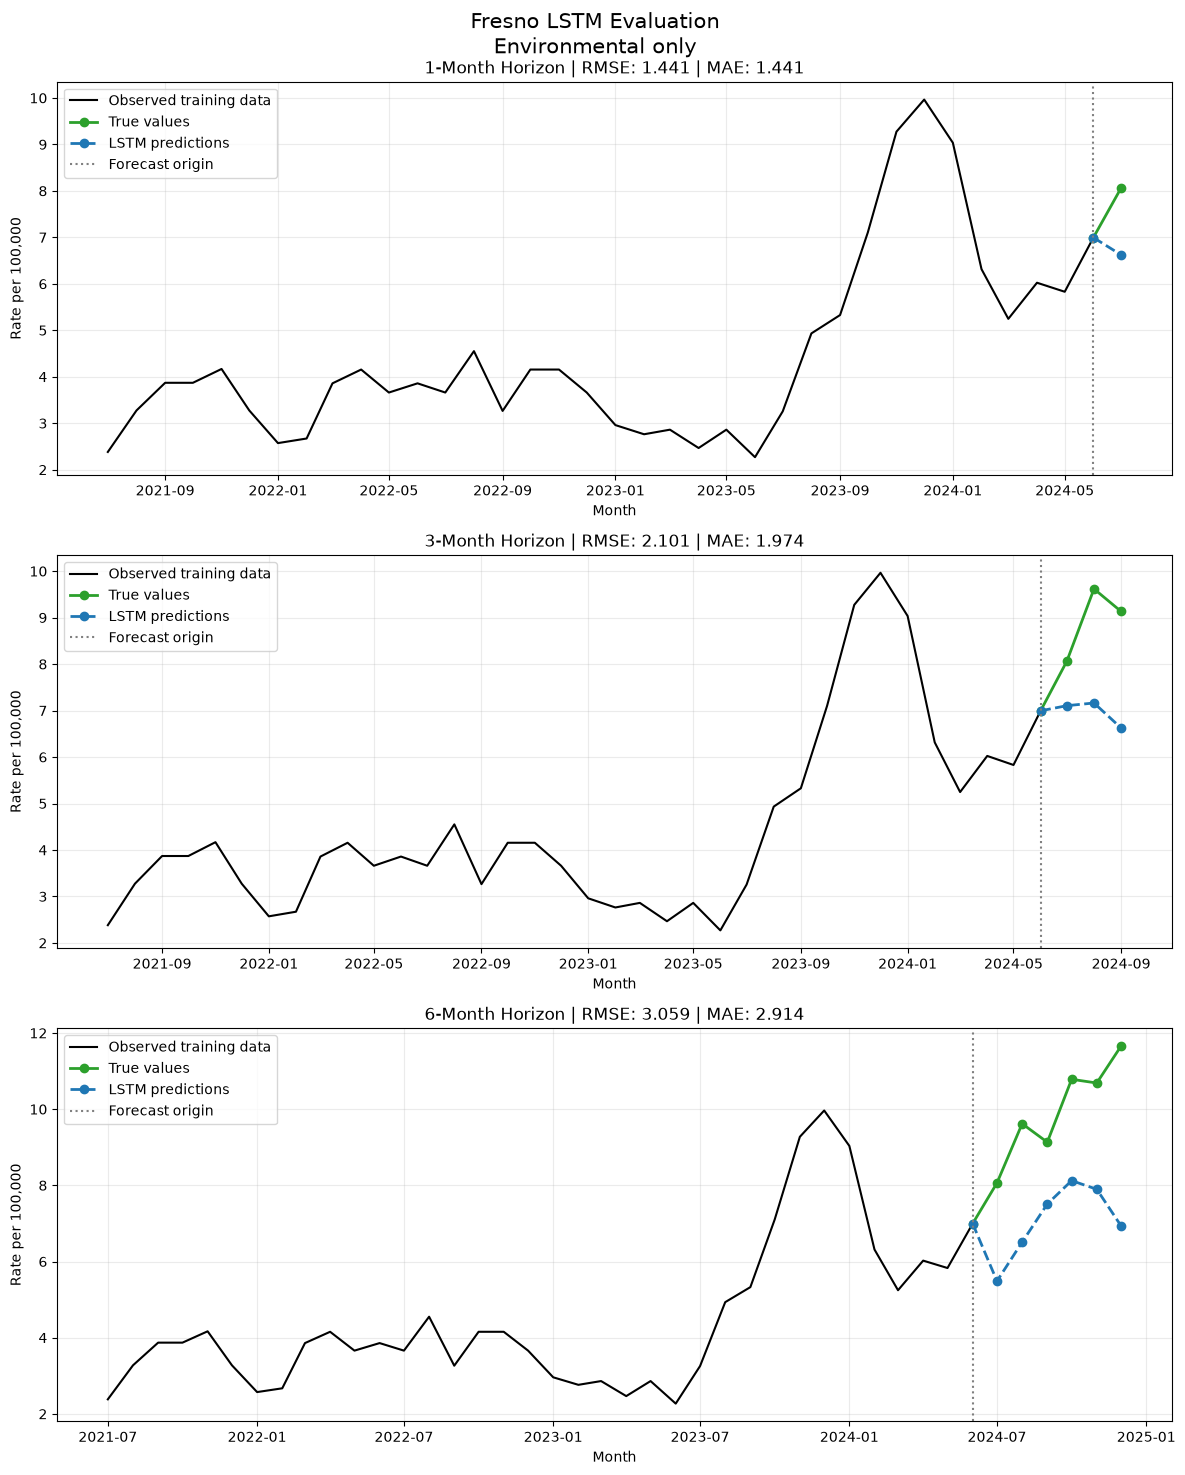

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Lead_Month,Target_Date,Prediction,Actual,Error
0,Fresno,Environmental only,2024-06-01,1,1,2024-07-01,6.622849,8.063874,-1.441025
1,Fresno,Environmental only,2024-06-01,3,1,2024-07-01,7.105062,8.063874,-0.958812
2,Fresno,Environmental only,2024-06-01,3,2,2024-08-01,7.163163,9.618355,-2.455192
3,Fresno,Environmental only,2024-06-01,3,3,2024-09-01,6.624179,9.132580,-2.508401
4,Fresno,Environmental only,2024-06-01,6,1,2024-07-01,5.486413,8.063874,-2.577460
5,Fresno,Environmental only,2024-06-01,6,2,2024-08-01,6.509299,9.618355,-3.109056
6,Fresno,Environmental only,2024-06-01,6,3,2024-09-01,7.509364,9.132580,-1.623216
7,Fresno,Environmental only,2024-06-01,6,4,2024-10-01,8.123649,10.784217,-2.660568
8,Fresno,Environmental only,2024-06-01,6,5,2024-11-01,7.896916,10.687061,-2.790145
9,Fresno,Environmental only,2024-06-01,6,6,2024-12-01,6.933678,11.658613,-4.724935


,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Sequences,Lookback,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Hidden_Size,Number_Layers,Dropout,Epochs,Learning_Rate,Weight_Decay,Batch_Size,Final_Training_Loss
0,Fresno,Environmental only,2024-06-01,1,1,191,24,13,1.441025,1.441025,False,True,16,1,0.4,400,0.001,0.00001,32,0.118014
1,Fresno,Environmental only,2024-06-01,3,3,189,24,13,2.100743,1.974135,False,True,16,1,0.4,400,0.001,0.00001,32,0.169876
2,Fresno,Environmental only,2024-06-01,6,6,186,24,13,3.058673,2.914230,False,True,16,1,0.4,400,0.001,0.00001,32,0.195225


In [23]:
fresno_lstm_results = run_lstm_county(
    county="Fresno",
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config=environment_only_config,
    lstm_parameters=lstm_parameters,
    output_dir=output_dir,
    show_plot=True,
)

display(fresno_lstm_results["predictions"])
display(fresno_lstm_results["metrics"])

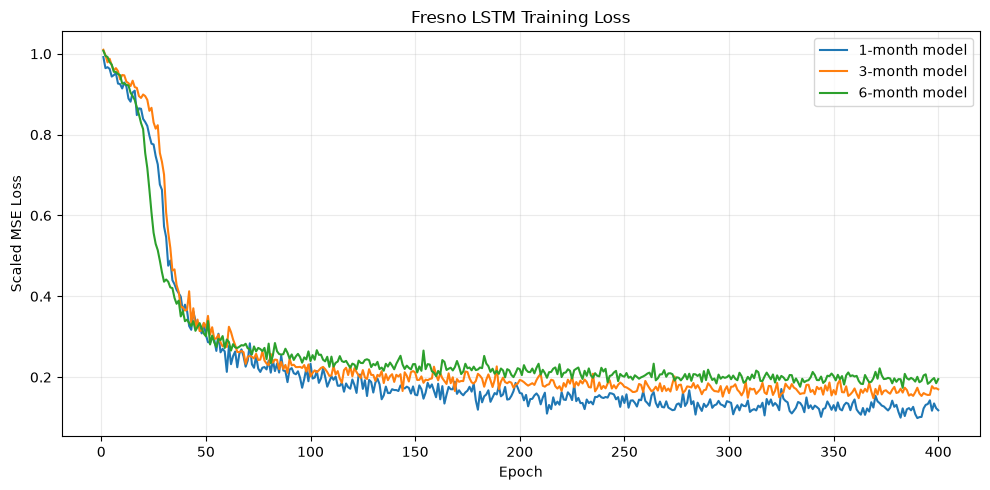

In [26]:
fresno_history = fresno_lstm_results["training_history"]

plt.figure(figsize=(10, 5))

for horizon in horizons:
    horizon_history = fresno_history.loc[fresno_history["Forecast_Horizon"] == horizon]
    plt.plot(horizon_history["Epoch"], horizon_history["Training_Loss"], label=f"{horizon}-month model")

plt.title("Fresno LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Scaled MSE Loss")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

In [24]:
def run_lstm_all_counties(counties, evaluation_date, data, feature_columns, horizons, feature_config, lstm_parameters, output_dir, show_plots=True):
    """Run the complete LSTM workflow for every county."""

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    model_slug = "with_rate" if feature_config["use_rate_features"] else "environment_only"

    county_results = {}
    prediction_results = []
    metric_results = []
    history_results = []

    for county in counties:
        print(f"\nRunning {county}...")

        results = run_lstm_county(
            county=county,
            evaluation_date=evaluation_date,
            data=data,
            feature_columns=feature_columns,
            horizons=horizons,
            feature_config=feature_config,
            lstm_parameters=lstm_parameters,
            output_dir=output_dir,
            show_plot=show_plots,
        )

        county_results[county] = results
        prediction_results.append(results["predictions"])
        metric_results.append(results["metrics"])
        history_results.append(results["training_history"])

    all_predictions = pd.concat(prediction_results, ignore_index=True)
    all_metrics = pd.concat(metric_results, ignore_index=True)
    all_training_history = pd.concat(history_results, ignore_index=True)

    metric_summary = all_metrics.pivot(index="County", columns="Forecast_Horizon", values=["RMSE", "MAE"])
    date_slug = pd.Timestamp(evaluation_date).strftime("%Y-%m")

    all_predictions.to_csv(
        output_dir / f"all_counties_lstm_{model_slug}_predictions_{date_slug}.csv",
        index=False,
        date_format="%Y-%m-%d",
    )

    all_metrics.to_csv(
        output_dir / f"all_counties_lstm_{model_slug}_metrics_{date_slug}.csv",
        index=False,
        date_format="%Y-%m-%d",
    )

    all_training_history.to_csv(
        output_dir / f"all_counties_lstm_{model_slug}_history_{date_slug}.csv",
        index=False,
    )

    metric_summary.to_csv(output_dir / f"lstm_{model_slug}_metric_summary_{date_slug}.csv")

    return {
        "county_results": county_results,
        "predictions": all_predictions,
        "metrics": all_metrics,
        "training_history": all_training_history,
        "metric_summary": metric_summary,
    }


Running Fresno...
Fresno: training 1-month model...
Epoch 50/400 | Loss: 0.304313
Epoch 100/400 | Loss: 0.233133
Epoch 150/400 | Loss: 0.156756
Epoch 200/400 | Loss: 0.160831
Epoch 250/400 | Loss: 0.136044
Epoch 300/400 | Loss: 0.138514
Epoch 350/400 | Loss: 0.130819
Epoch 400/400 | Loss: 0.118014
Fresno: training 3-month model...
Epoch 50/400 | Loss: 0.322132
Epoch 100/400 | Loss: 0.201812
Epoch 150/400 | Loss: 0.211722
Epoch 200/400 | Loss: 0.193103
Epoch 250/400 | Loss: 0.176162
Epoch 300/400 | Loss: 0.160542
Epoch 350/400 | Loss: 0.168144
Epoch 400/400 | Loss: 0.169876
Fresno: training 6-month model...
Epoch 50/400 | Loss: 0.301220
Epoch 100/400 | Loss: 0.239897
Epoch 150/400 | Loss: 0.232297
Epoch 200/400 | Loss: 0.219794
Epoch 250/400 | Loss: 0.201139
Epoch 300/400 | Loss: 0.204621
Epoch 350/400 | Loss: 0.202569
Epoch 400/400 | Loss: 0.195225


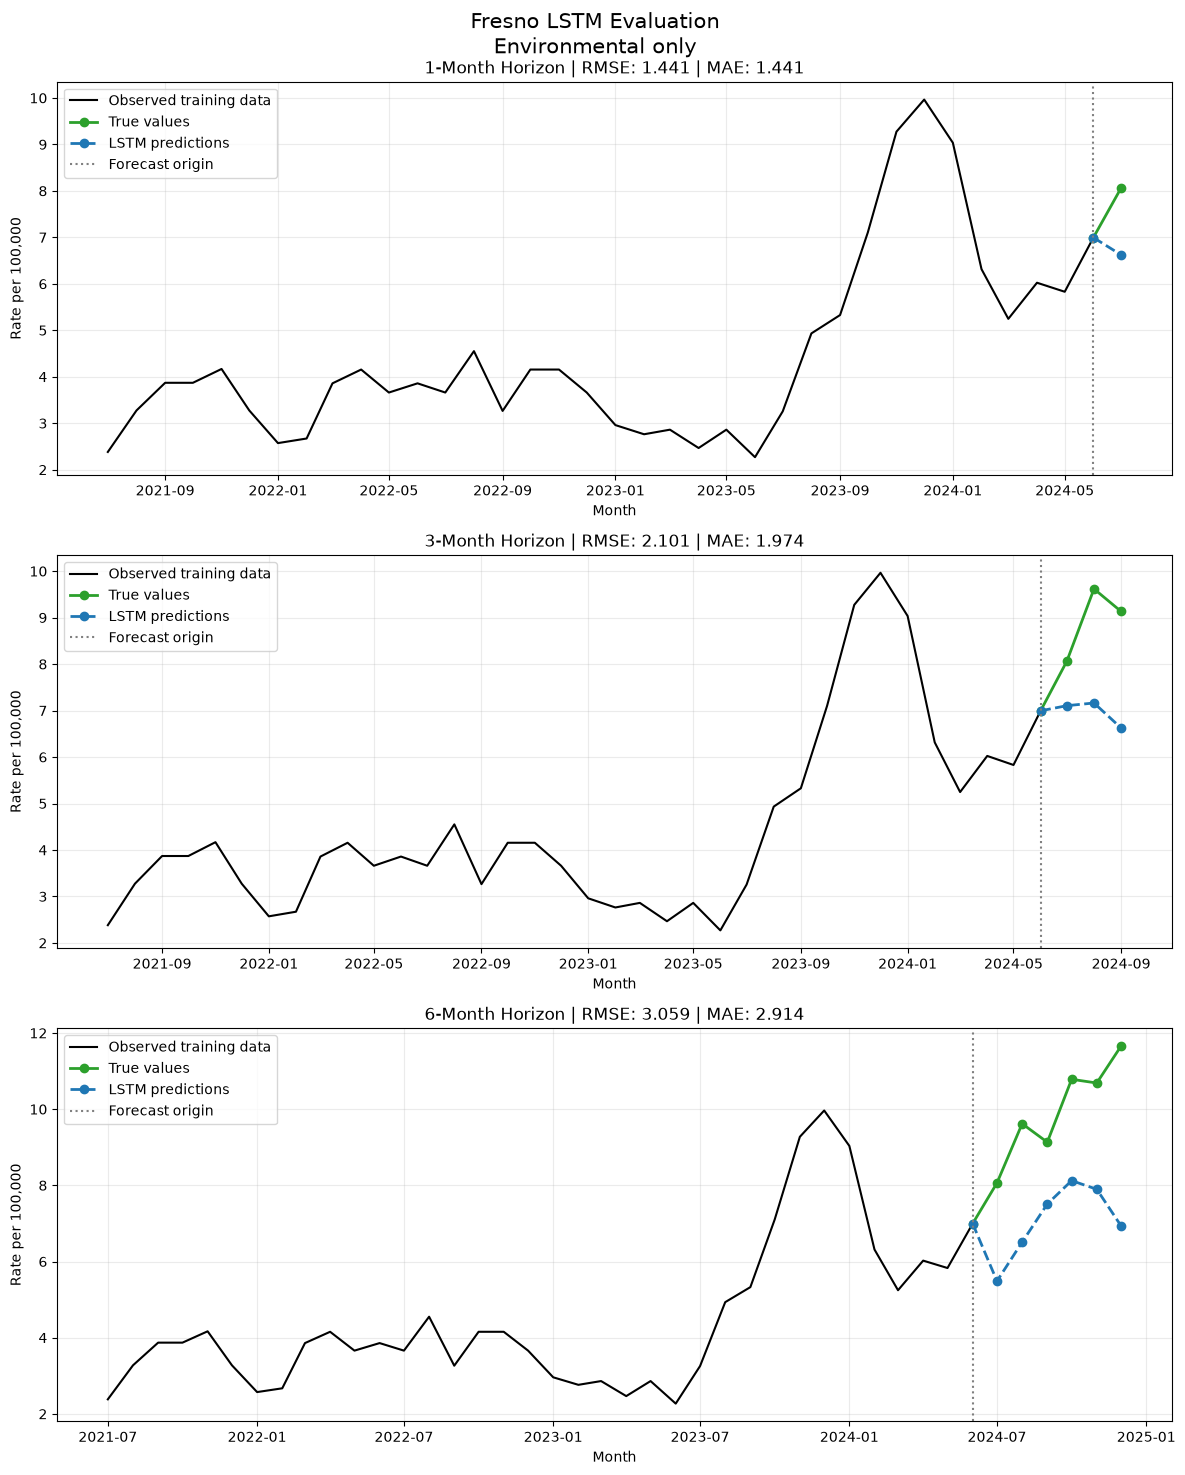


Running Kern...
Kern: training 1-month model...
Epoch 50/400 | Loss: 0.151591
Epoch 100/400 | Loss: 0.134988
Epoch 150/400 | Loss: 0.142158
Epoch 200/400 | Loss: 0.111703
Epoch 250/400 | Loss: 0.100965
Epoch 300/400 | Loss: 0.099382
Epoch 350/400 | Loss: 0.077645
Epoch 400/400 | Loss: 0.072543
Kern: training 3-month model...
Epoch 50/400 | Loss: 0.179771
Epoch 100/400 | Loss: 0.153689
Epoch 150/400 | Loss: 0.143311
Epoch 200/400 | Loss: 0.143651
Epoch 250/400 | Loss: 0.121206
Epoch 300/400 | Loss: 0.109027
Epoch 350/400 | Loss: 0.115535
Epoch 400/400 | Loss: 0.106934
Kern: training 6-month model...
Epoch 50/400 | Loss: 0.204641
Epoch 100/400 | Loss: 0.182301
Epoch 150/400 | Loss: 0.156113
Epoch 200/400 | Loss: 0.172100
Epoch 250/400 | Loss: 0.146510
Epoch 300/400 | Loss: 0.149264
Epoch 350/400 | Loss: 0.141911
Epoch 400/400 | Loss: 0.142607


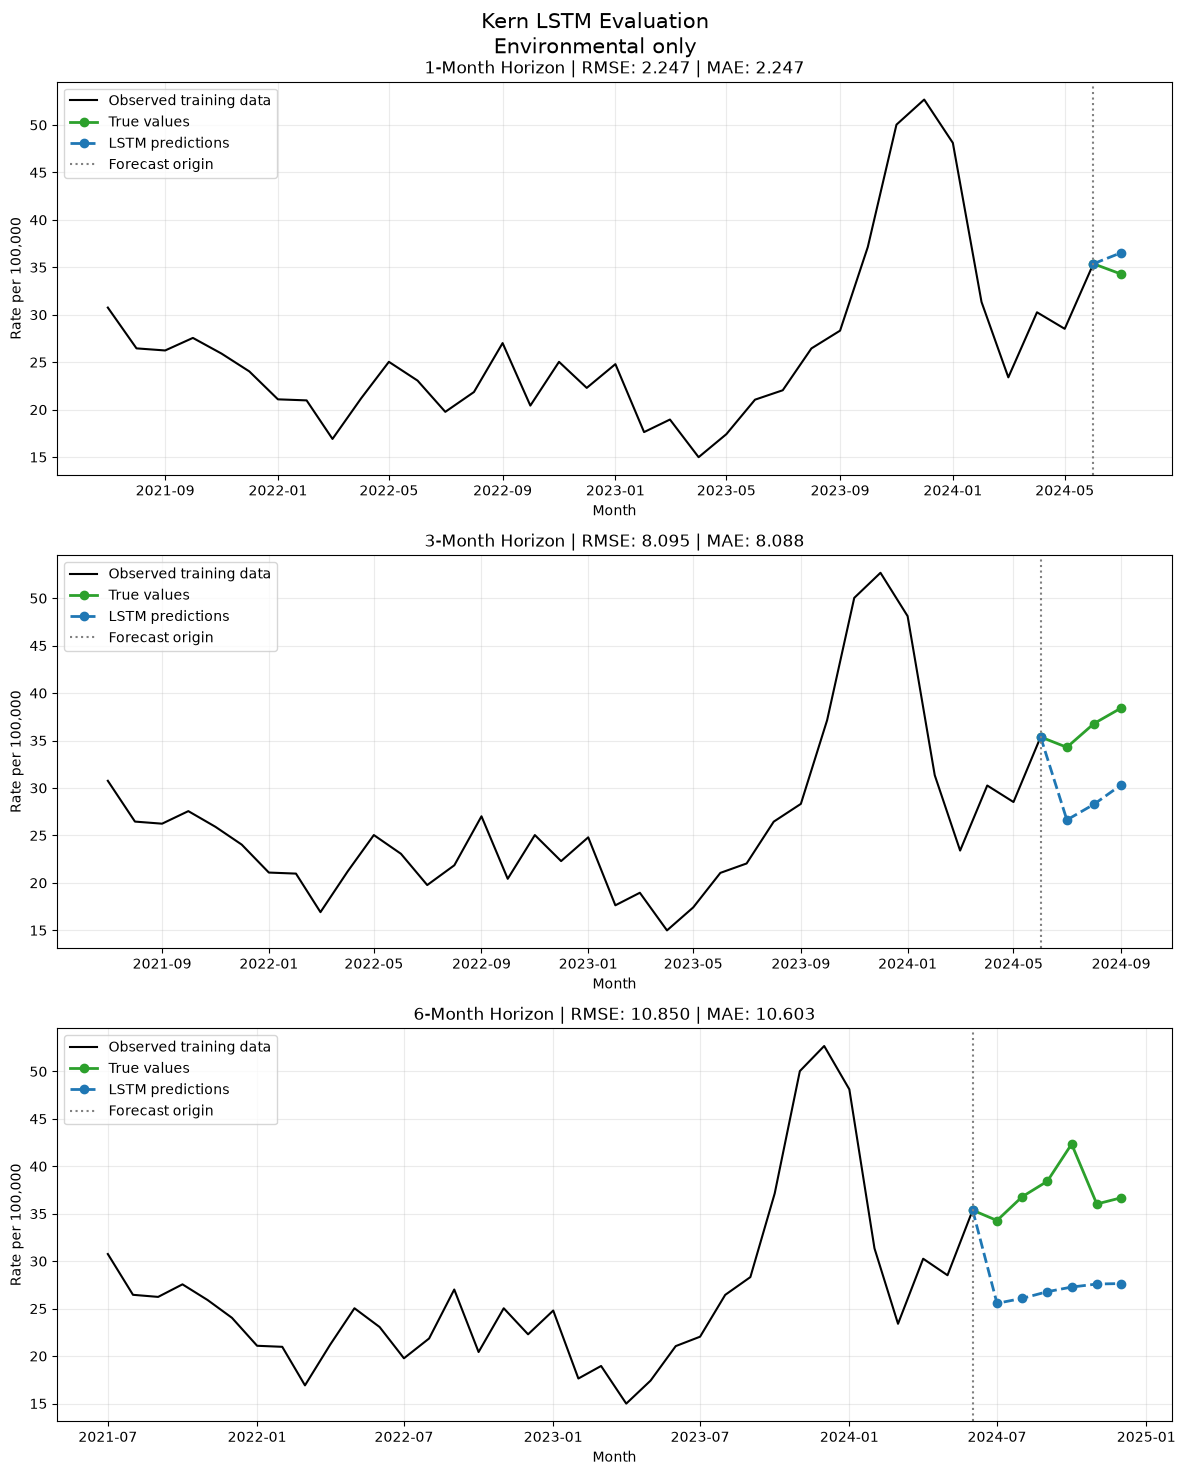


Running Los Angeles...
Los Angeles: training 1-month model...
Epoch 50/400 | Loss: 0.119365
Epoch 100/400 | Loss: 0.090916
Epoch 150/400 | Loss: 0.106683
Epoch 200/400 | Loss: 0.082137
Epoch 250/400 | Loss: 0.070800
Epoch 300/400 | Loss: 0.081765
Epoch 350/400 | Loss: 0.072691
Epoch 400/400 | Loss: 0.083280
Los Angeles: training 3-month model...
Epoch 50/400 | Loss: 0.139151
Epoch 100/400 | Loss: 0.092330
Epoch 150/400 | Loss: 0.103540
Epoch 200/400 | Loss: 0.094954
Epoch 250/400 | Loss: 0.094842
Epoch 300/400 | Loss: 0.101662
Epoch 350/400 | Loss: 0.079214
Epoch 400/400 | Loss: 0.090673
Los Angeles: training 6-month model...
Epoch 50/400 | Loss: 0.131819
Epoch 100/400 | Loss: 0.125101
Epoch 150/400 | Loss: 0.120604
Epoch 200/400 | Loss: 0.109356
Epoch 250/400 | Loss: 0.105325
Epoch 300/400 | Loss: 0.103154
Epoch 350/400 | Loss: 0.101002
Epoch 400/400 | Loss: 0.102225


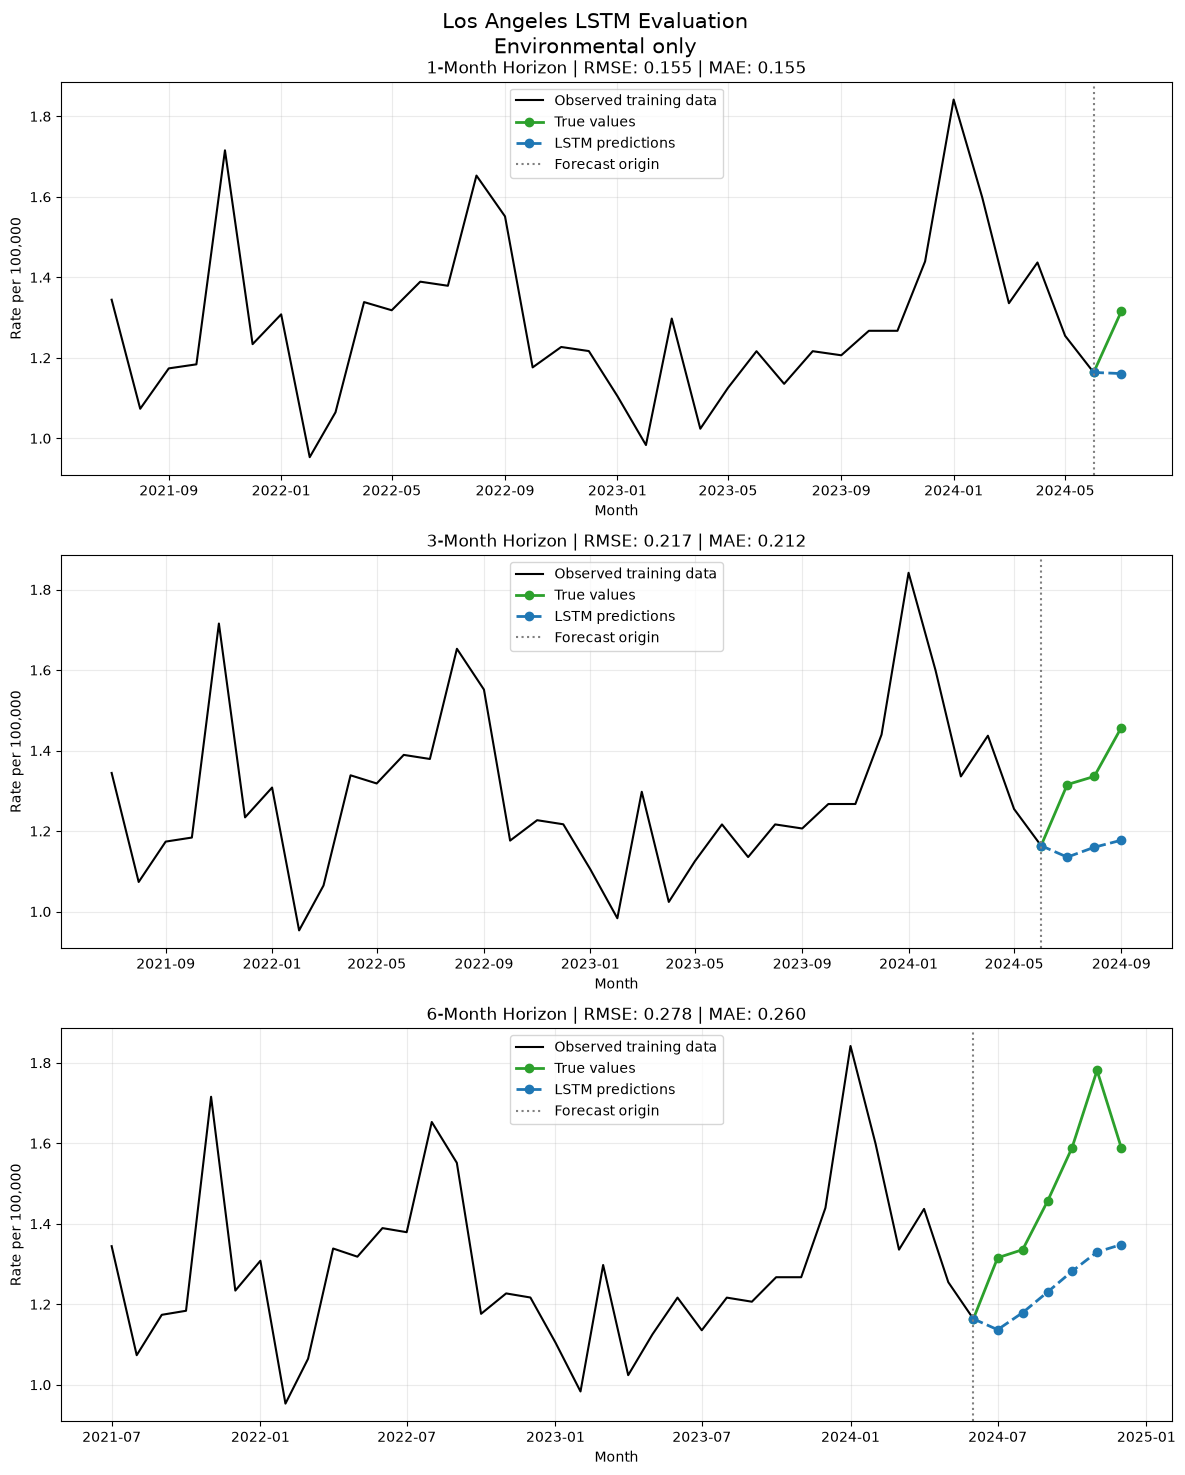


Running Orange...
Orange: training 1-month model...
Epoch 50/400 | Loss: 0.234638
Epoch 100/400 | Loss: 0.204986
Epoch 150/400 | Loss: 0.210462
Epoch 200/400 | Loss: 0.151989
Epoch 250/400 | Loss: 0.124778
Epoch 300/400 | Loss: 0.129284
Epoch 350/400 | Loss: 0.142221
Epoch 400/400 | Loss: 0.121369
Orange: training 3-month model...
Epoch 50/400 | Loss: 0.260614
Epoch 100/400 | Loss: 0.218931
Epoch 150/400 | Loss: 0.217090
Epoch 200/400 | Loss: 0.187698
Epoch 250/400 | Loss: 0.186007
Epoch 300/400 | Loss: 0.170314
Epoch 350/400 | Loss: 0.171301
Epoch 400/400 | Loss: 0.169103
Orange: training 6-month model...
Epoch 50/400 | Loss: 0.270097
Epoch 100/400 | Loss: 0.239149
Epoch 150/400 | Loss: 0.206181
Epoch 200/400 | Loss: 0.202642
Epoch 250/400 | Loss: 0.195998
Epoch 300/400 | Loss: 0.197426
Epoch 350/400 | Loss: 0.185682
Epoch 400/400 | Loss: 0.181766


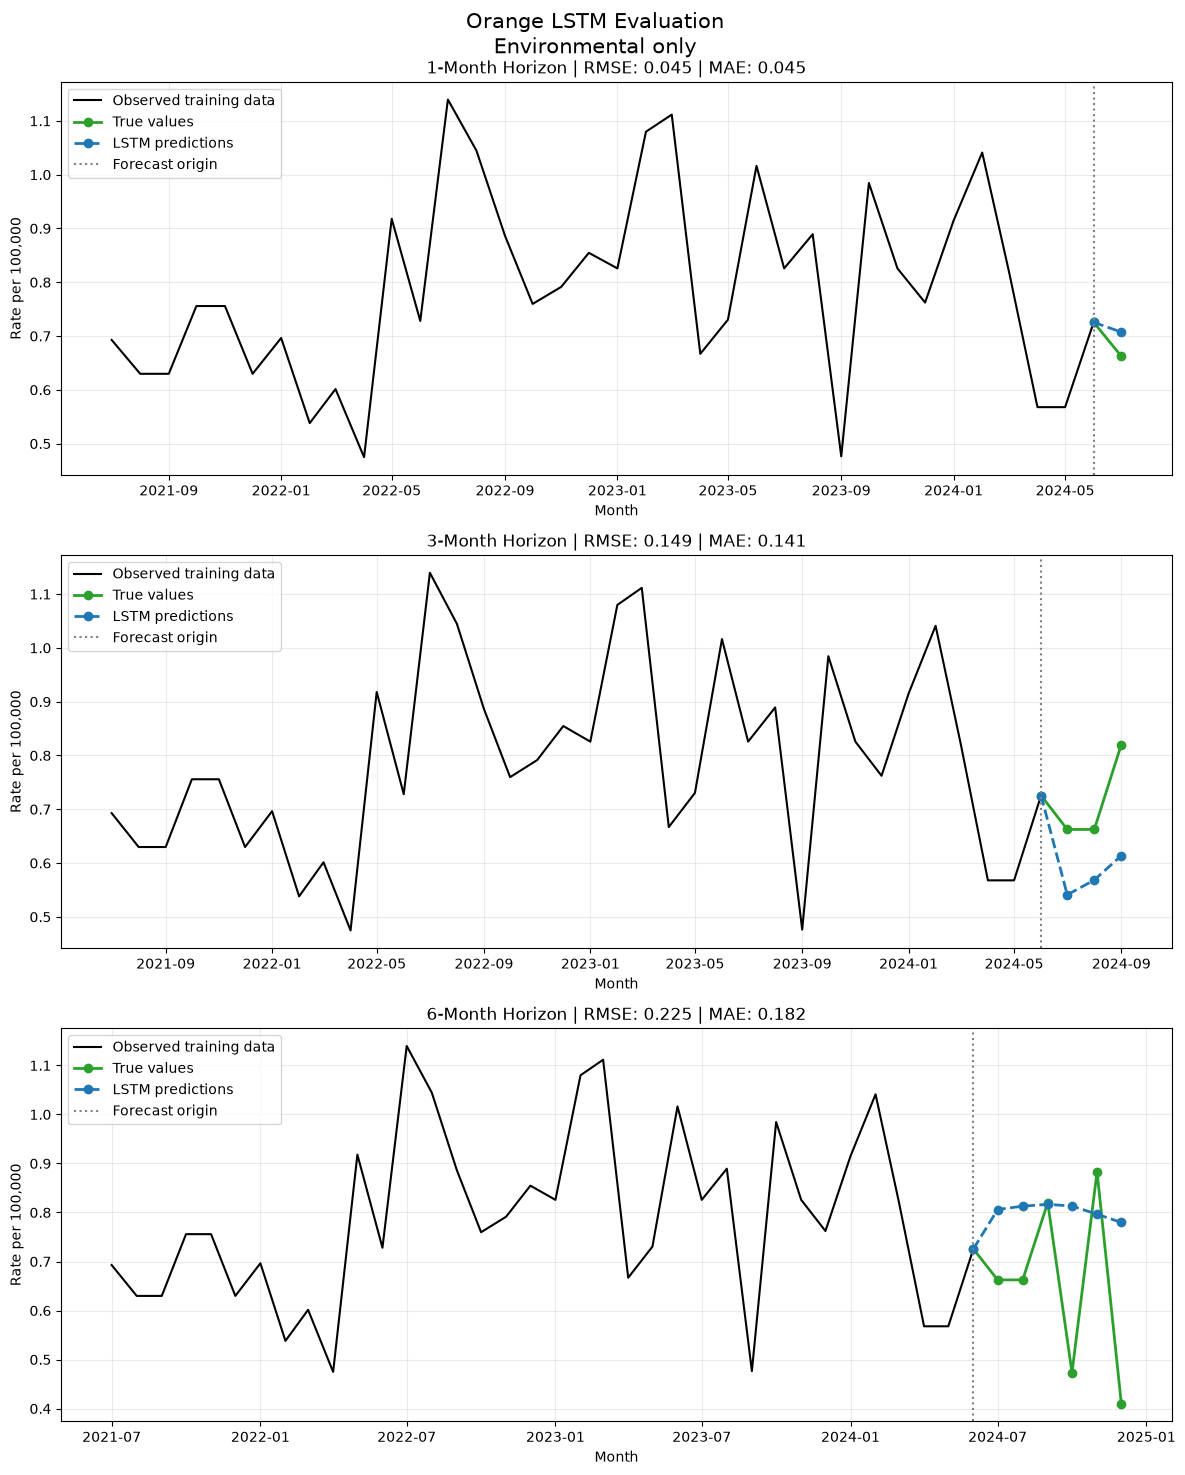


Running San Diego...
San Diego: training 1-month model...
Epoch 50/400 | Loss: 0.175320
Epoch 100/400 | Loss: 0.141312
Epoch 150/400 | Loss: 0.160045
Epoch 200/400 | Loss: 0.125953
Epoch 250/400 | Loss: 0.112779
Epoch 300/400 | Loss: 0.128715
Epoch 350/400 | Loss: 0.128986
Epoch 400/400 | Loss: 0.110021
San Diego: training 3-month model...
Epoch 50/400 | Loss: 0.205425
Epoch 100/400 | Loss: 0.167393
Epoch 150/400 | Loss: 0.189397
Epoch 200/400 | Loss: 0.164008
Epoch 250/400 | Loss: 0.163211
Epoch 300/400 | Loss: 0.147790
Epoch 350/400 | Loss: 0.155748
Epoch 400/400 | Loss: 0.159310
San Diego: training 6-month model...
Epoch 50/400 | Loss: 0.216632
Epoch 100/400 | Loss: 0.186724
Epoch 150/400 | Loss: 0.196357
Epoch 200/400 | Loss: 0.184067
Epoch 250/400 | Loss: 0.184524
Epoch 300/400 | Loss: 0.160944
Epoch 350/400 | Loss: 0.162350
Epoch 400/400 | Loss: 0.159932


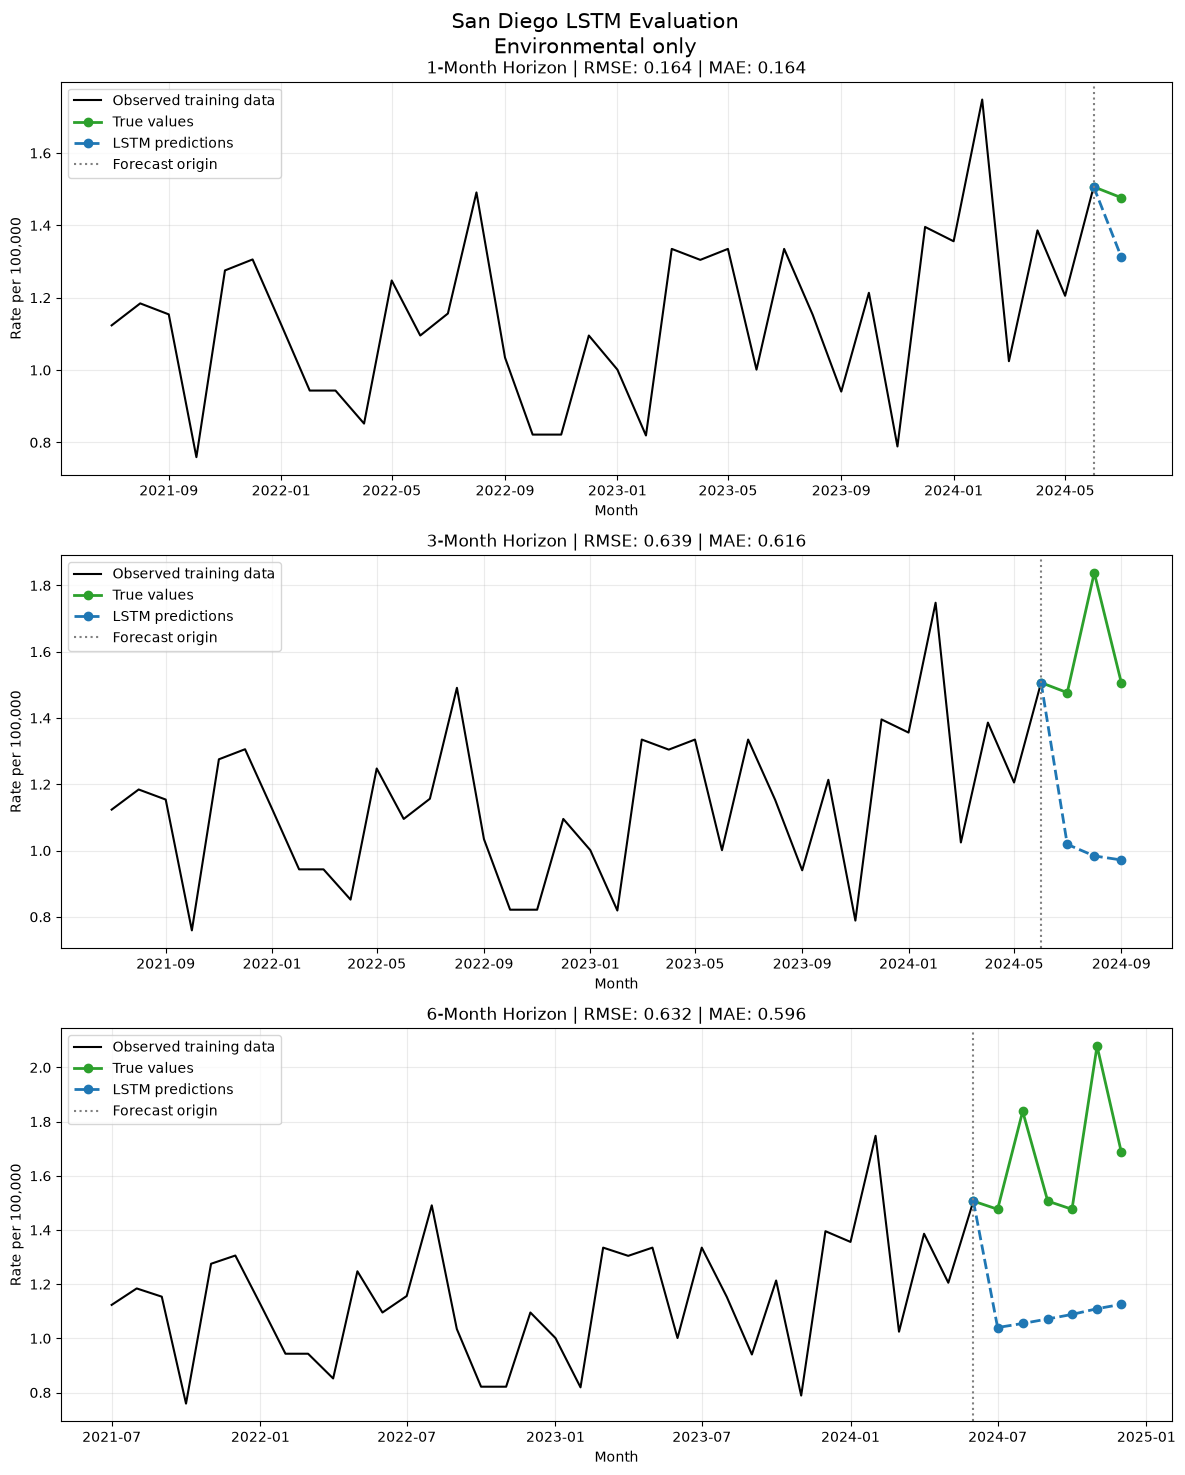


Running San Luis Obispo...
San Luis Obispo: training 1-month model...
Epoch 50/400 | Loss: 0.220862
Epoch 100/400 | Loss: 0.212466
Epoch 150/400 | Loss: 0.198283
Epoch 200/400 | Loss: 0.169940
Epoch 250/400 | Loss: 0.139088
Epoch 300/400 | Loss: 0.146065
Epoch 350/400 | Loss: 0.127391
Epoch 400/400 | Loss: 0.127454
San Luis Obispo: training 3-month model...
Epoch 50/400 | Loss: 0.282778
Epoch 100/400 | Loss: 0.215278
Epoch 150/400 | Loss: 0.213744
Epoch 200/400 | Loss: 0.202787
Epoch 250/400 | Loss: 0.176030
Epoch 300/400 | Loss: 0.205266
Epoch 350/400 | Loss: 0.182331
Epoch 400/400 | Loss: 0.193311
San Luis Obispo: training 6-month model...
Epoch 50/400 | Loss: 0.298938
Epoch 100/400 | Loss: 0.269609
Epoch 150/400 | Loss: 0.243519
Epoch 200/400 | Loss: 0.224993
Epoch 250/400 | Loss: 0.230561
Epoch 300/400 | Loss: 0.217092
Epoch 350/400 | Loss: 0.215090
Epoch 400/400 | Loss: 0.211013


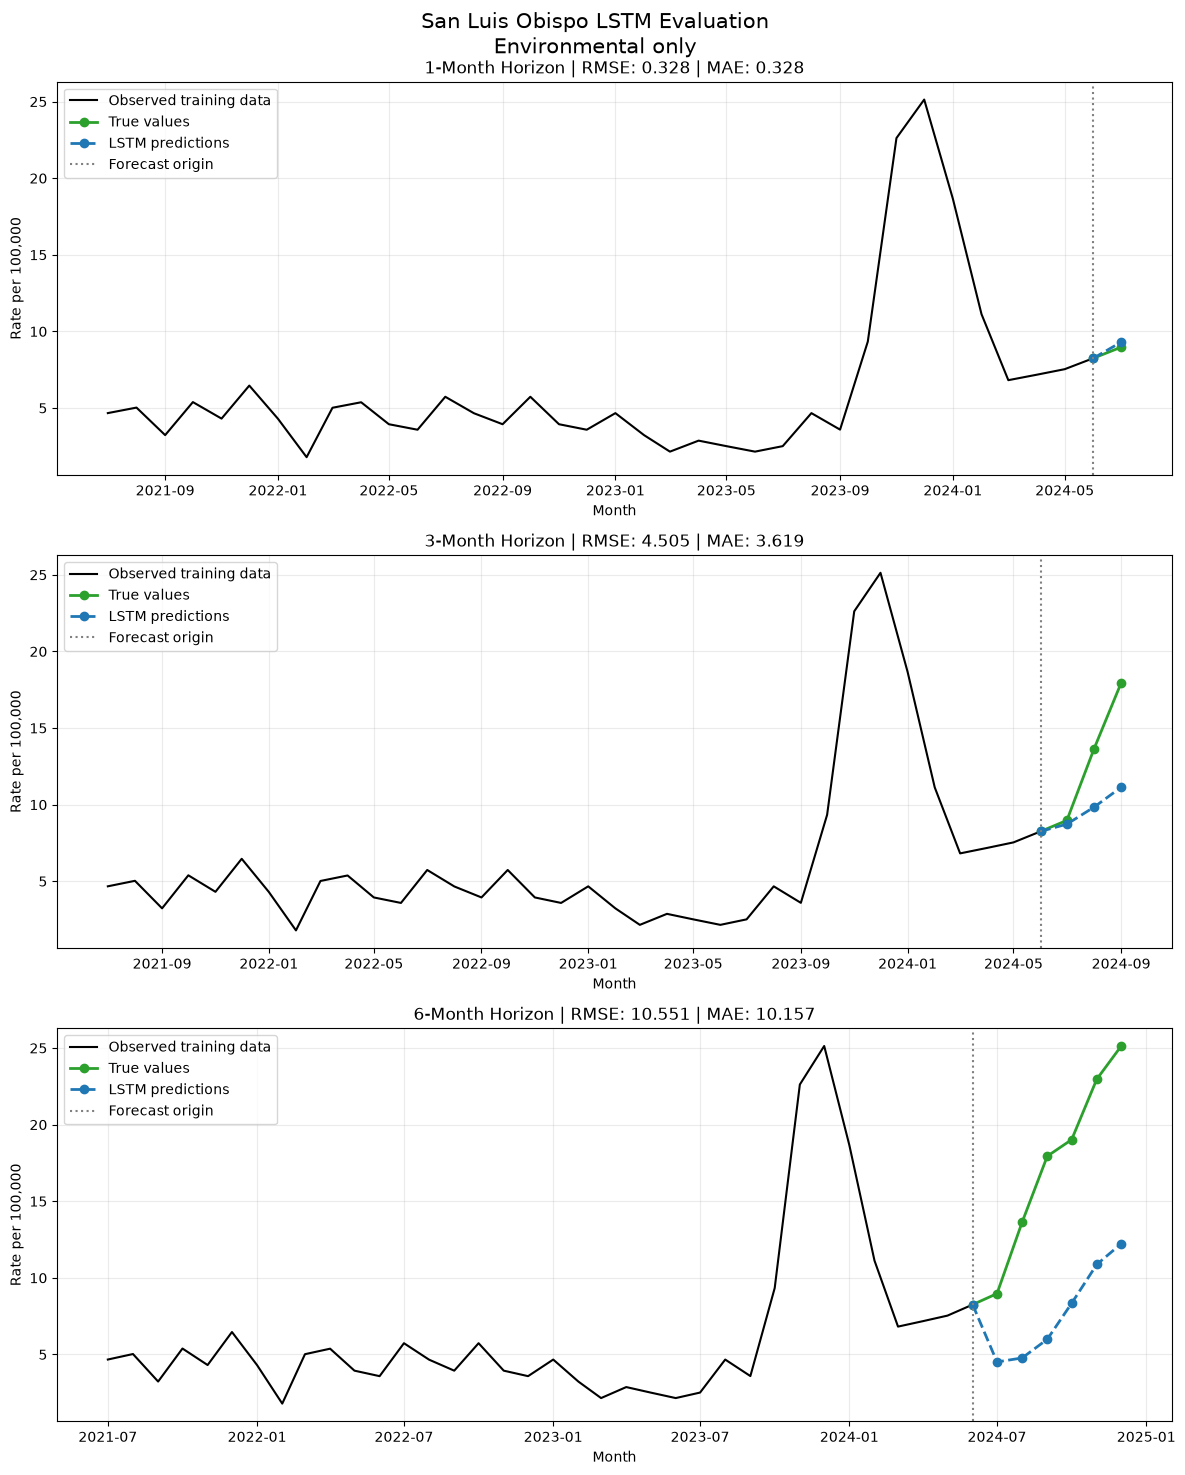


Running Tulare...
Tulare: training 1-month model...
Epoch 50/400 | Loss: 0.348683
Epoch 100/400 | Loss: 0.245751
Epoch 150/400 | Loss: 0.242008
Epoch 200/400 | Loss: 0.216199
Epoch 250/400 | Loss: 0.193085
Epoch 300/400 | Loss: 0.186848
Epoch 350/400 | Loss: 0.175606
Epoch 400/400 | Loss: 0.146893
Tulare: training 3-month model...
Epoch 50/400 | Loss: 0.366592
Epoch 100/400 | Loss: 0.232997
Epoch 150/400 | Loss: 0.240096
Epoch 200/400 | Loss: 0.222093
Epoch 250/400 | Loss: 0.216150
Epoch 300/400 | Loss: 0.216316
Epoch 350/400 | Loss: 0.204303
Epoch 400/400 | Loss: 0.207783
Tulare: training 6-month model...
Epoch 50/400 | Loss: 0.385312
Epoch 100/400 | Loss: 0.313205
Epoch 150/400 | Loss: 0.250729
Epoch 200/400 | Loss: 0.259347
Epoch 250/400 | Loss: 0.260767
Epoch 300/400 | Loss: 0.241143
Epoch 350/400 | Loss: 0.234809
Epoch 400/400 | Loss: 0.233519


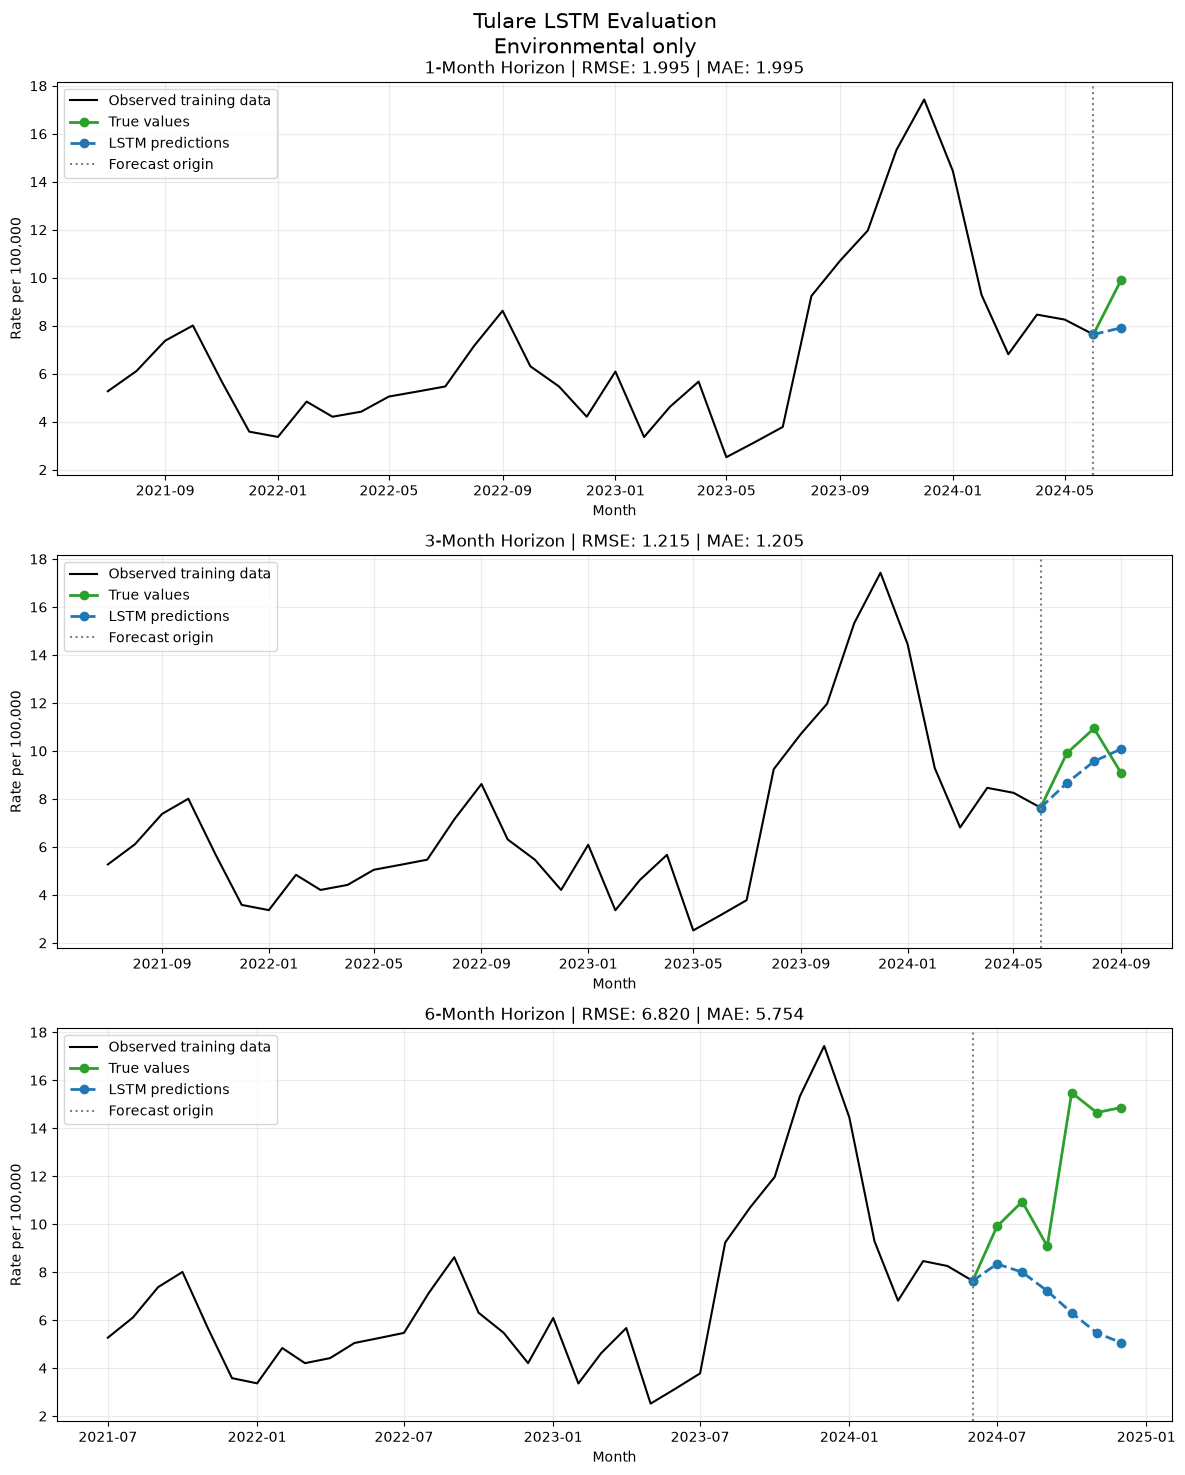


Running Ventura...
Ventura: training 1-month model...
Epoch 50/400 | Loss: 0.195027
Epoch 100/400 | Loss: 0.160847
Epoch 150/400 | Loss: 0.175897
Epoch 200/400 | Loss: 0.118508
Epoch 250/400 | Loss: 0.130919
Epoch 300/400 | Loss: 0.130511
Epoch 350/400 | Loss: 0.124229
Epoch 400/400 | Loss: 0.101877
Ventura: training 3-month model...
Epoch 50/400 | Loss: 0.240007
Epoch 100/400 | Loss: 0.184960
Epoch 150/400 | Loss: 0.177617
Epoch 200/400 | Loss: 0.174654
Epoch 250/400 | Loss: 0.160117
Epoch 300/400 | Loss: 0.179569
Epoch 350/400 | Loss: 0.159204
Epoch 400/400 | Loss: 0.163570
Ventura: training 6-month model...
Epoch 50/400 | Loss: 0.245117
Epoch 100/400 | Loss: 0.230177
Epoch 150/400 | Loss: 0.208839
Epoch 200/400 | Loss: 0.192962
Epoch 250/400 | Loss: 0.187783
Epoch 300/400 | Loss: 0.169938
Epoch 350/400 | Loss: 0.181143
Epoch 400/400 | Loss: 0.170867


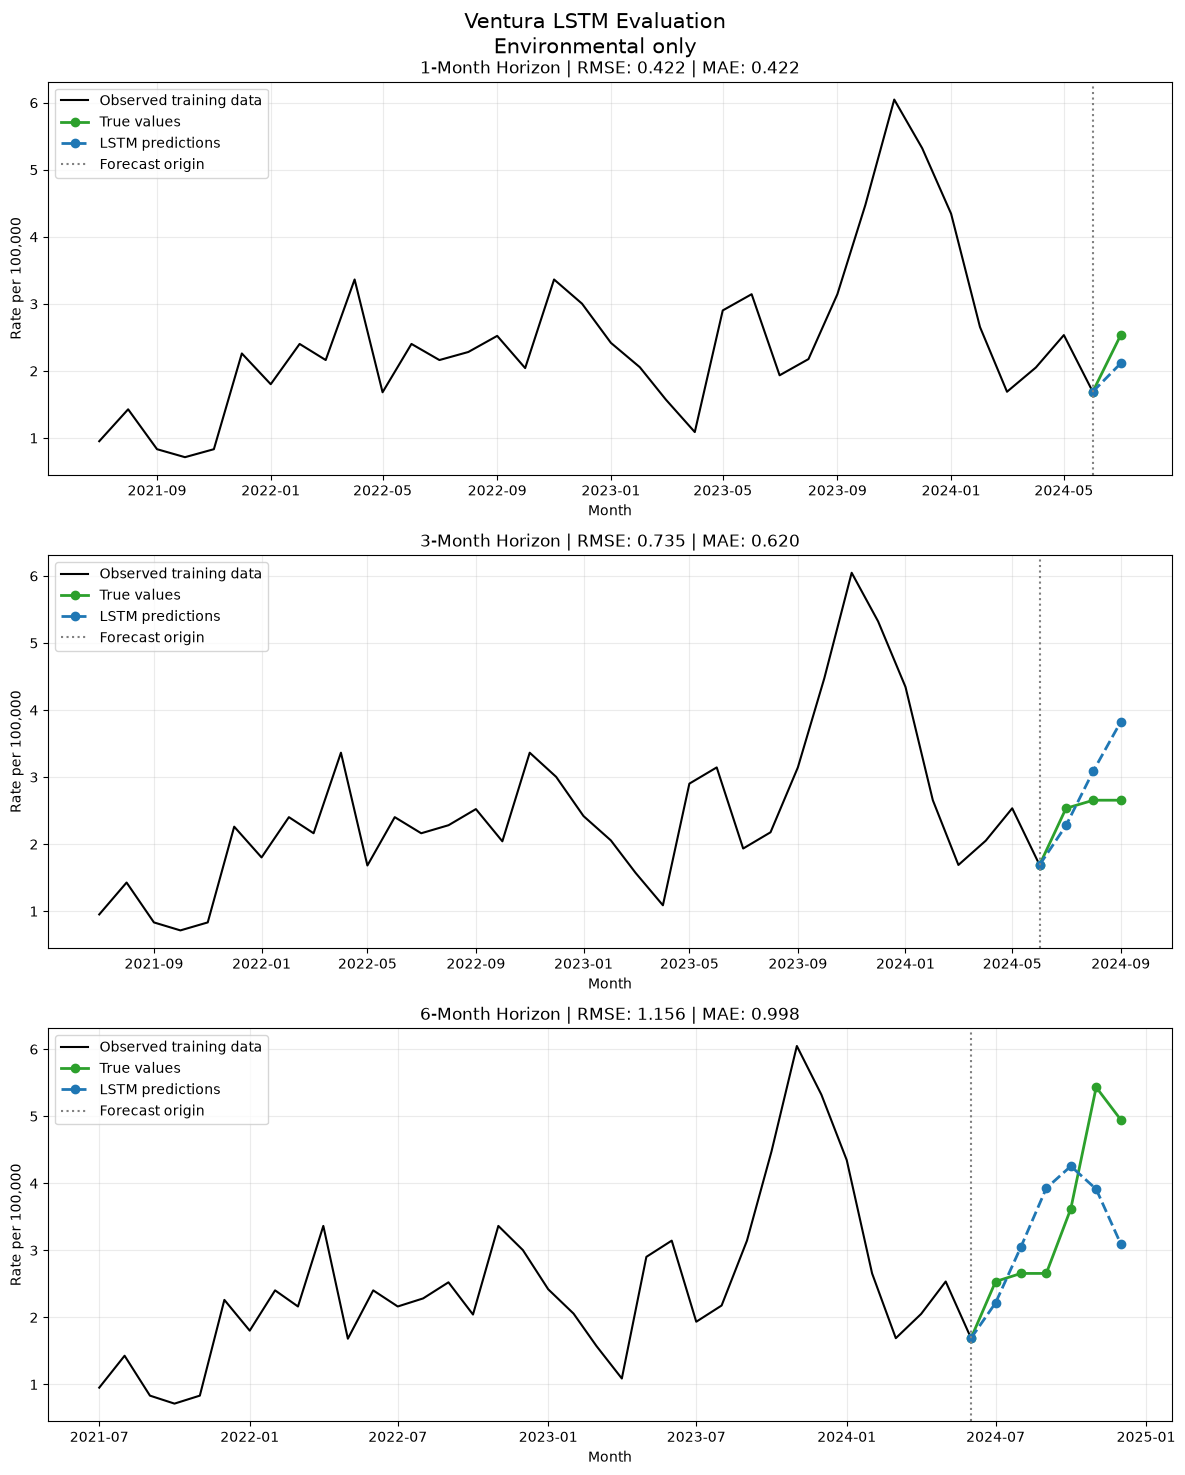

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Sequences,Lookback,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Hidden_Size,Number_Layers,Dropout,Epochs,Learning_Rate,Weight_Decay,Batch_Size,Final_Training_Loss
0,Fresno,Environmental only,2024-06-01,1,1,191,24,13,1.441025,1.441025,False,True,16,1,0.4,400,0.001,0.00001,32,0.118014
1,Fresno,Environmental only,2024-06-01,3,3,189,24,13,2.100743,1.974135,False,True,16,1,0.4,400,0.001,0.00001,32,0.169876
2,Fresno,Environmental only,2024-06-01,6,6,186,24,13,3.058673,2.914230,False,True,16,1,0.4,400,0.001,0.00001,32,0.195225
3,Kern,Environmental only,2024-06-01,1,1,191,24,13,2.247175,2.247175,False,True,16,1,0.4,400,0.001,0.00001,32,0.072543
4,Kern,Environmental only,2024-06-01,3,3,189,24,13,8.095031,8.087540,False,True,16,1,0.4,400,0.001,0.00001,32,0.106934
5,Kern,Environmental only,2024-06-01,6,6,186,24,13,10.849590,10.603439,False,True,16,1,0.4,400,0.001,0.00001,32,0.142607
6,Los Angeles,Environmental only,2024-06-01,1,1,191,24,13,0.154547,0.154547,False,True,16,1,0.4,400,0.001,0.00001,32,0.083280
7,Los Angeles,Environmental only,2024-06-01,3,3,189,24,13,0.217404,0.212035,False,True,16,1,0.4,400,0.001,0.00001,32,0.090673
8,Los Angeles,Environmental only,2024-06-01,6,6,186,24,13,0.277810,0.259967,False,True,16,1,0.4,400,0.001,0.00001,32,0.102225
9,Orange,Environmental only,2024-06-01,1,1,191,24,13,0.044884,0.044884,False,True,16,1,0.4,400,0.001,0.00001,32,0.121369


RMSE                            MAE                     
Forecast_Horizon         1         3          6         1         3          6
County                                                                        
Fresno            1.441025  2.100743   3.058673  1.441025  1.974135   2.914230
Kern              2.247175  8.095031  10.849590  2.247175  8.087540  10.603439
Los Angeles       0.154547  0.217404   0.277810  0.154547  0.212035   0.259967
Orange            0.044884  0.148623   0.224729  0.044884  0.140690   0.182369
San Diego         0.164169  0.639136   0.632402  0.164169  0.615641   0.595709
San Luis Obispo   0.328053  4.505357  10.550929  0.328053  3.618836  10.157480
Tulare            1.994606  1.215251   6.819914  1.994606  1.205464   5.754093
Ventura           0.421504  0.735097   1.155653  0.421504  0.620361   0.998339

In [25]:
environment_only_config = {**feature_config, "use_rate_features": False}

all_lstm_environment_only = run_lstm_all_counties(
    counties=counties,
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config=environment_only_config,
    lstm_parameters=lstm_parameters,
    output_dir=output_dir,
    show_plots=True,
)

display(all_lstm_environment_only["metrics"])
display(all_lstm_environment_only["metric_summary"])


Running Fresno...
Fresno: training 1-month model...
Epoch 50/400 | Loss: 0.313309
Epoch 100/400 | Loss: 0.190625
Epoch 150/400 | Loss: 0.148229
Epoch 200/400 | Loss: 0.140981
Epoch 250/400 | Loss: 0.109729
Epoch 300/400 | Loss: 0.120760
Epoch 350/400 | Loss: 0.107463
Epoch 400/400 | Loss: 0.108331
Fresno: training 3-month model...
Epoch 50/400 | Loss: 0.327447
Epoch 100/400 | Loss: 0.242875
Epoch 150/400 | Loss: 0.215143
Epoch 200/400 | Loss: 0.182470
Epoch 250/400 | Loss: 0.179090
Epoch 300/400 | Loss: 0.167783
Epoch 350/400 | Loss: 0.176008
Epoch 400/400 | Loss: 0.179338
Fresno: training 6-month model...
Epoch 50/400 | Loss: 0.322829
Epoch 100/400 | Loss: 0.269762
Epoch 150/400 | Loss: 0.225341
Epoch 200/400 | Loss: 0.205343
Epoch 250/400 | Loss: 0.200070
Epoch 300/400 | Loss: 0.195063
Epoch 350/400 | Loss: 0.222890
Epoch 400/400 | Loss: 0.202746


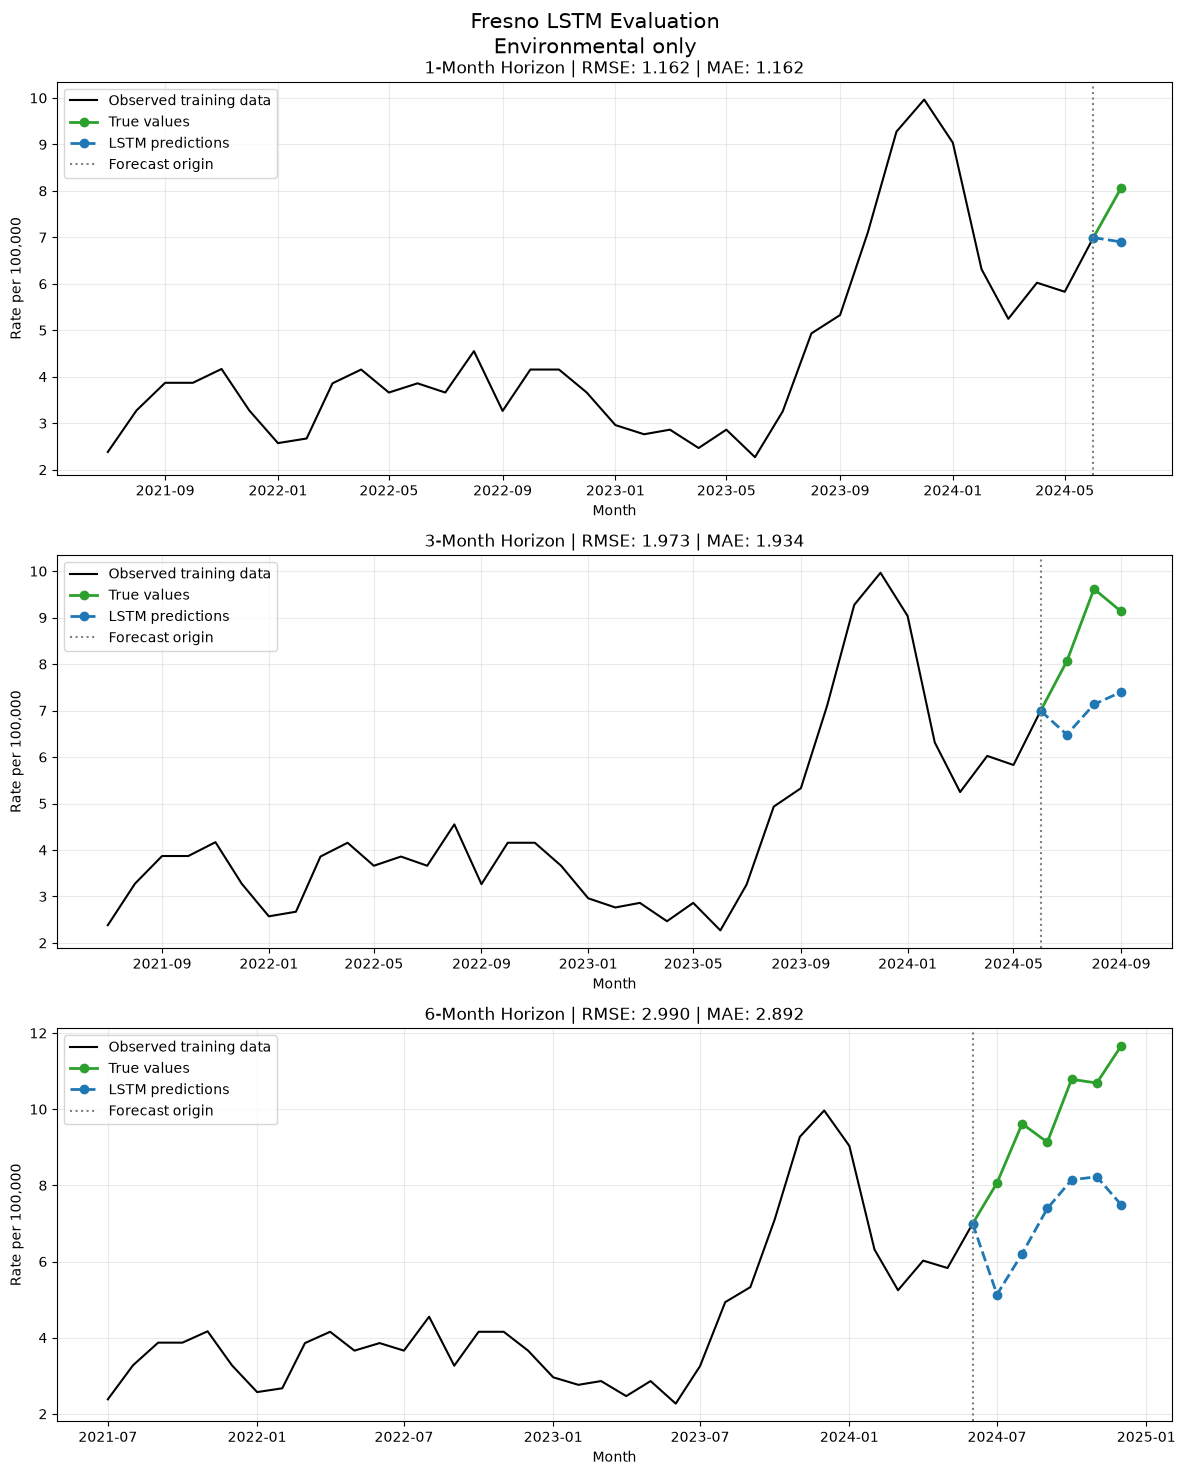


Running Kern...
Kern: training 1-month model...
Epoch 50/400 | Loss: 0.180981
Epoch 100/400 | Loss: 0.162180
Epoch 150/400 | Loss: 0.145391
Epoch 200/400 | Loss: 0.133983
Epoch 250/400 | Loss: 0.096245
Epoch 300/400 | Loss: 0.103395
Epoch 350/400 | Loss: 0.112849
Epoch 400/400 | Loss: 0.079819
Kern: training 3-month model...
Epoch 50/400 | Loss: 0.226714
Epoch 100/400 | Loss: 0.191425
Epoch 150/400 | Loss: 0.155888
Epoch 200/400 | Loss: 0.128396
Epoch 250/400 | Loss: 0.136527
Epoch 300/400 | Loss: 0.120987
Epoch 350/400 | Loss: 0.121161
Epoch 400/400 | Loss: 0.141343
Kern: training 6-month model...
Epoch 50/400 | Loss: 0.245284
Epoch 100/400 | Loss: 0.215525
Epoch 150/400 | Loss: 0.169330
Epoch 200/400 | Loss: 0.169135
Epoch 250/400 | Loss: 0.163511
Epoch 300/400 | Loss: 0.156745
Epoch 350/400 | Loss: 0.153359
Epoch 400/400 | Loss: 0.145833


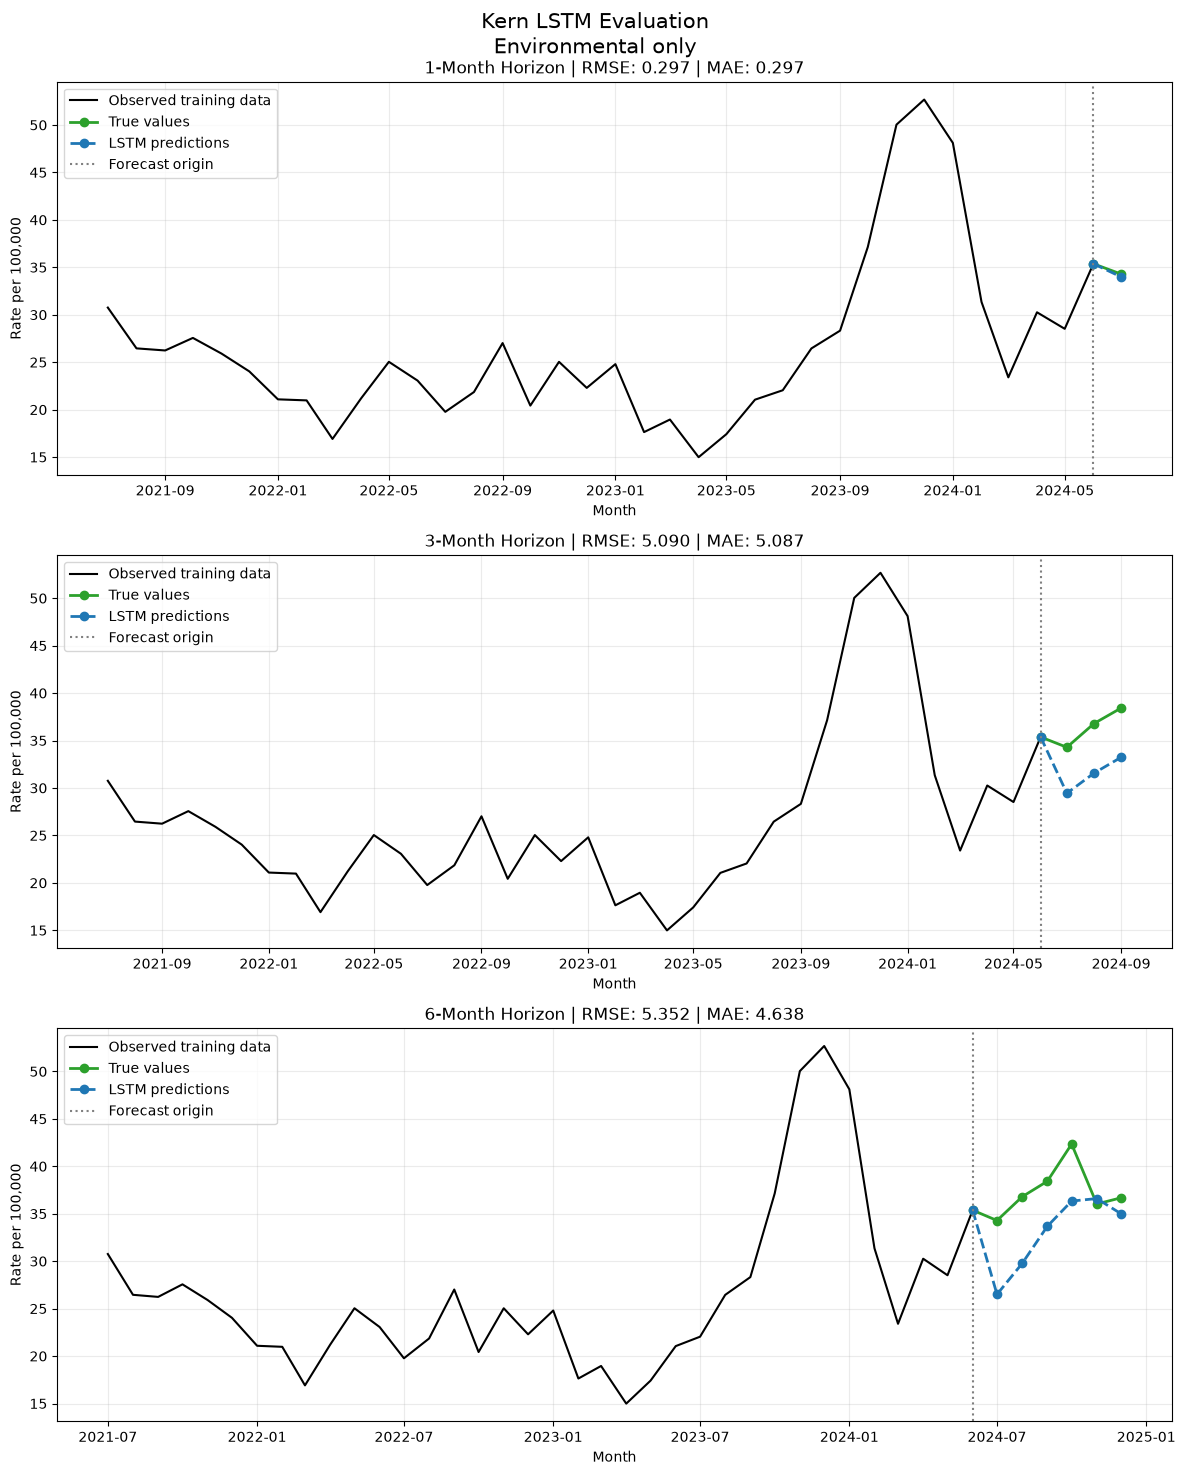


Running Los Angeles...
Los Angeles: training 1-month model...
Epoch 50/400 | Loss: 0.123616
Epoch 100/400 | Loss: 0.097764
Epoch 150/400 | Loss: 0.091599
Epoch 200/400 | Loss: 0.084764
Epoch 250/400 | Loss: 0.068672
Epoch 300/400 | Loss: 0.079243
Epoch 350/400 | Loss: 0.067080
Epoch 400/400 | Loss: 0.075172
Los Angeles: training 3-month model...
Epoch 50/400 | Loss: 0.134295
Epoch 100/400 | Loss: 0.098751
Epoch 150/400 | Loss: 0.096808
Epoch 200/400 | Loss: 0.092702
Epoch 250/400 | Loss: 0.090111
Epoch 300/400 | Loss: 0.077328
Epoch 350/400 | Loss: 0.086066
Epoch 400/400 | Loss: 0.088703
Los Angeles: training 6-month model...
Epoch 50/400 | Loss: 0.143868
Epoch 100/400 | Loss: 0.132135
Epoch 150/400 | Loss: 0.111524
Epoch 200/400 | Loss: 0.097141
Epoch 250/400 | Loss: 0.102410
Epoch 300/400 | Loss: 0.109041
Epoch 350/400 | Loss: 0.109152
Epoch 400/400 | Loss: 0.098410


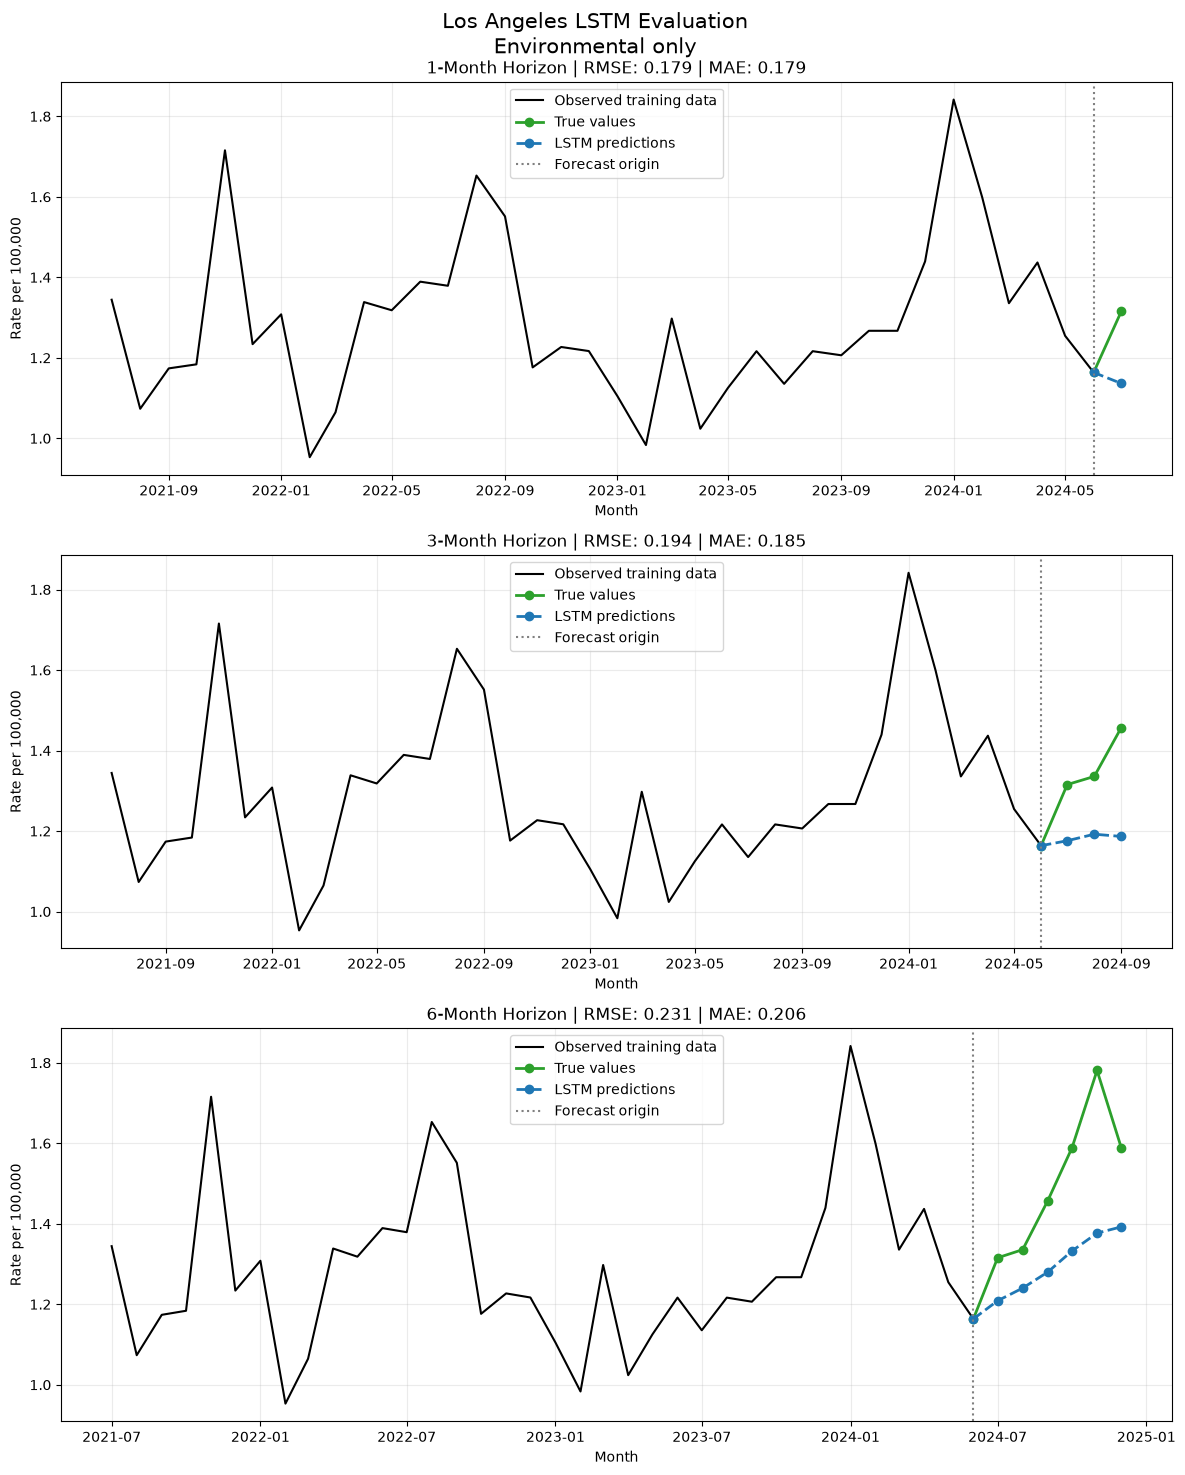


Running Orange...
Orange: training 1-month model...
Epoch 50/400 | Loss: 0.248199
Epoch 100/400 | Loss: 0.200485
Epoch 150/400 | Loss: 0.186776
Epoch 200/400 | Loss: 0.155915
Epoch 250/400 | Loss: 0.151596
Epoch 300/400 | Loss: 0.147713
Epoch 350/400 | Loss: 0.128176
Epoch 400/400 | Loss: 0.134128
Orange: training 3-month model...
Epoch 50/400 | Loss: 0.249913
Epoch 100/400 | Loss: 0.221249
Epoch 150/400 | Loss: 0.196110
Epoch 200/400 | Loss: 0.177832
Epoch 250/400 | Loss: 0.177581
Epoch 300/400 | Loss: 0.165729
Epoch 350/400 | Loss: 0.168863
Epoch 400/400 | Loss: 0.164481
Orange: training 6-month model...
Epoch 50/400 | Loss: 0.256610
Epoch 100/400 | Loss: 0.228419
Epoch 150/400 | Loss: 0.212887
Epoch 200/400 | Loss: 0.195581
Epoch 250/400 | Loss: 0.196060
Epoch 300/400 | Loss: 0.198550
Epoch 350/400 | Loss: 0.198859
Epoch 400/400 | Loss: 0.197288


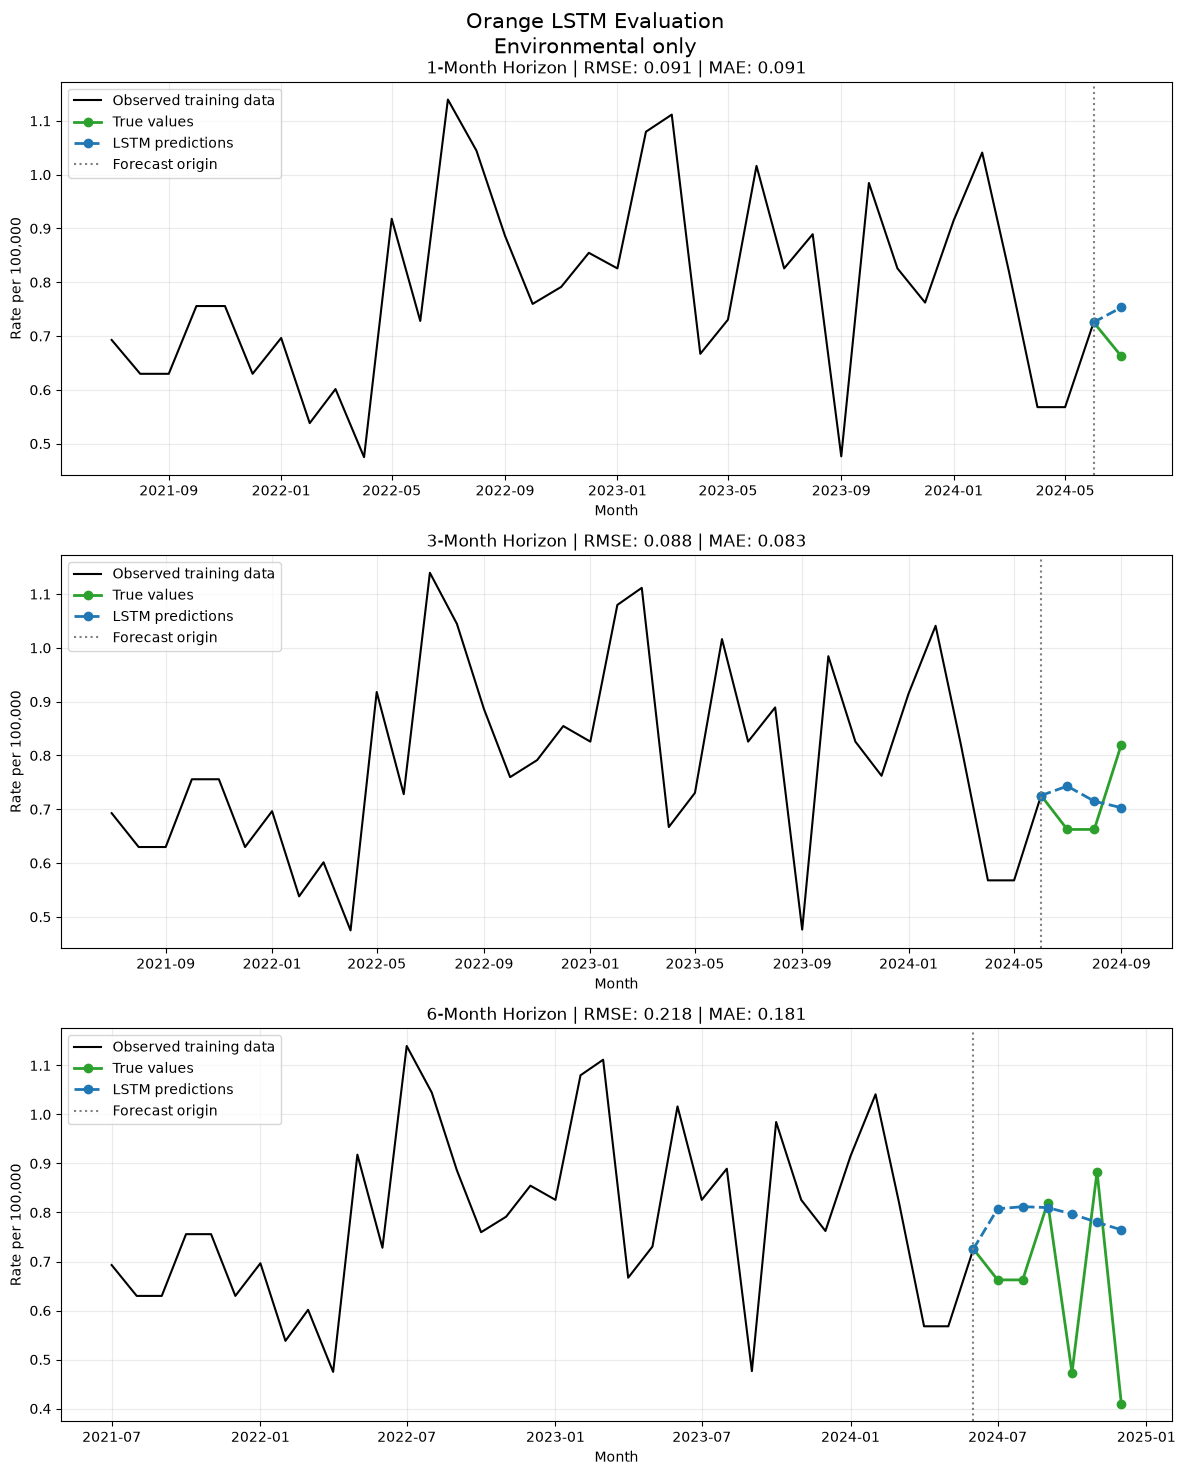


Running San Diego...
San Diego: training 1-month model...
Epoch 50/400 | Loss: 0.217811
Epoch 100/400 | Loss: 0.147171
Epoch 150/400 | Loss: 0.132344
Epoch 200/400 | Loss: 0.138185
Epoch 250/400 | Loss: 0.103315
Epoch 300/400 | Loss: 0.133802
Epoch 350/400 | Loss: 0.105066
Epoch 400/400 | Loss: 0.098943
San Diego: training 3-month model...
Epoch 50/400 | Loss: 0.238351
Epoch 100/400 | Loss: 0.185508
Epoch 150/400 | Loss: 0.160375
Epoch 200/400 | Loss: 0.143049
Epoch 250/400 | Loss: 0.155717
Epoch 300/400 | Loss: 0.150596
Epoch 350/400 | Loss: 0.144024
Epoch 400/400 | Loss: 0.145512
San Diego: training 6-month model...
Epoch 50/400 | Loss: 0.241048
Epoch 100/400 | Loss: 0.198376
Epoch 150/400 | Loss: 0.173829
Epoch 200/400 | Loss: 0.175065
Epoch 250/400 | Loss: 0.171027
Epoch 300/400 | Loss: 0.171170
Epoch 350/400 | Loss: 0.175994
Epoch 400/400 | Loss: 0.170393


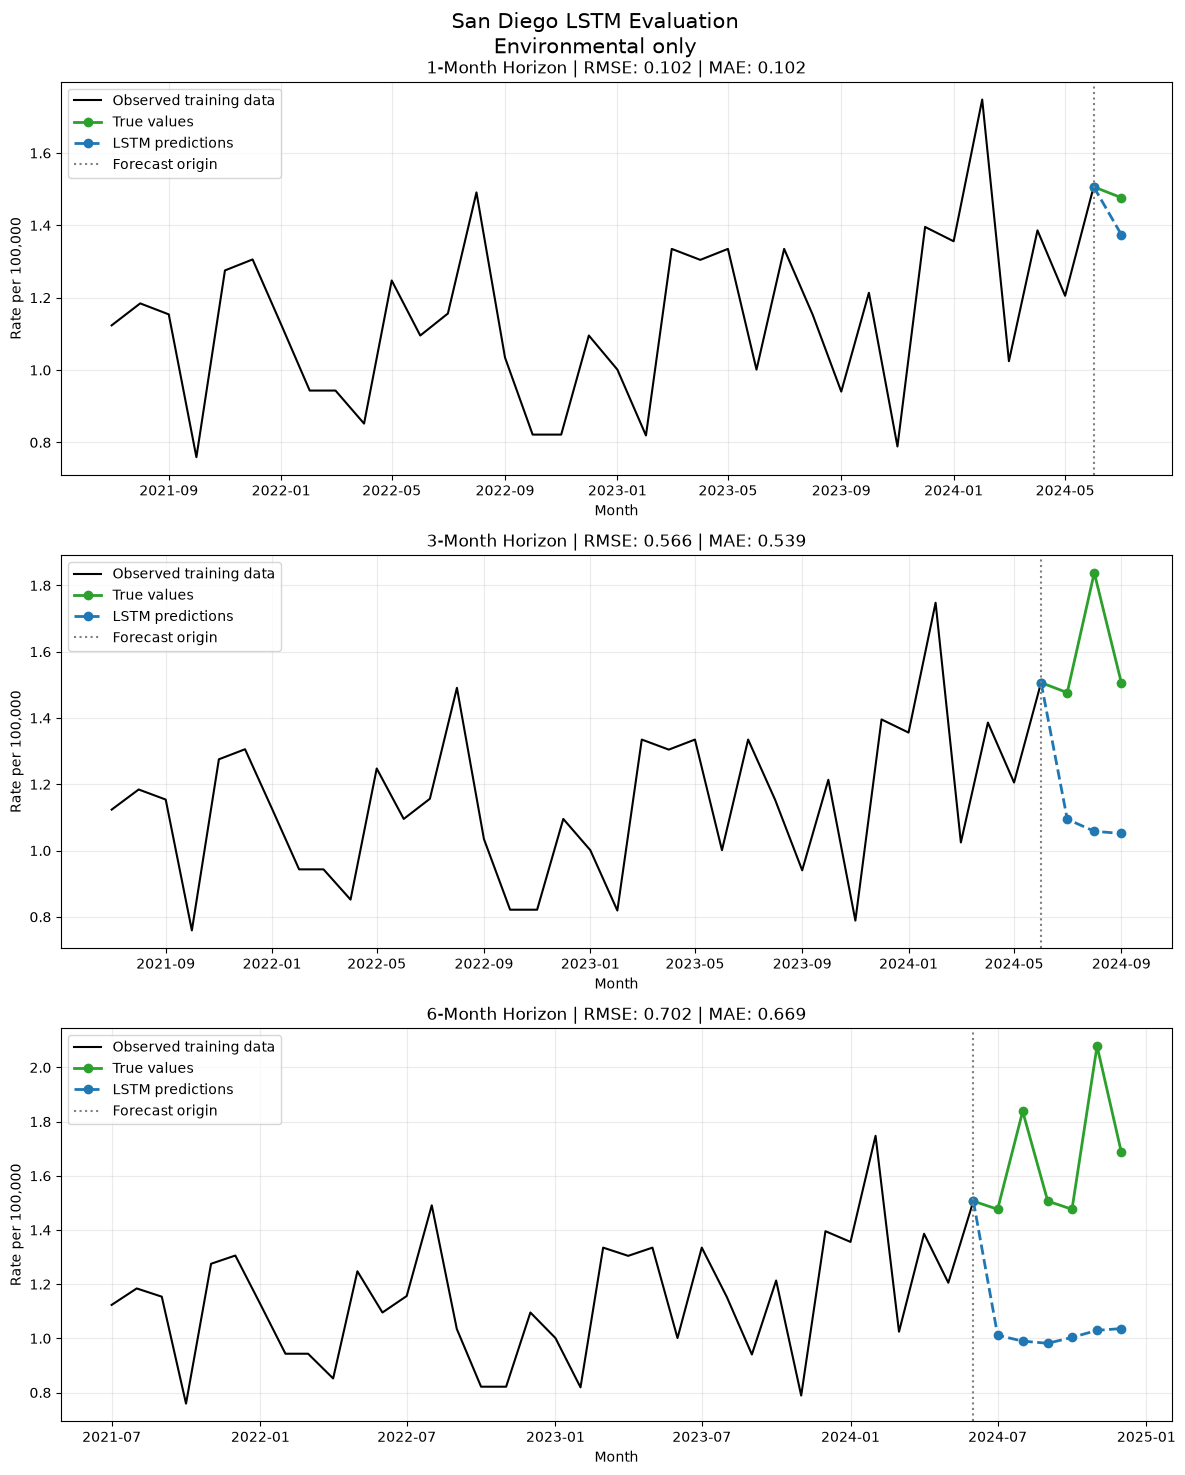


Running San Luis Obispo...
San Luis Obispo: training 1-month model...
Epoch 50/400 | Loss: 0.258738
Epoch 100/400 | Loss: 0.203707
Epoch 150/400 | Loss: 0.182755
Epoch 200/400 | Loss: 0.182160
Epoch 250/400 | Loss: 0.173356
Epoch 300/400 | Loss: 0.149984
Epoch 350/400 | Loss: 0.157175
Epoch 400/400 | Loss: 0.154458
San Luis Obispo: training 3-month model...
Epoch 50/400 | Loss: 0.300198
Epoch 100/400 | Loss: 0.262917
Epoch 150/400 | Loss: 0.219757
Epoch 200/400 | Loss: 0.199176
Epoch 250/400 | Loss: 0.211234
Epoch 300/400 | Loss: 0.194994
Epoch 350/400 | Loss: 0.187000
Epoch 400/400 | Loss: 0.199425
San Luis Obispo: training 6-month model...
Epoch 50/400 | Loss: 0.315993
Epoch 100/400 | Loss: 0.274105
Epoch 150/400 | Loss: 0.245163
Epoch 200/400 | Loss: 0.242311
Epoch 250/400 | Loss: 0.222658
Epoch 300/400 | Loss: 0.240630
Epoch 350/400 | Loss: 0.235226
Epoch 400/400 | Loss: 0.211782


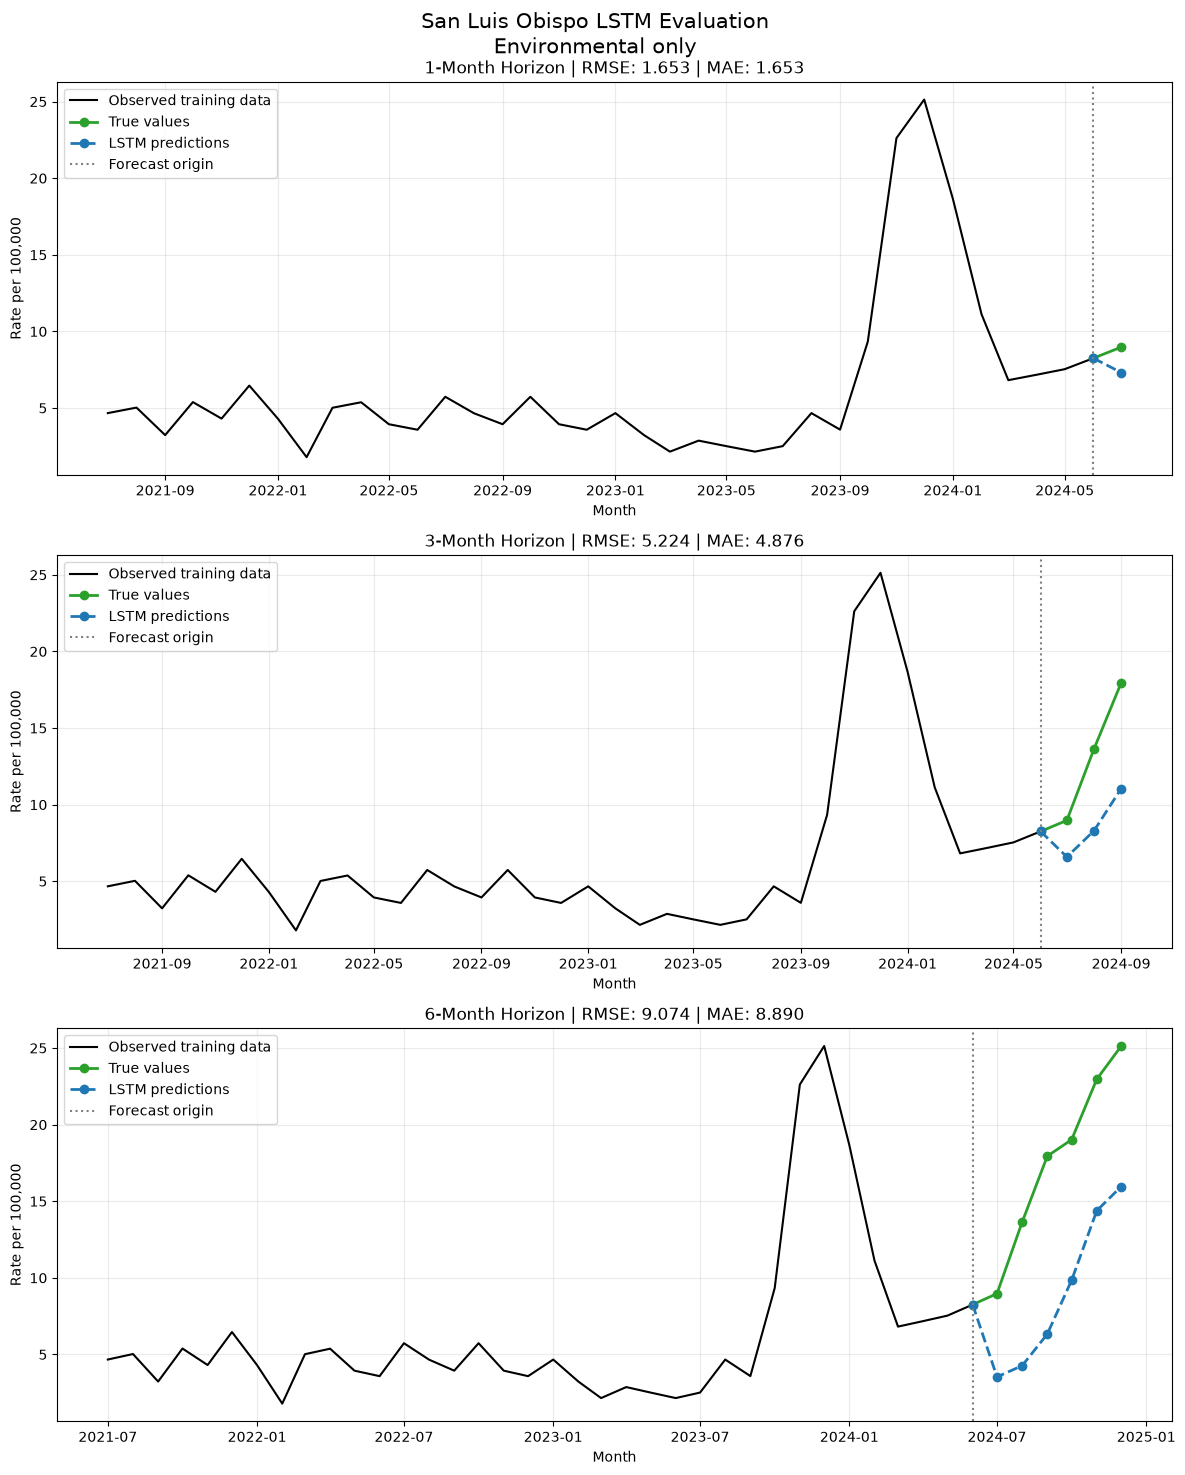


Running Tulare...
Tulare: training 1-month model...
Epoch 50/400 | Loss: 0.345602
Epoch 100/400 | Loss: 0.254998
Epoch 150/400 | Loss: 0.233531
Epoch 200/400 | Loss: 0.215147
Epoch 250/400 | Loss: 0.189503
Epoch 300/400 | Loss: 0.163314
Epoch 350/400 | Loss: 0.159932
Epoch 400/400 | Loss: 0.177916
Tulare: training 3-month model...
Epoch 50/400 | Loss: 0.364861
Epoch 100/400 | Loss: 0.277871
Epoch 150/400 | Loss: 0.255584
Epoch 200/400 | Loss: 0.224902
Epoch 250/400 | Loss: 0.229536
Epoch 300/400 | Loss: 0.200676
Epoch 350/400 | Loss: 0.215574
Epoch 400/400 | Loss: 0.220872
Tulare: training 6-month model...
Epoch 50/400 | Loss: 0.408753
Epoch 100/400 | Loss: 0.312293
Epoch 150/400 | Loss: 0.284602
Epoch 200/400 | Loss: 0.262165
Epoch 250/400 | Loss: 0.253017
Epoch 300/400 | Loss: 0.273035
Epoch 350/400 | Loss: 0.258321
Epoch 400/400 | Loss: 0.233864


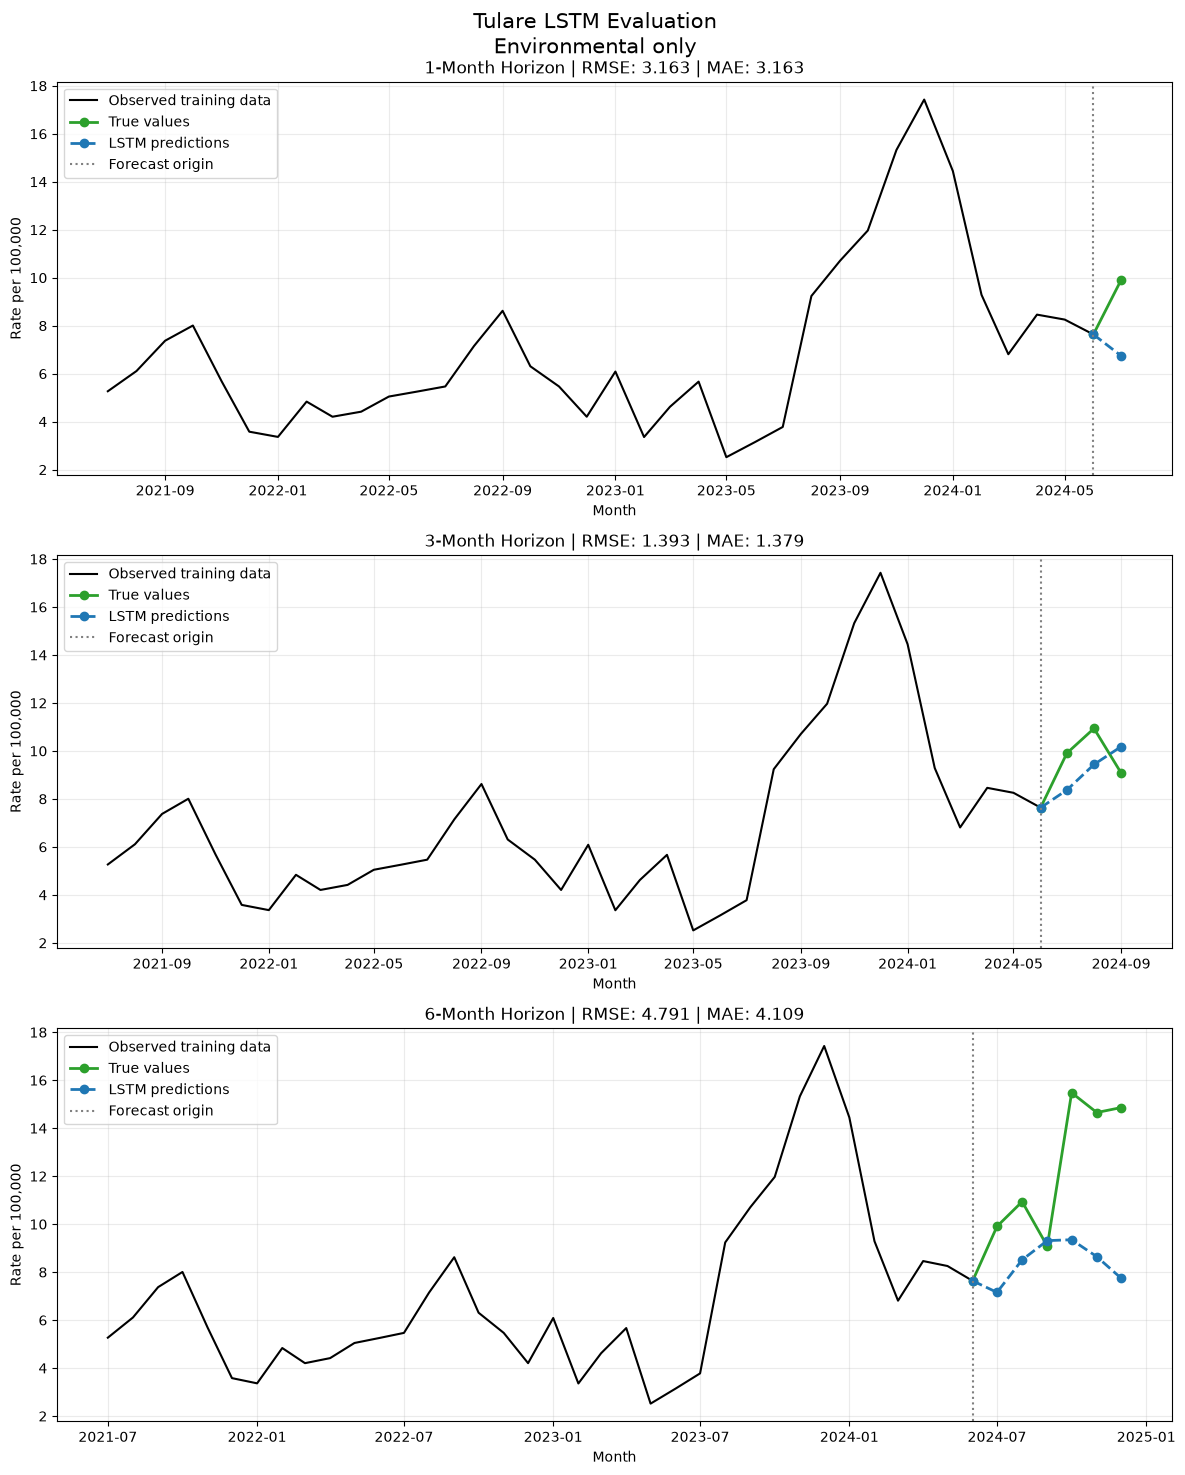


Running Ventura...
Ventura: training 1-month model...
Epoch 50/400 | Loss: 0.250652
Epoch 100/400 | Loss: 0.161095
Epoch 150/400 | Loss: 0.162608
Epoch 200/400 | Loss: 0.139554
Epoch 250/400 | Loss: 0.133324
Epoch 300/400 | Loss: 0.116530
Epoch 350/400 | Loss: 0.112508
Epoch 400/400 | Loss: 0.131211
Ventura: training 3-month model...
Epoch 50/400 | Loss: 0.261079
Epoch 100/400 | Loss: 0.203679
Epoch 150/400 | Loss: 0.195388
Epoch 200/400 | Loss: 0.170144
Epoch 250/400 | Loss: 0.176293
Epoch 300/400 | Loss: 0.165019
Epoch 350/400 | Loss: 0.157301
Epoch 400/400 | Loss: 0.164863
Ventura: training 6-month model...
Epoch 50/400 | Loss: 0.310495
Epoch 100/400 | Loss: 0.236216
Epoch 150/400 | Loss: 0.204460
Epoch 200/400 | Loss: 0.189971
Epoch 250/400 | Loss: 0.172281
Epoch 300/400 | Loss: 0.189434
Epoch 350/400 | Loss: 0.173137
Epoch 400/400 | Loss: 0.191828


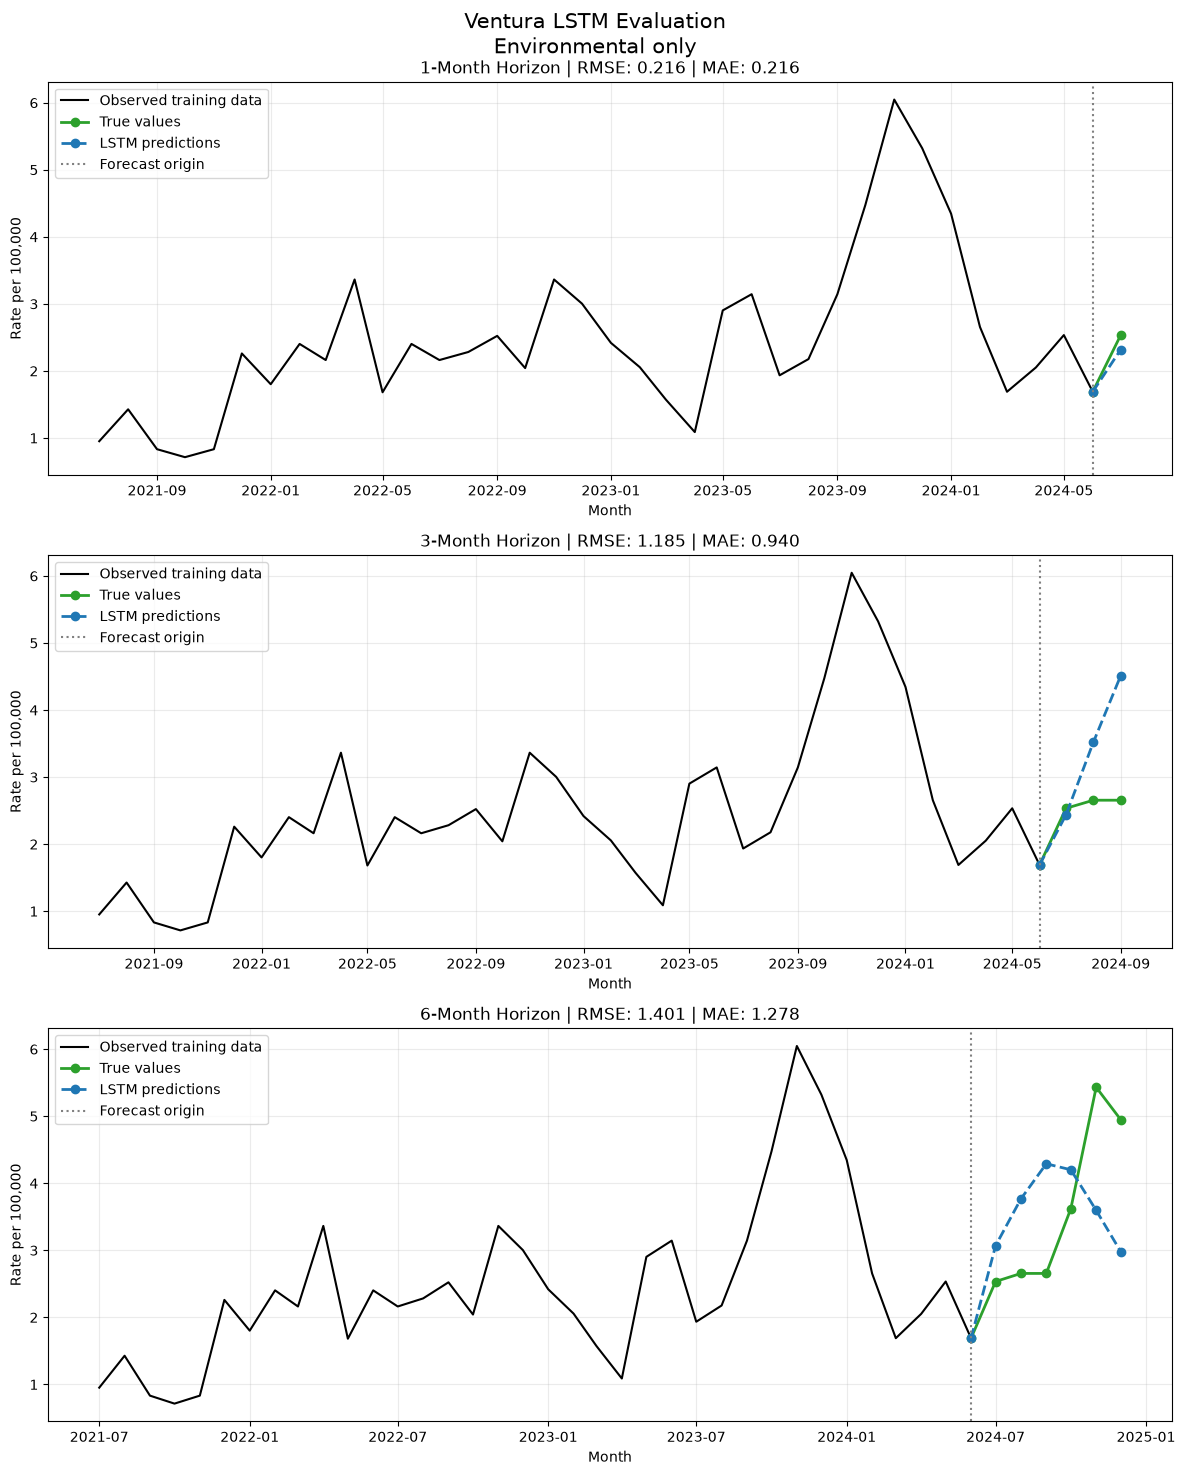

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Sequences,Lookback,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Hidden_Size,Number_Layers,Dropout,Epochs,Learning_Rate,Weight_Decay,Batch_Size,Final_Training_Loss
0,Fresno,Environmental only,2024-06-01,1,1,203,12,13,1.162495,1.162495,False,True,16,1,0.4,400,0.001,0.00001,32,0.108331
1,Fresno,Environmental only,2024-06-01,3,3,201,12,13,1.973393,1.933578,False,True,16,1,0.4,400,0.001,0.00001,32,0.179338
2,Fresno,Environmental only,2024-06-01,6,6,198,12,13,2.990003,2.891561,False,True,16,1,0.4,400,0.001,0.00001,32,0.202746
3,Kern,Environmental only,2024-06-01,1,1,203,12,13,0.296522,0.296522,False,True,16,1,0.4,400,0.001,0.00001,32,0.079819
4,Kern,Environmental only,2024-06-01,3,3,201,12,13,5.090368,5.087400,False,True,16,1,0.4,400,0.001,0.00001,32,0.141343
5,Kern,Environmental only,2024-06-01,6,6,198,12,13,5.351632,4.638308,False,True,16,1,0.4,400,0.001,0.00001,32,0.145833
6,Los Angeles,Environmental only,2024-06-01,1,1,203,12,13,0.179094,0.179094,False,True,16,1,0.4,400,0.001,0.00001,32,0.075172
7,Los Angeles,Environmental only,2024-06-01,3,3,201,12,13,0.194291,0.184526,False,True,16,1,0.4,400,0.001,0.00001,32,0.088703
8,Los Angeles,Environmental only,2024-06-01,6,6,198,12,13,0.230744,0.206035,False,True,16,1,0.4,400,0.001,0.00001,32,0.098410
9,Orange,Environmental only,2024-06-01,1,1,203,12,13,0.090675,0.090675,False,True,16,1,0.4,400,0.001,0.00001,32,0.134128


RMSE                           MAE                    
Forecast_Horizon         1         3         6         1         3         6
County                                                                      
Fresno            1.162495  1.973393  2.990003  1.162495  1.933578  2.891561
Kern              0.296522  5.090368  5.351632  0.296522  5.087400  4.638308
Los Angeles       0.179094  0.194291  0.230744  0.179094  0.184526  0.206035
Orange            0.090675  0.087559  0.217735  0.090675  0.083446  0.180993
San Diego         0.101930  0.566014  0.702475  0.101930  0.538962  0.668686
San Luis Obispo   1.653341  5.223551  9.073930  1.653341  4.875914  8.890037
Tulare            3.162852  1.392872  4.791140  3.162852  1.378645  4.109141
Ventura           0.216172  1.184536  1.400916  0.216172  0.940001  1.277567

In [29]:
all_lstm_environment_only = run_lstm_all_counties(
    counties=counties,
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config= {
        "lookback": 12,
        "use_rate_features": False,
        "use_log_target": True,
        "include_calendar_features": True,
    },
    lstm_parameters=lstm_parameters,
    output_dir=output_dir,
    show_plots=True,
)

display(all_lstm_environment_only["metrics"])
display(all_lstm_environment_only["metric_summary"])

In [32]:
lstm_parameters

{'hidden_size': 16,
 'num_layers': 1,
 'dropout': 0.4,
 'epochs': 400,
 'learning_rate': 0.001,
 'weight_decay': 1e-05,
 'batch_size': 32,
 'seed': 42,
 'device': 'auto',
 'verbose_every': 50}


Running Fresno...
Fresno: training 1-month model...
Epoch 50/400 | Loss: 0.294713
Epoch 100/400 | Loss: 0.174889
Epoch 150/400 | Loss: 0.139425
Epoch 200/400 | Loss: 0.130449
Epoch 250/400 | Loss: 0.106795
Epoch 300/400 | Loss: 0.123191
Epoch 350/400 | Loss: 0.100027
Epoch 400/400 | Loss: 0.113768
Fresno: training 3-month model...
Epoch 50/400 | Loss: 0.336327
Epoch 100/400 | Loss: 0.222568
Epoch 150/400 | Loss: 0.190027
Epoch 200/400 | Loss: 0.165579
Epoch 250/400 | Loss: 0.171489
Epoch 300/400 | Loss: 0.148885
Epoch 350/400 | Loss: 0.162728
Epoch 400/400 | Loss: 0.152458
Fresno: training 6-month model...
Epoch 50/400 | Loss: 0.317277
Epoch 100/400 | Loss: 0.261026
Epoch 150/400 | Loss: 0.217518
Epoch 200/400 | Loss: 0.201352
Epoch 250/400 | Loss: 0.193522
Epoch 300/400 | Loss: 0.185853
Epoch 350/400 | Loss: 0.223819
Epoch 400/400 | Loss: 0.191748


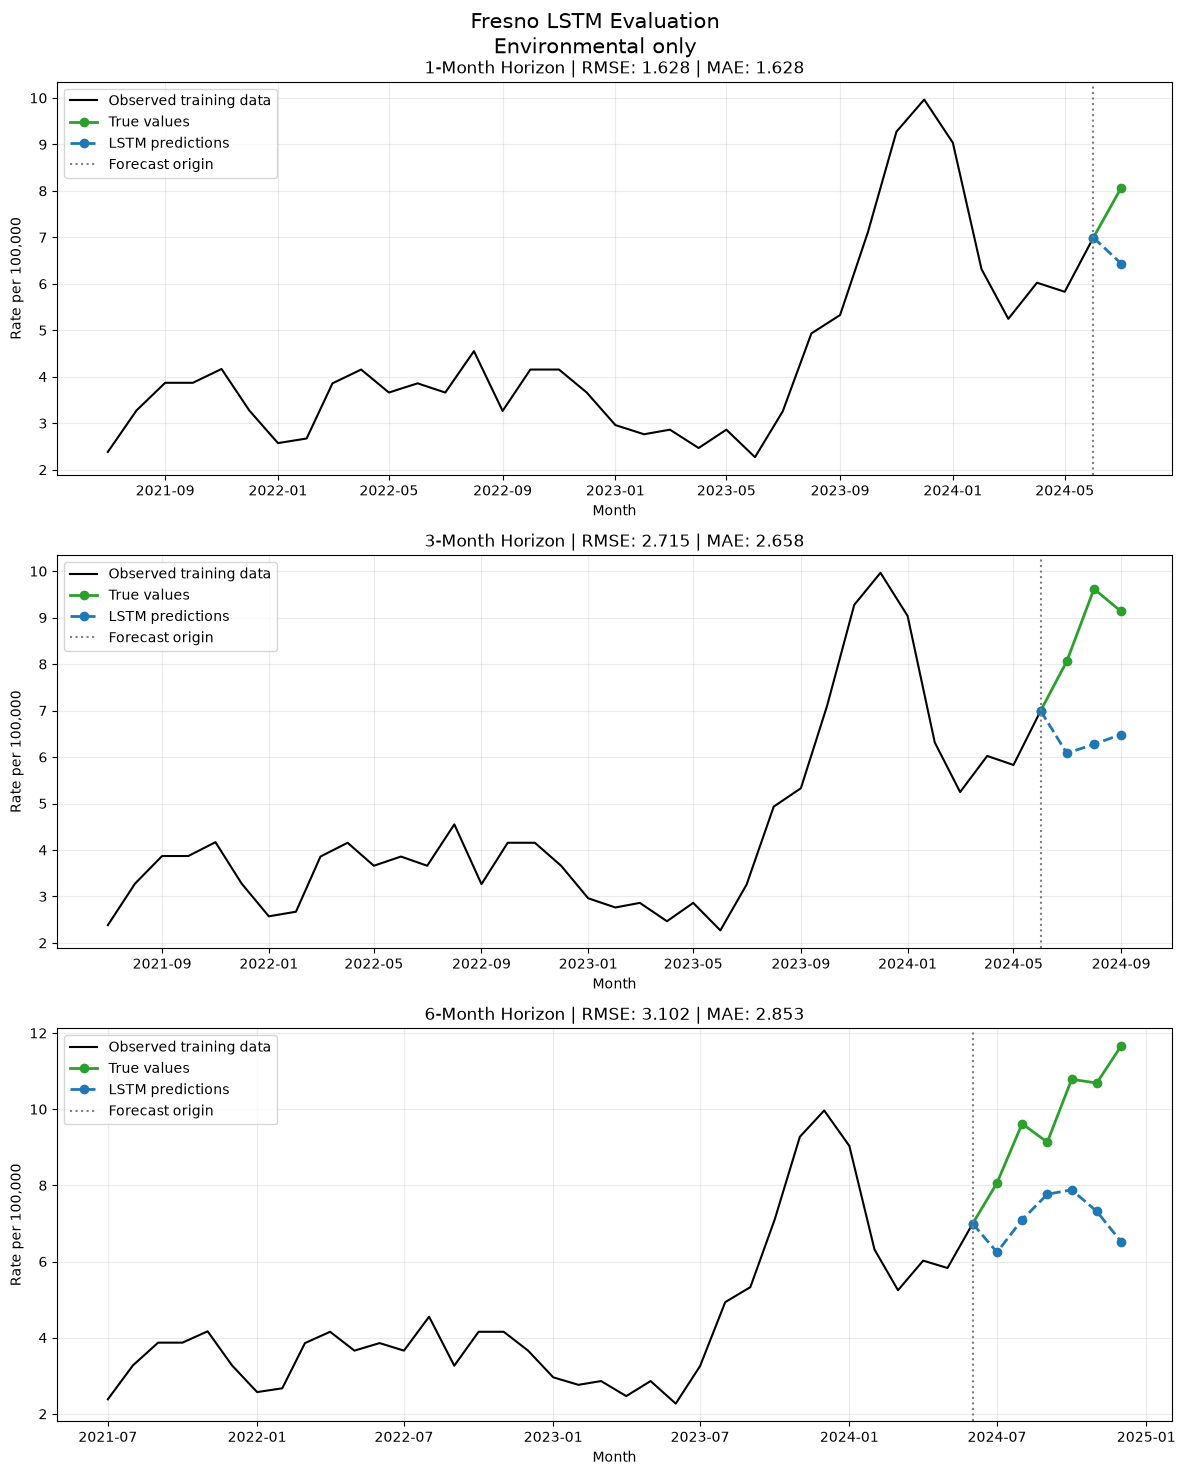


Running Kern...
Kern: training 1-month model...
Epoch 50/400 | Loss: 0.194377
Epoch 100/400 | Loss: 0.155206
Epoch 150/400 | Loss: 0.123595
Epoch 200/400 | Loss: 0.132475
Epoch 250/400 | Loss: 0.108951
Epoch 300/400 | Loss: 0.107162
Epoch 350/400 | Loss: 0.107313
Epoch 400/400 | Loss: 0.094015
Kern: training 3-month model...
Epoch 50/400 | Loss: 0.225410
Epoch 100/400 | Loss: 0.178338
Epoch 150/400 | Loss: 0.159119
Epoch 200/400 | Loss: 0.140517
Epoch 250/400 | Loss: 0.152203
Epoch 300/400 | Loss: 0.142480
Epoch 350/400 | Loss: 0.129008
Epoch 400/400 | Loss: 0.153374
Kern: training 6-month model...
Epoch 50/400 | Loss: 0.278172
Epoch 100/400 | Loss: 0.242778
Epoch 150/400 | Loss: 0.191849
Epoch 200/400 | Loss: 0.192689
Epoch 250/400 | Loss: 0.180821
Epoch 300/400 | Loss: 0.181930
Epoch 350/400 | Loss: 0.180431
Epoch 400/400 | Loss: 0.161332


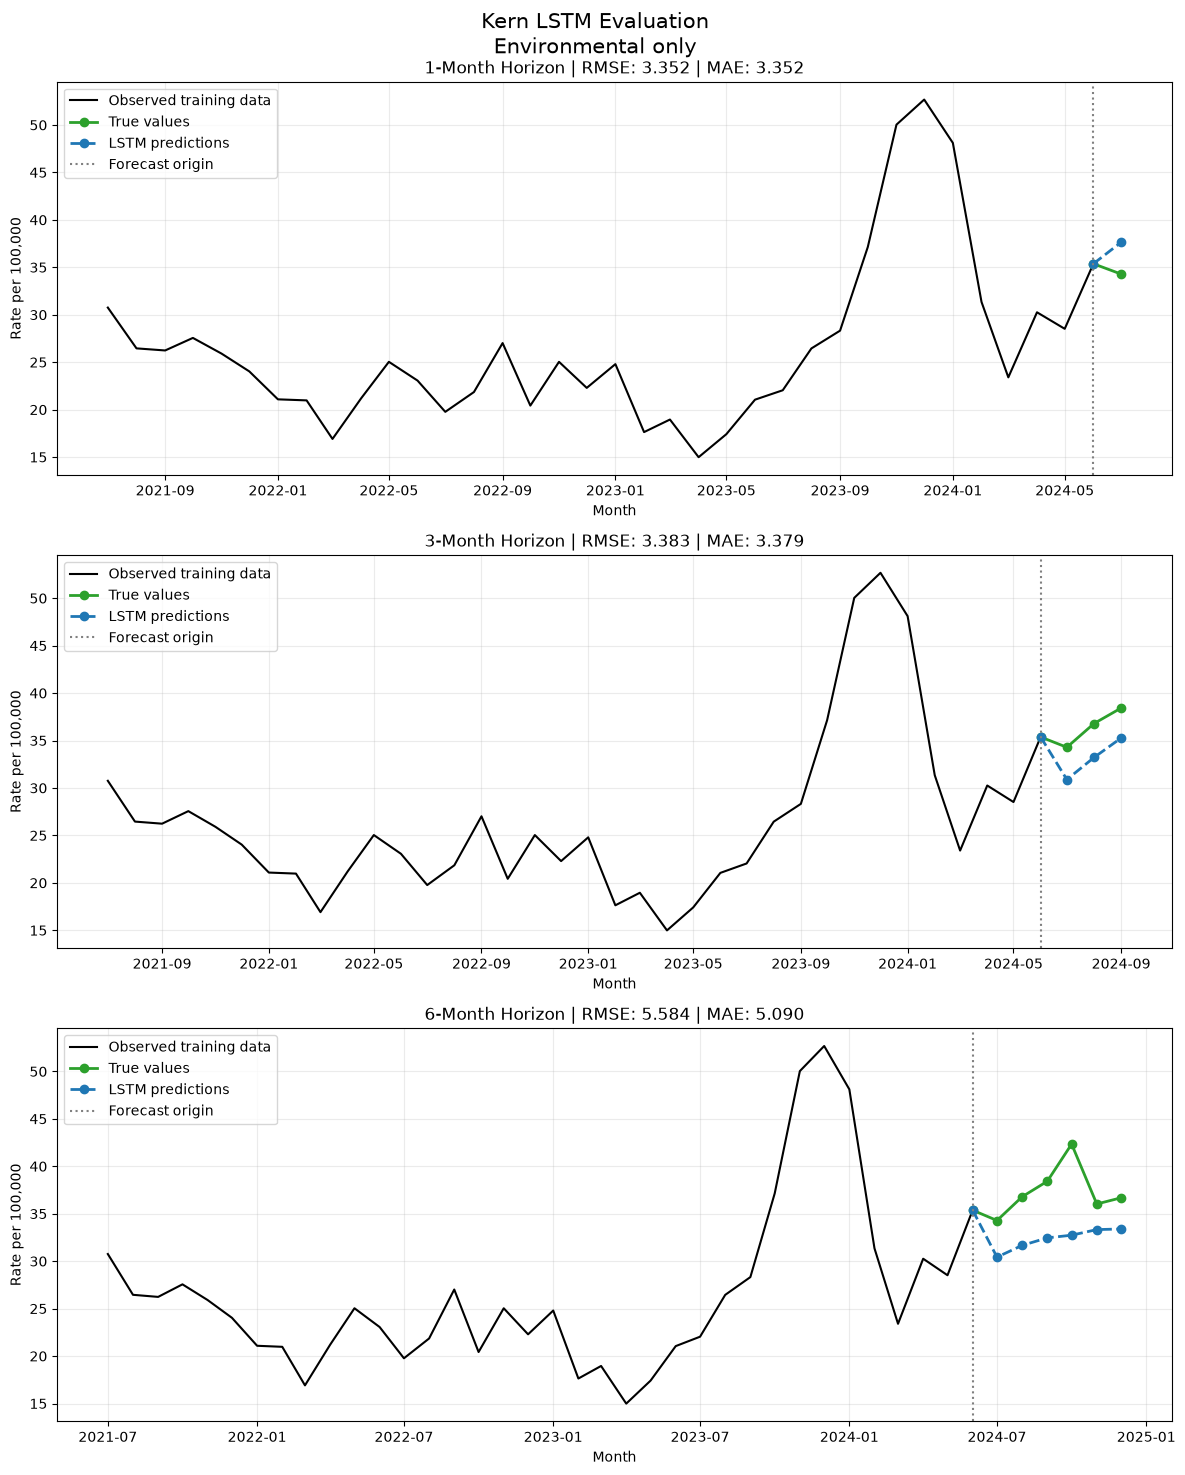


Running Los Angeles...
Los Angeles: training 1-month model...
Epoch 50/400 | Loss: 0.129704
Epoch 100/400 | Loss: 0.100768
Epoch 150/400 | Loss: 0.095472
Epoch 200/400 | Loss: 0.085962
Epoch 250/400 | Loss: 0.067292
Epoch 300/400 | Loss: 0.081138
Epoch 350/400 | Loss: 0.067504
Epoch 400/400 | Loss: 0.077336
Los Angeles: training 3-month model...
Epoch 50/400 | Loss: 0.142469
Epoch 100/400 | Loss: 0.107589
Epoch 150/400 | Loss: 0.102437
Epoch 200/400 | Loss: 0.102717
Epoch 250/400 | Loss: 0.097995
Epoch 300/400 | Loss: 0.086244
Epoch 350/400 | Loss: 0.093891
Epoch 400/400 | Loss: 0.095491
Los Angeles: training 6-month model...
Epoch 50/400 | Loss: 0.159822
Epoch 100/400 | Loss: 0.145953
Epoch 150/400 | Loss: 0.122102
Epoch 200/400 | Loss: 0.106467
Epoch 250/400 | Loss: 0.113136
Epoch 300/400 | Loss: 0.121402
Epoch 350/400 | Loss: 0.119028
Epoch 400/400 | Loss: 0.107649


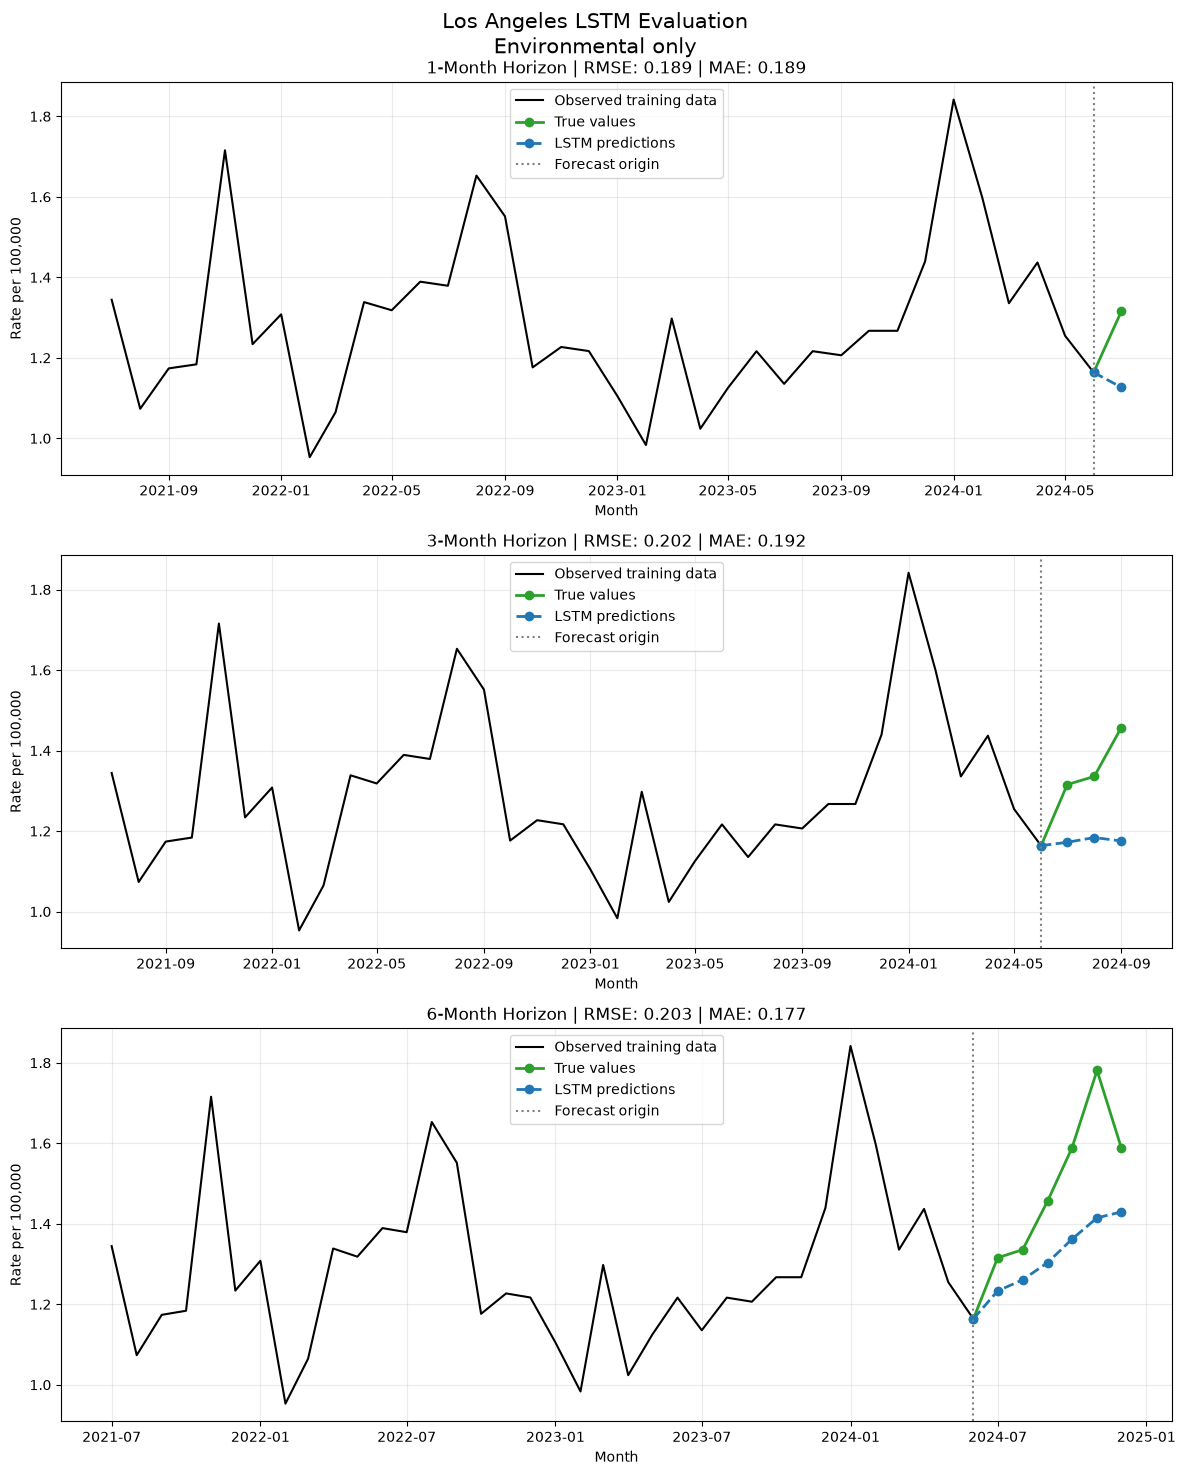


Running Orange...
Orange: training 1-month model...
Epoch 50/400 | Loss: 0.253554
Epoch 100/400 | Loss: 0.204415
Epoch 150/400 | Loss: 0.192687
Epoch 200/400 | Loss: 0.160506
Epoch 250/400 | Loss: 0.152879
Epoch 300/400 | Loss: 0.147420
Epoch 350/400 | Loss: 0.130314
Epoch 400/400 | Loss: 0.136371
Orange: training 3-month model...
Epoch 50/400 | Loss: 0.261329
Epoch 100/400 | Loss: 0.232160
Epoch 150/400 | Loss: 0.195497
Epoch 200/400 | Loss: 0.187335
Epoch 250/400 | Loss: 0.175594
Epoch 300/400 | Loss: 0.167380
Epoch 350/400 | Loss: 0.173494
Epoch 400/400 | Loss: 0.165891
Orange: training 6-month model...
Epoch 50/400 | Loss: 0.281104
Epoch 100/400 | Loss: 0.246299
Epoch 150/400 | Loss: 0.223438
Epoch 200/400 | Loss: 0.203213
Epoch 250/400 | Loss: 0.203845
Epoch 300/400 | Loss: 0.205999
Epoch 350/400 | Loss: 0.208765
Epoch 400/400 | Loss: 0.205783


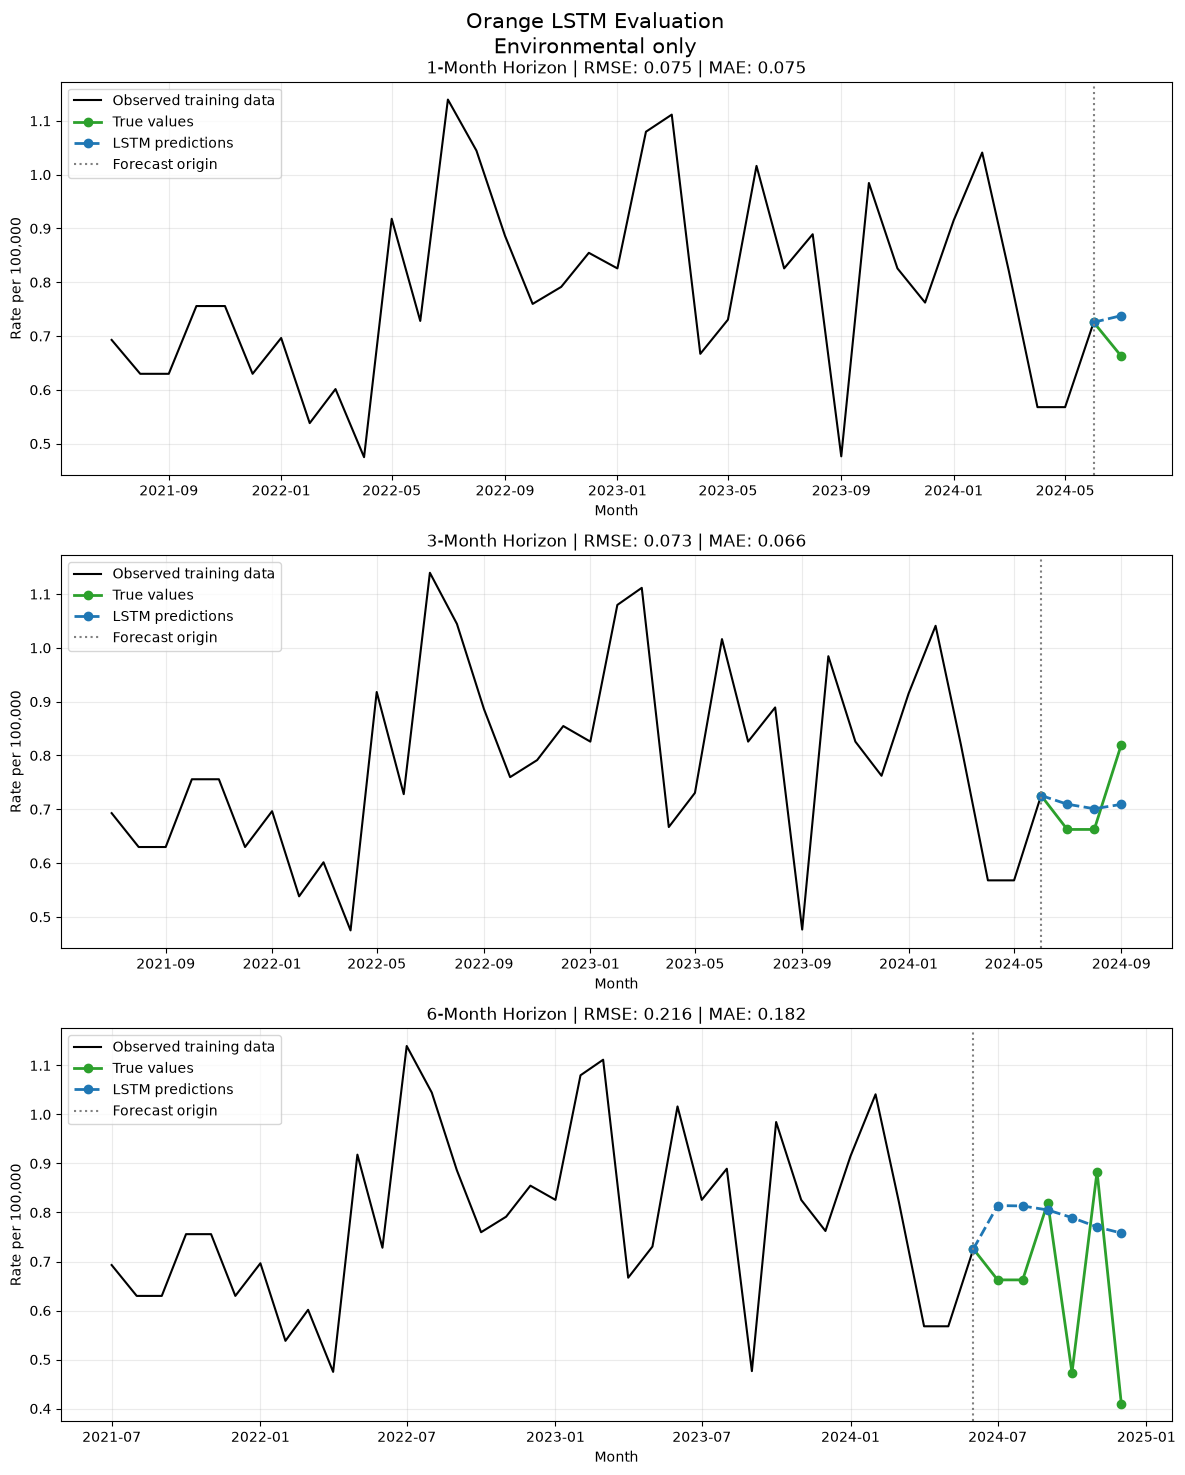


Running San Diego...
San Diego: training 1-month model...
Epoch 50/400 | Loss: 0.232886
Epoch 100/400 | Loss: 0.149503
Epoch 150/400 | Loss: 0.125645
Epoch 200/400 | Loss: 0.133127
Epoch 250/400 | Loss: 0.104490
Epoch 300/400 | Loss: 0.132002
Epoch 350/400 | Loss: 0.105271
Epoch 400/400 | Loss: 0.102356
San Diego: training 3-month model...
Epoch 50/400 | Loss: 0.244020
Epoch 100/400 | Loss: 0.194789
Epoch 150/400 | Loss: 0.165441
Epoch 200/400 | Loss: 0.148611
Epoch 250/400 | Loss: 0.159200
Epoch 300/400 | Loss: 0.157117
Epoch 350/400 | Loss: 0.151190
Epoch 400/400 | Loss: 0.155820
San Diego: training 6-month model...
Epoch 50/400 | Loss: 0.248587
Epoch 100/400 | Loss: 0.205275
Epoch 150/400 | Loss: 0.180315
Epoch 200/400 | Loss: 0.184068
Epoch 250/400 | Loss: 0.175658
Epoch 300/400 | Loss: 0.179688
Epoch 350/400 | Loss: 0.181823
Epoch 400/400 | Loss: 0.176945


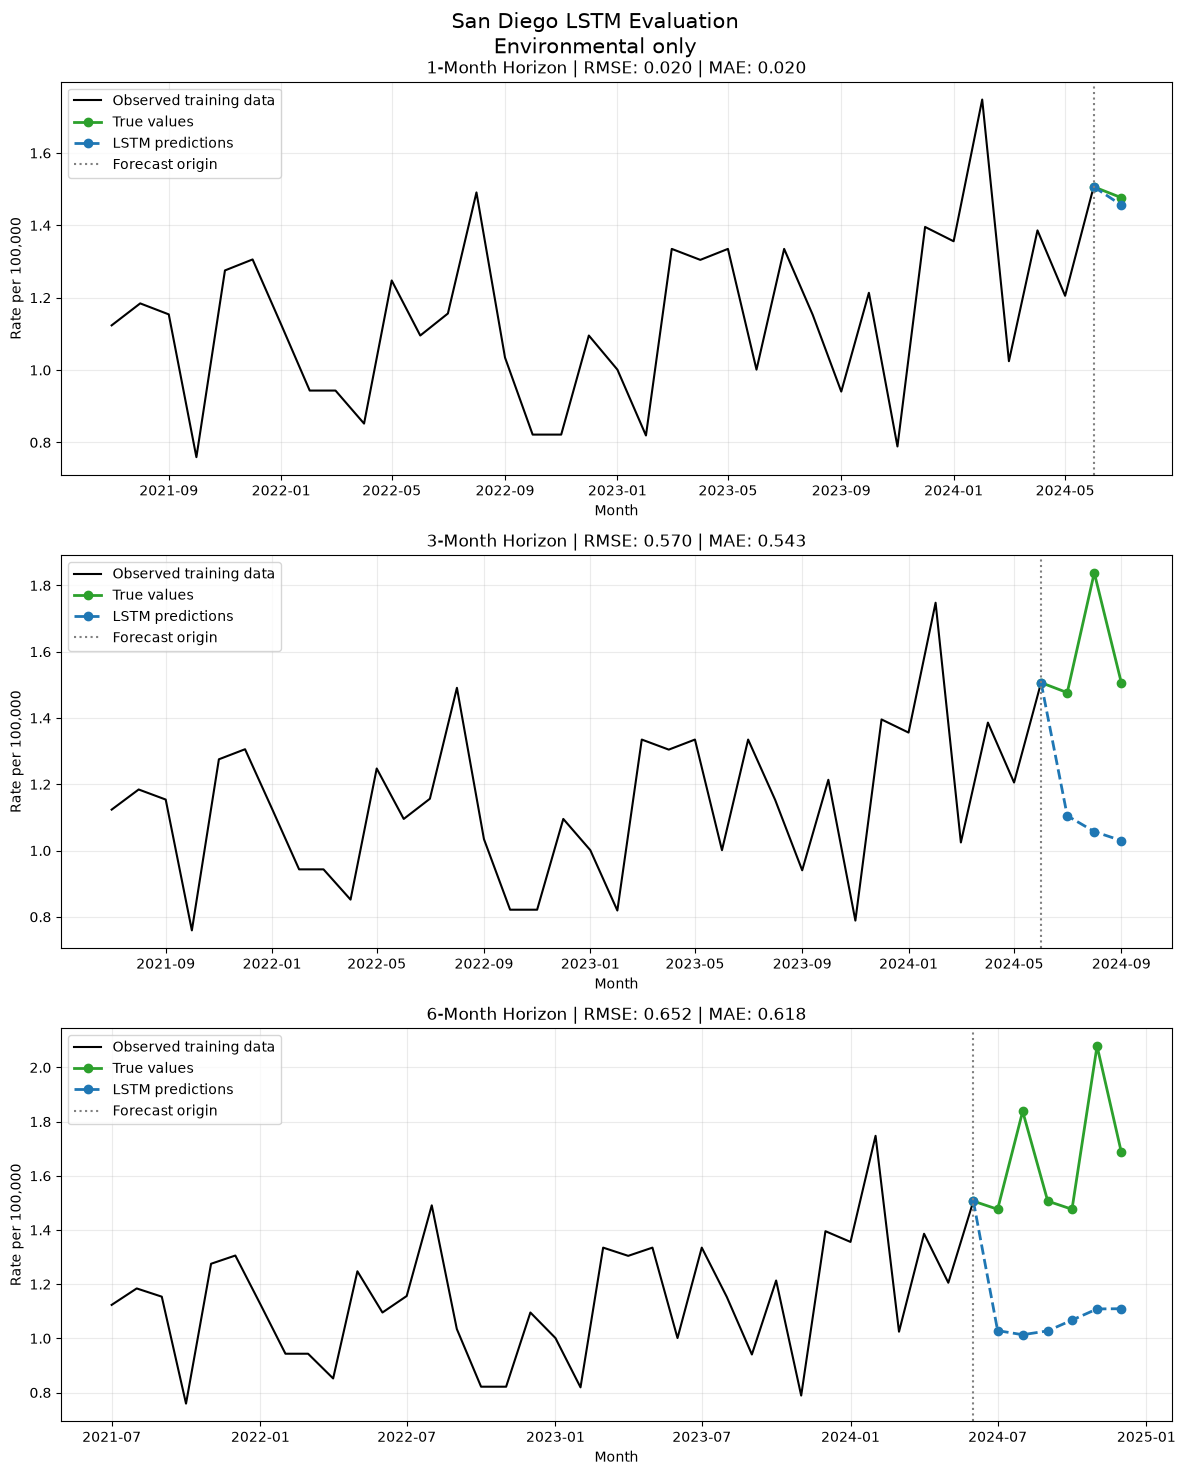


Running San Luis Obispo...
San Luis Obispo: training 1-month model...
Epoch 50/400 | Loss: 0.268683
Epoch 100/400 | Loss: 0.145671
Epoch 150/400 | Loss: 0.140382
Epoch 200/400 | Loss: 0.119903
Epoch 250/400 | Loss: 0.103154
Epoch 300/400 | Loss: 0.122191
Epoch 350/400 | Loss: 0.096779
Epoch 400/400 | Loss: 0.151708
San Luis Obispo: training 3-month model...
Epoch 50/400 | Loss: 0.364733
Epoch 100/400 | Loss: 0.217817
Epoch 150/400 | Loss: 0.196096
Epoch 200/400 | Loss: 0.163203
Epoch 250/400 | Loss: 0.207393
Epoch 300/400 | Loss: 0.164044
Epoch 350/400 | Loss: 0.152534
Epoch 400/400 | Loss: 0.147239
San Luis Obispo: training 6-month model...
Epoch 50/400 | Loss: 0.341742
Epoch 100/400 | Loss: 0.263308
Epoch 150/400 | Loss: 0.221194
Epoch 200/400 | Loss: 0.208090
Epoch 250/400 | Loss: 0.203298
Epoch 300/400 | Loss: 0.228659
Epoch 350/400 | Loss: 0.204672
Epoch 400/400 | Loss: 0.192000


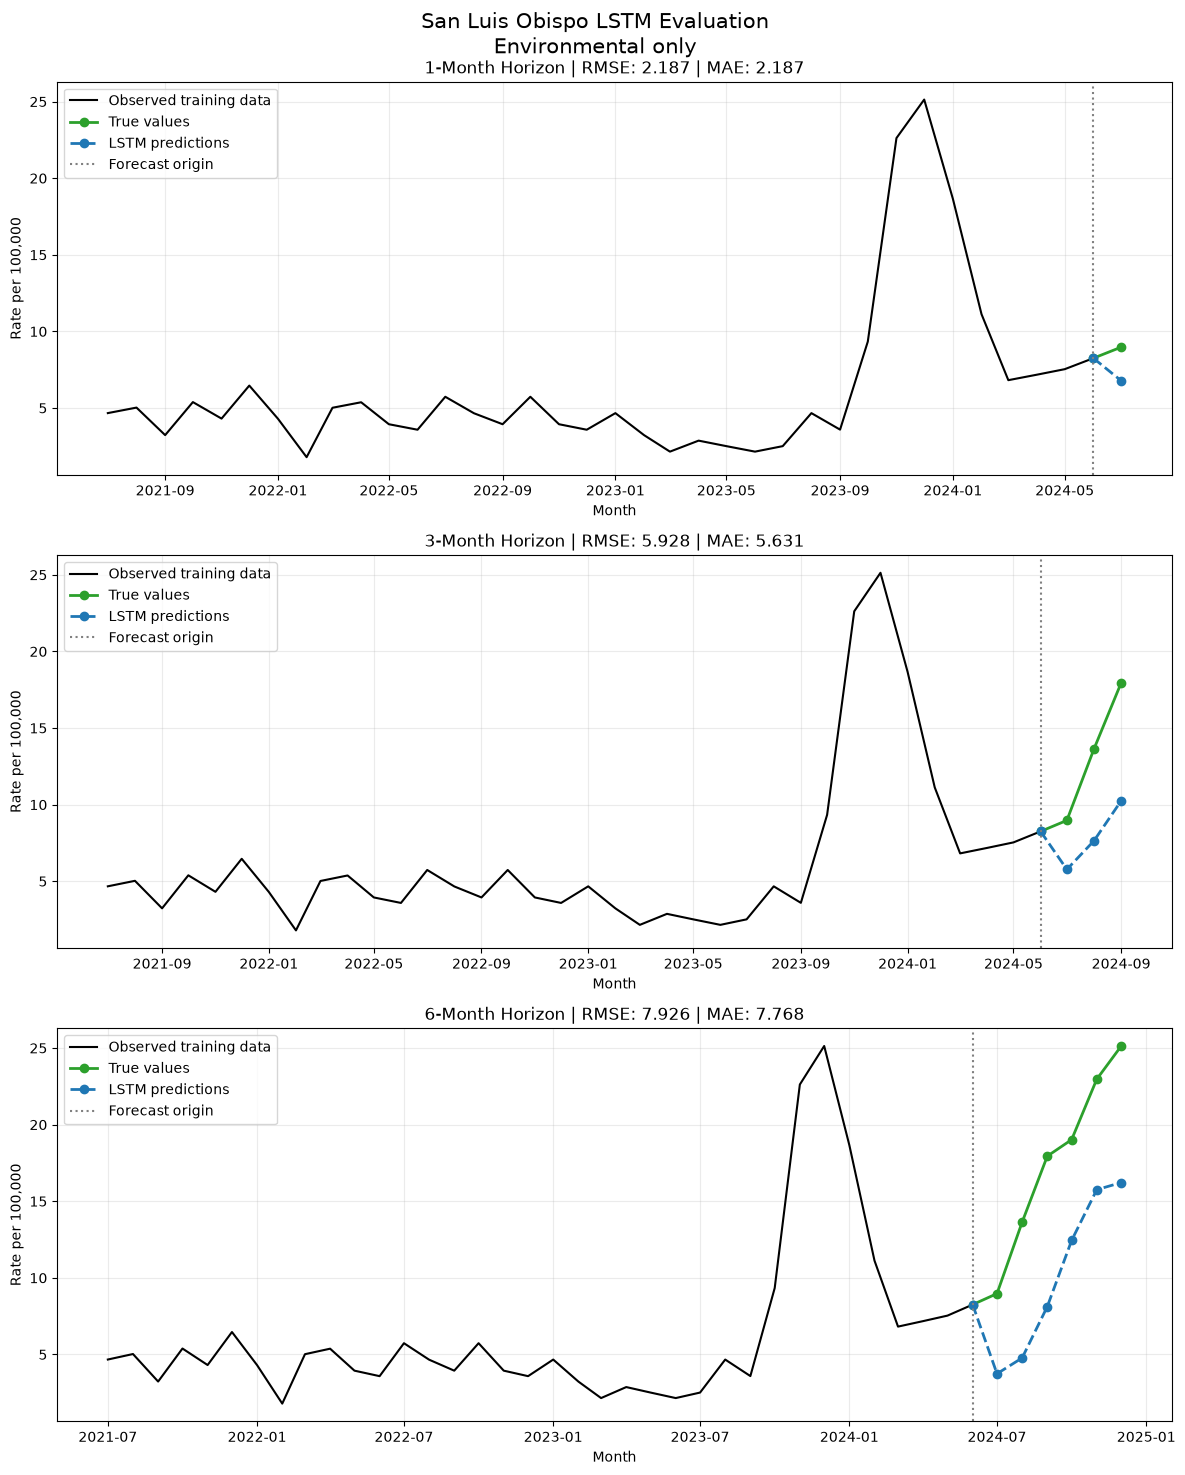


Running Tulare...
Tulare: training 1-month model...
Epoch 50/400 | Loss: 0.322052
Epoch 100/400 | Loss: 0.201493
Epoch 150/400 | Loss: 0.204458
Epoch 200/400 | Loss: 0.169403
Epoch 250/400 | Loss: 0.163153
Epoch 300/400 | Loss: 0.145119
Epoch 350/400 | Loss: 0.149708
Epoch 400/400 | Loss: 0.130452
Tulare: training 3-month model...
Epoch 50/400 | Loss: 0.340068
Epoch 100/400 | Loss: 0.240492
Epoch 150/400 | Loss: 0.214174
Epoch 200/400 | Loss: 0.197390
Epoch 250/400 | Loss: 0.225405
Epoch 300/400 | Loss: 0.177520
Epoch 350/400 | Loss: 0.168854
Epoch 400/400 | Loss: 0.204071
Tulare: training 6-month model...
Epoch 50/400 | Loss: 0.411744
Epoch 100/400 | Loss: 0.287933
Epoch 150/400 | Loss: 0.255349
Epoch 200/400 | Loss: 0.237542
Epoch 250/400 | Loss: 0.227981
Epoch 300/400 | Loss: 0.246051
Epoch 350/400 | Loss: 0.226520
Epoch 400/400 | Loss: 0.207617


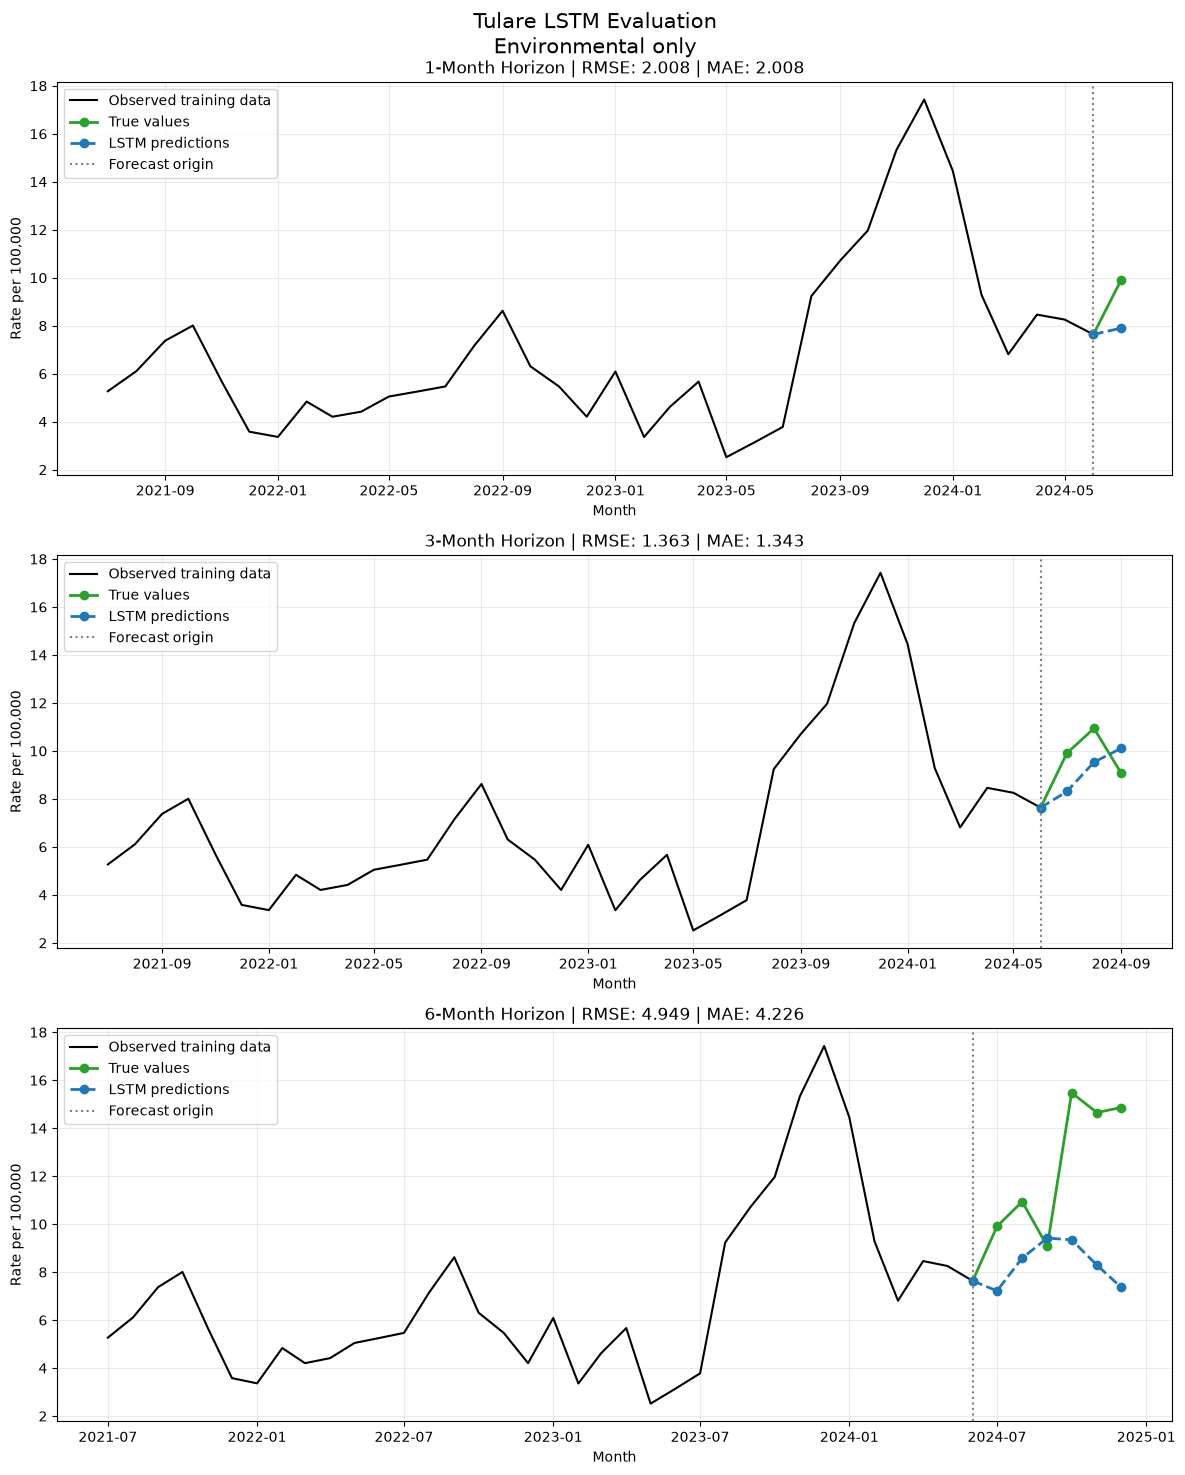


Running Ventura...
Ventura: training 1-month model...
Epoch 50/400 | Loss: 0.239154
Epoch 100/400 | Loss: 0.153210
Epoch 150/400 | Loss: 0.134035
Epoch 200/400 | Loss: 0.105889
Epoch 250/400 | Loss: 0.104416
Epoch 300/400 | Loss: 0.097986
Epoch 350/400 | Loss: 0.098913
Epoch 400/400 | Loss: 0.119694
Ventura: training 3-month model...
Epoch 50/400 | Loss: 0.274354
Epoch 100/400 | Loss: 0.183608
Epoch 150/400 | Loss: 0.176034
Epoch 200/400 | Loss: 0.159573
Epoch 250/400 | Loss: 0.177479
Epoch 300/400 | Loss: 0.150840
Epoch 350/400 | Loss: 0.144024
Epoch 400/400 | Loss: 0.154059
Ventura: training 6-month model...
Epoch 50/400 | Loss: 0.366428
Epoch 100/400 | Loss: 0.238256
Epoch 150/400 | Loss: 0.204786
Epoch 200/400 | Loss: 0.190037
Epoch 250/400 | Loss: 0.175032
Epoch 300/400 | Loss: 0.192106
Epoch 350/400 | Loss: 0.171895
Epoch 400/400 | Loss: 0.188947


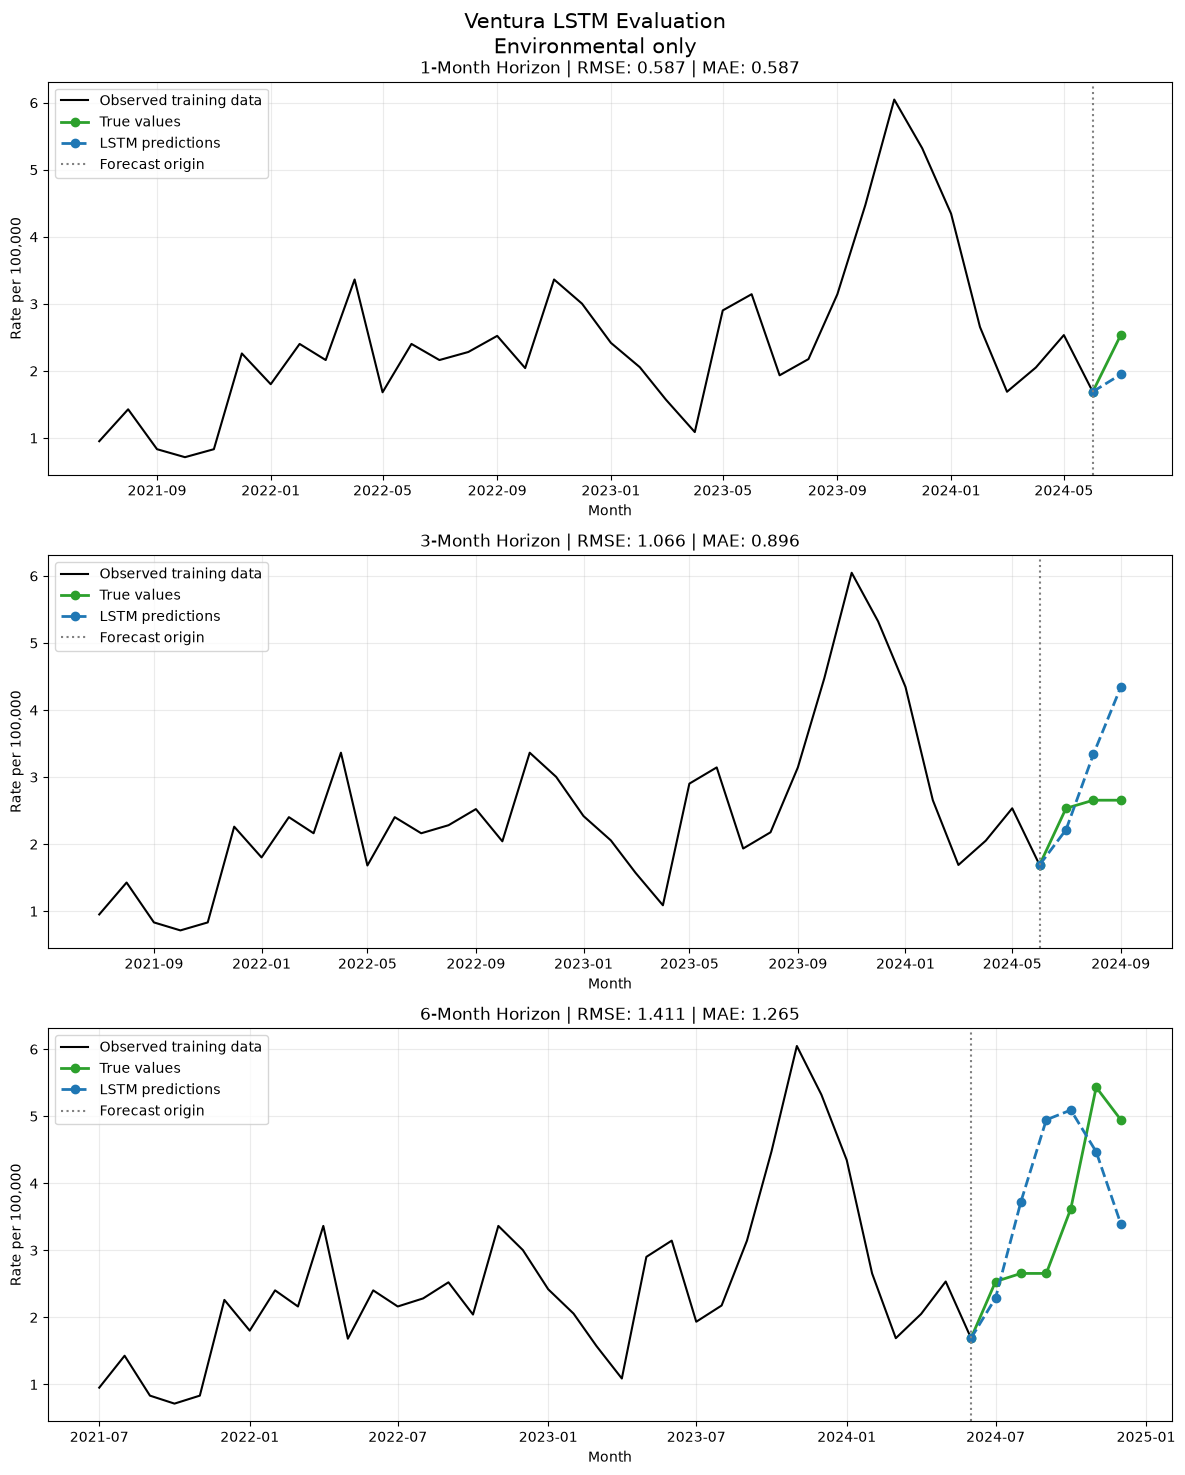

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Sequences,Lookback,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Hidden_Size,Number_Layers,Dropout,Epochs,Learning_Rate,Weight_Decay,Batch_Size,Final_Training_Loss
0,Fresno,Environmental only,2024-06-01,1,1,203,12,13,1.627880,1.627880,False,False,16,1,0.4,400,0.001,0.00001,32,0.113768
1,Fresno,Environmental only,2024-06-01,3,3,201,12,13,2.714997,2.657605,False,False,16,1,0.4,400,0.001,0.00001,32,0.152458
2,Fresno,Environmental only,2024-06-01,6,6,198,12,13,3.101723,2.853029,False,False,16,1,0.4,400,0.001,0.00001,32,0.191748
3,Kern,Environmental only,2024-06-01,1,1,203,12,13,3.352030,3.352030,False,False,16,1,0.4,400,0.001,0.00001,32,0.094015
4,Kern,Environmental only,2024-06-01,3,3,201,12,13,3.383128,3.378691,False,False,16,1,0.4,400,0.001,0.00001,32,0.153374
5,Kern,Environmental only,2024-06-01,6,6,198,12,13,5.583706,5.090228,False,False,16,1,0.4,400,0.001,0.00001,32,0.161332
6,Los Angeles,Environmental only,2024-06-01,1,1,203,12,13,0.188677,0.188677,False,False,16,1,0.4,400,0.001,0.00001,32,0.077336
7,Los Angeles,Environmental only,2024-06-01,3,3,201,12,13,0.202480,0.192320,False,False,16,1,0.4,400,0.001,0.00001,32,0.095491
8,Los Angeles,Environmental only,2024-06-01,6,6,198,12,13,0.202850,0.177193,False,False,16,1,0.4,400,0.001,0.00001,32,0.107649
9,Orange,Environmental only,2024-06-01,1,1,203,12,13,0.075470,0.075470,False,False,16,1,0.4,400,0.001,0.00001,32,0.136371


RMSE                           MAE                    
Forecast_Horizon         1         3         6         1         3         6
County                                                                      
Fresno            1.627880  2.714997  3.101723  1.627880  2.657605  2.853029
Kern              3.352030  3.383128  5.583706  3.352030  3.378691  5.090228
Los Angeles       0.188677  0.202480  0.202850  0.188677  0.192320  0.177193
Orange            0.075470  0.073114  0.215953  0.075470  0.065523  0.182442
San Diego         0.020337  0.570019  0.652356  0.020337  0.542937  0.618188
San Luis Obispo   2.186503  5.928445  7.925728  2.186503  5.631087  7.767841
Tulare            2.007673  1.363470  4.949023  2.007673  1.342913  4.226285
Ventura           0.587315  1.065982  1.411029  0.587315  0.896282  1.264784

In [30]:
all_lstm_environment_only = run_lstm_all_counties(
    counties=counties,
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config= {
        "lookback": 12,
        "use_rate_features": False,
        "use_log_target": False,
        "include_calendar_features": True,
    },
    lstm_parameters=lstm_parameters,
    output_dir=output_dir,
    show_plots=True,
)

display(all_lstm_environment_only["metrics"])
display(all_lstm_environment_only["metric_summary"])


Running Fresno...
Fresno: training 1-month model...
Epoch 50/400 | Loss: 0.283712
Epoch 100/400 | Loss: 0.216734
Epoch 150/400 | Loss: 0.170881
Epoch 200/400 | Loss: 0.169027
Epoch 250/400 | Loss: 0.147192
Epoch 300/400 | Loss: 0.135396
Epoch 350/400 | Loss: 0.153518
Epoch 400/400 | Loss: 0.119749
Fresno: training 3-month model...
Epoch 50/400 | Loss: 0.296405
Epoch 100/400 | Loss: 0.190643
Epoch 150/400 | Loss: 0.185802
Epoch 200/400 | Loss: 0.165626
Epoch 250/400 | Loss: 0.160331
Epoch 300/400 | Loss: 0.151595
Epoch 350/400 | Loss: 0.148778
Epoch 400/400 | Loss: 0.166528
Fresno: training 6-month model...
Epoch 50/400 | Loss: 0.314247
Epoch 100/400 | Loss: 0.227661
Epoch 150/400 | Loss: 0.224383
Epoch 200/400 | Loss: 0.211029
Epoch 250/400 | Loss: 0.191340
Epoch 300/400 | Loss: 0.188451
Epoch 350/400 | Loss: 0.189550
Epoch 400/400 | Loss: 0.192823


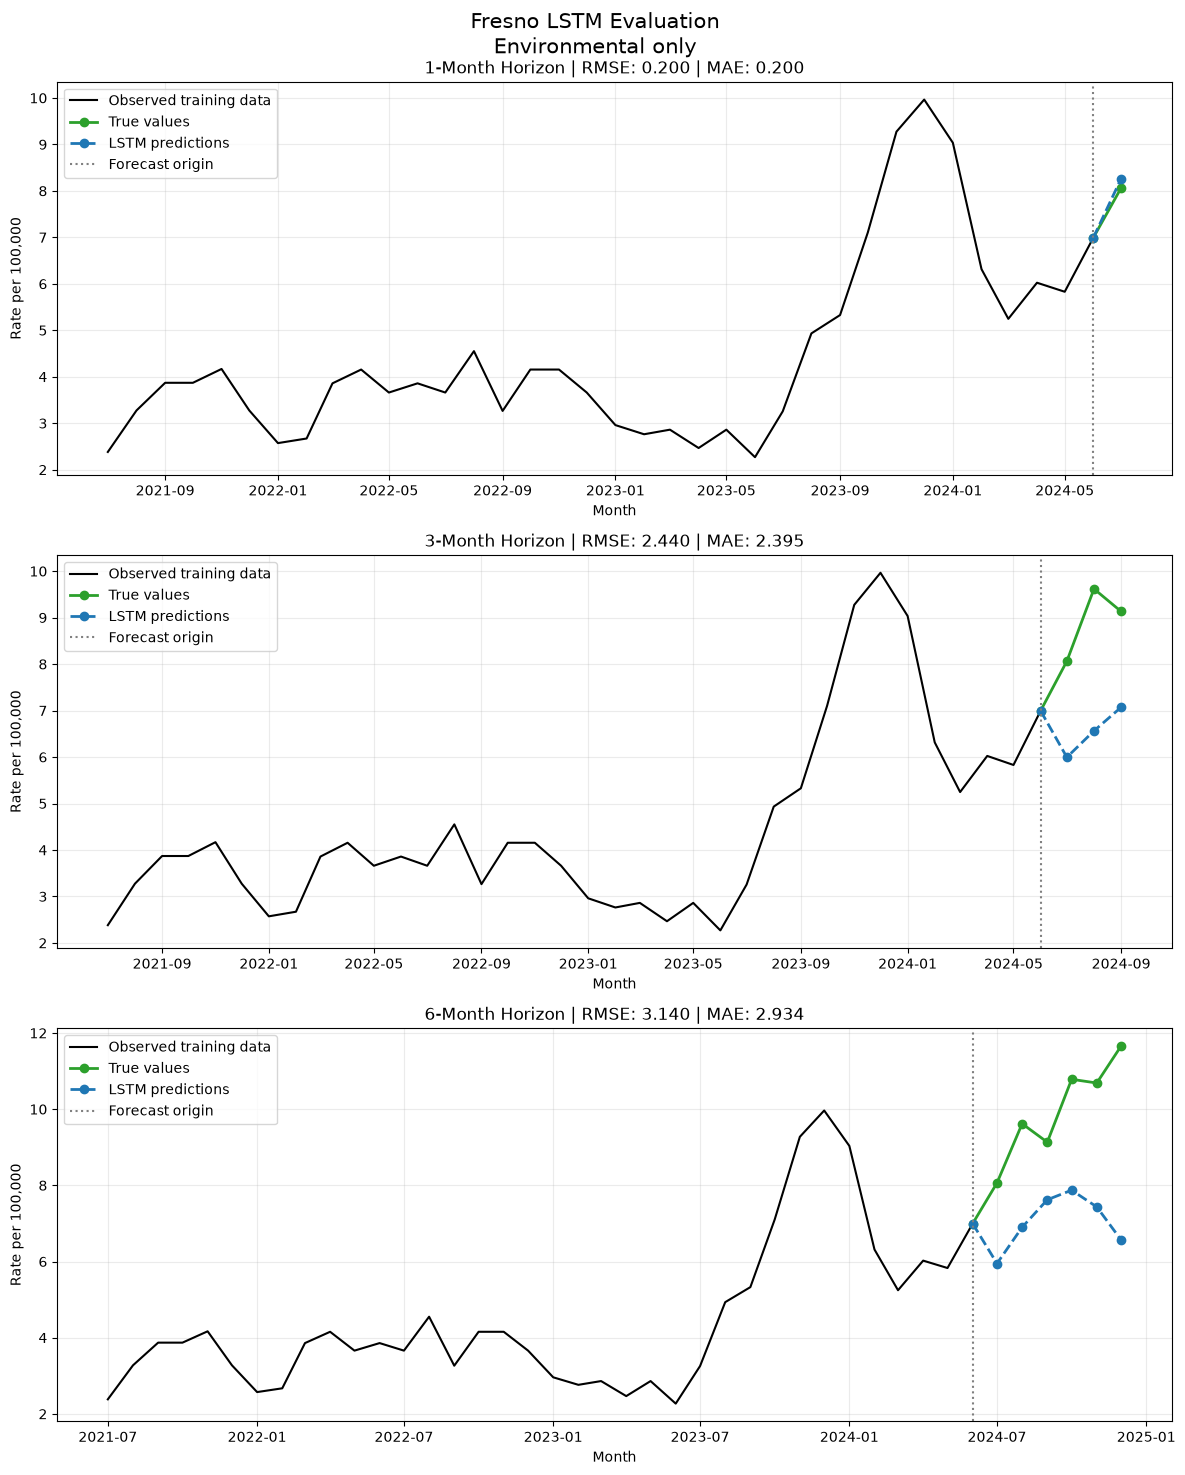


Running Kern...
Kern: training 1-month model...
Epoch 50/400 | Loss: 0.172768
Epoch 100/400 | Loss: 0.146963
Epoch 150/400 | Loss: 0.159983
Epoch 200/400 | Loss: 0.114090
Epoch 250/400 | Loss: 0.126215
Epoch 300/400 | Loss: 0.115723
Epoch 350/400 | Loss: 0.090836
Epoch 400/400 | Loss: 0.091806
Kern: training 3-month model...
Epoch 50/400 | Loss: 0.221155
Epoch 100/400 | Loss: 0.166337
Epoch 150/400 | Loss: 0.157731
Epoch 200/400 | Loss: 0.161946
Epoch 250/400 | Loss: 0.133069
Epoch 300/400 | Loss: 0.129032
Epoch 350/400 | Loss: 0.127445
Epoch 400/400 | Loss: 0.126719
Kern: training 6-month model...
Epoch 50/400 | Loss: 0.244102
Epoch 100/400 | Loss: 0.227270
Epoch 150/400 | Loss: 0.191791
Epoch 200/400 | Loss: 0.190831
Epoch 250/400 | Loss: 0.175972
Epoch 300/400 | Loss: 0.168410
Epoch 350/400 | Loss: 0.155912
Epoch 400/400 | Loss: 0.163476


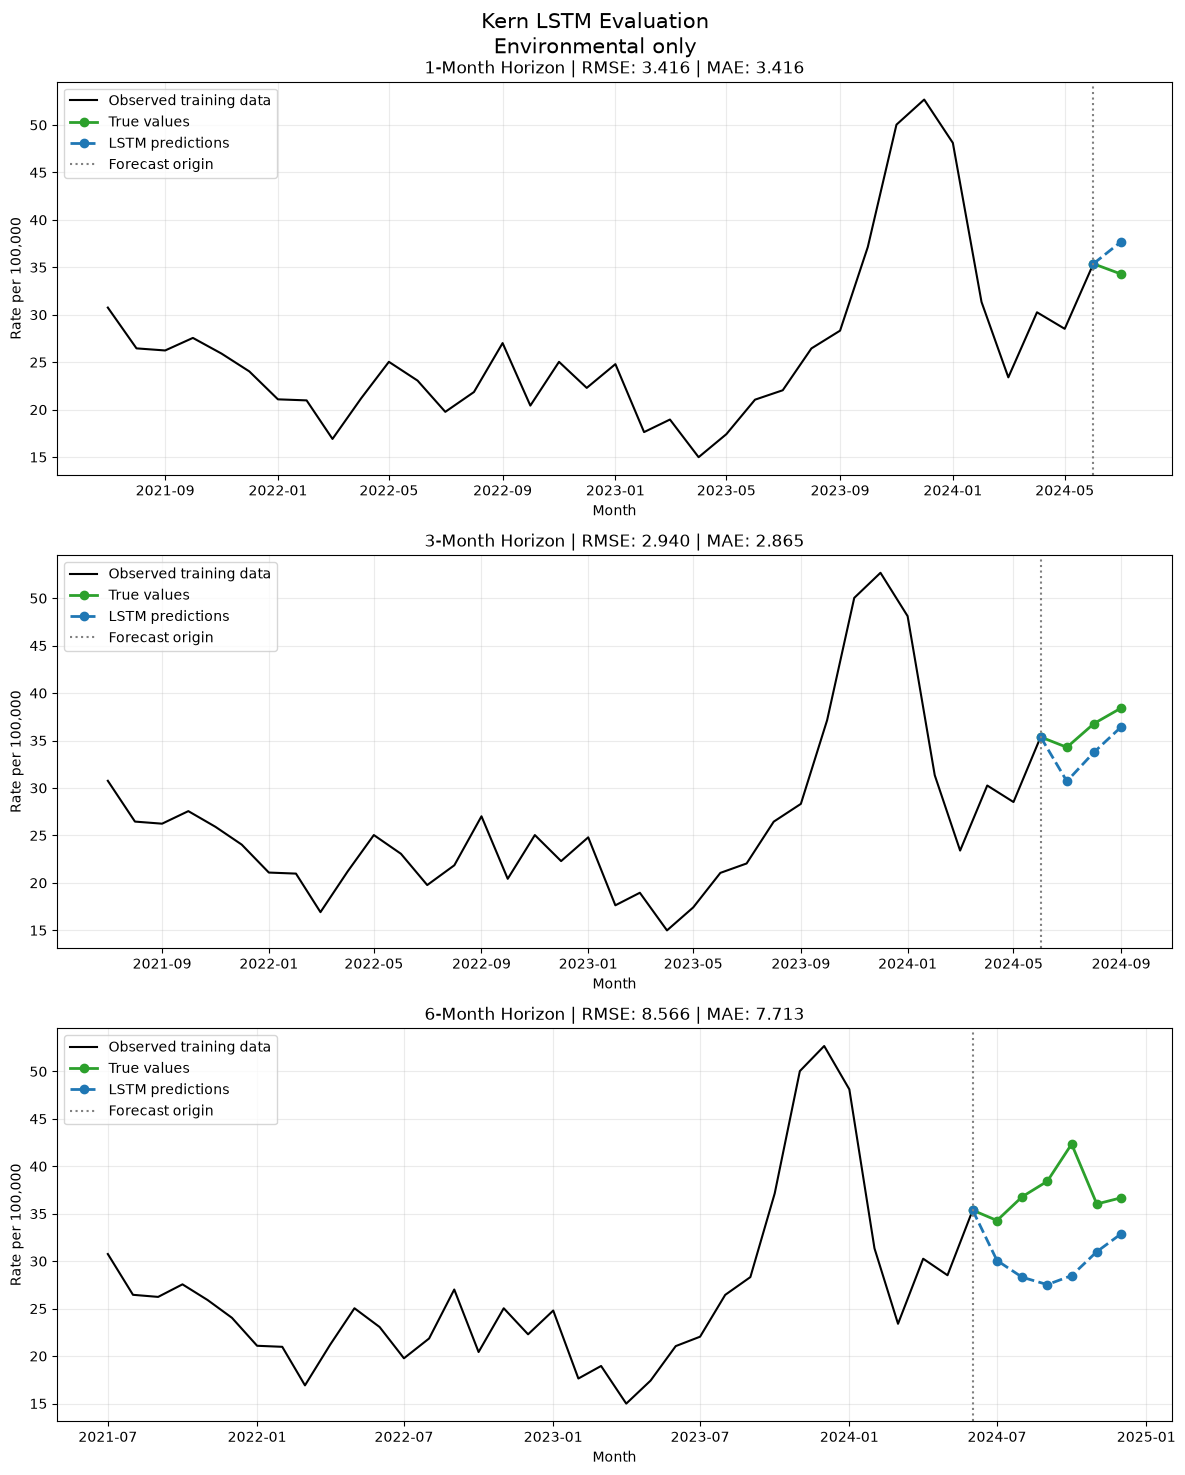


Running Los Angeles...
Los Angeles: training 1-month model...
Epoch 50/400 | Loss: 0.131298
Epoch 100/400 | Loss: 0.094073
Epoch 150/400 | Loss: 0.110381
Epoch 200/400 | Loss: 0.086521
Epoch 250/400 | Loss: 0.073653
Epoch 300/400 | Loss: 0.091606
Epoch 350/400 | Loss: 0.082260
Epoch 400/400 | Loss: 0.087124
Los Angeles: training 3-month model...
Epoch 50/400 | Loss: 0.148720
Epoch 100/400 | Loss: 0.096651
Epoch 150/400 | Loss: 0.109824
Epoch 200/400 | Loss: 0.104674
Epoch 250/400 | Loss: 0.107787
Epoch 300/400 | Loss: 0.109598
Epoch 350/400 | Loss: 0.083695
Epoch 400/400 | Loss: 0.101086
Los Angeles: training 6-month model...
Epoch 50/400 | Loss: 0.143303
Epoch 100/400 | Loss: 0.137700
Epoch 150/400 | Loss: 0.132018
Epoch 200/400 | Loss: 0.120706
Epoch 250/400 | Loss: 0.115617
Epoch 300/400 | Loss: 0.111488
Epoch 350/400 | Loss: 0.112501
Epoch 400/400 | Loss: 0.113274


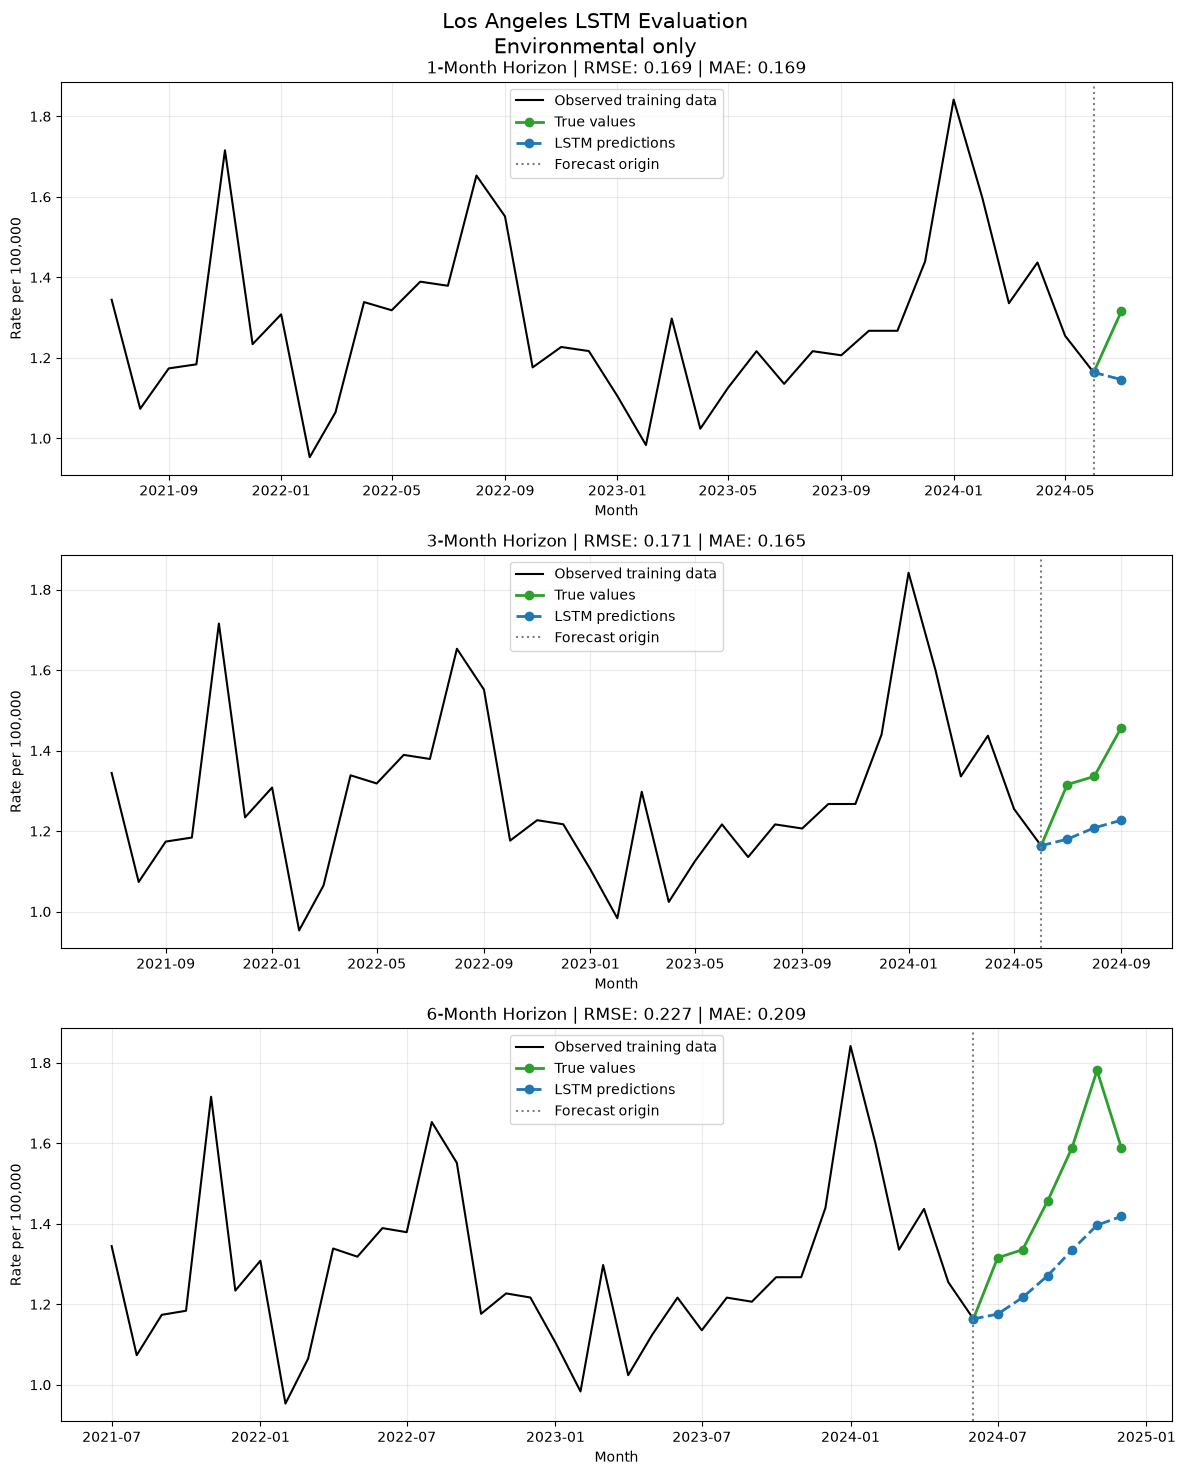


Running Orange...
Orange: training 1-month model...
Epoch 50/400 | Loss: 0.242557
Epoch 100/400 | Loss: 0.203317
Epoch 150/400 | Loss: 0.208760
Epoch 200/400 | Loss: 0.151258
Epoch 250/400 | Loss: 0.126768
Epoch 300/400 | Loss: 0.135175
Epoch 350/400 | Loss: 0.145678
Epoch 400/400 | Loss: 0.126189
Orange: training 3-month model...
Epoch 50/400 | Loss: 0.273425
Epoch 100/400 | Loss: 0.236889
Epoch 150/400 | Loss: 0.213513
Epoch 200/400 | Loss: 0.191249
Epoch 250/400 | Loss: 0.191791
Epoch 300/400 | Loss: 0.176543
Epoch 350/400 | Loss: 0.175493
Epoch 400/400 | Loss: 0.173972
Orange: training 6-month model...
Epoch 50/400 | Loss: 0.288569
Epoch 100/400 | Loss: 0.250183
Epoch 150/400 | Loss: 0.214282
Epoch 200/400 | Loss: 0.212686
Epoch 250/400 | Loss: 0.202754
Epoch 300/400 | Loss: 0.202548
Epoch 350/400 | Loss: 0.188863
Epoch 400/400 | Loss: 0.185164


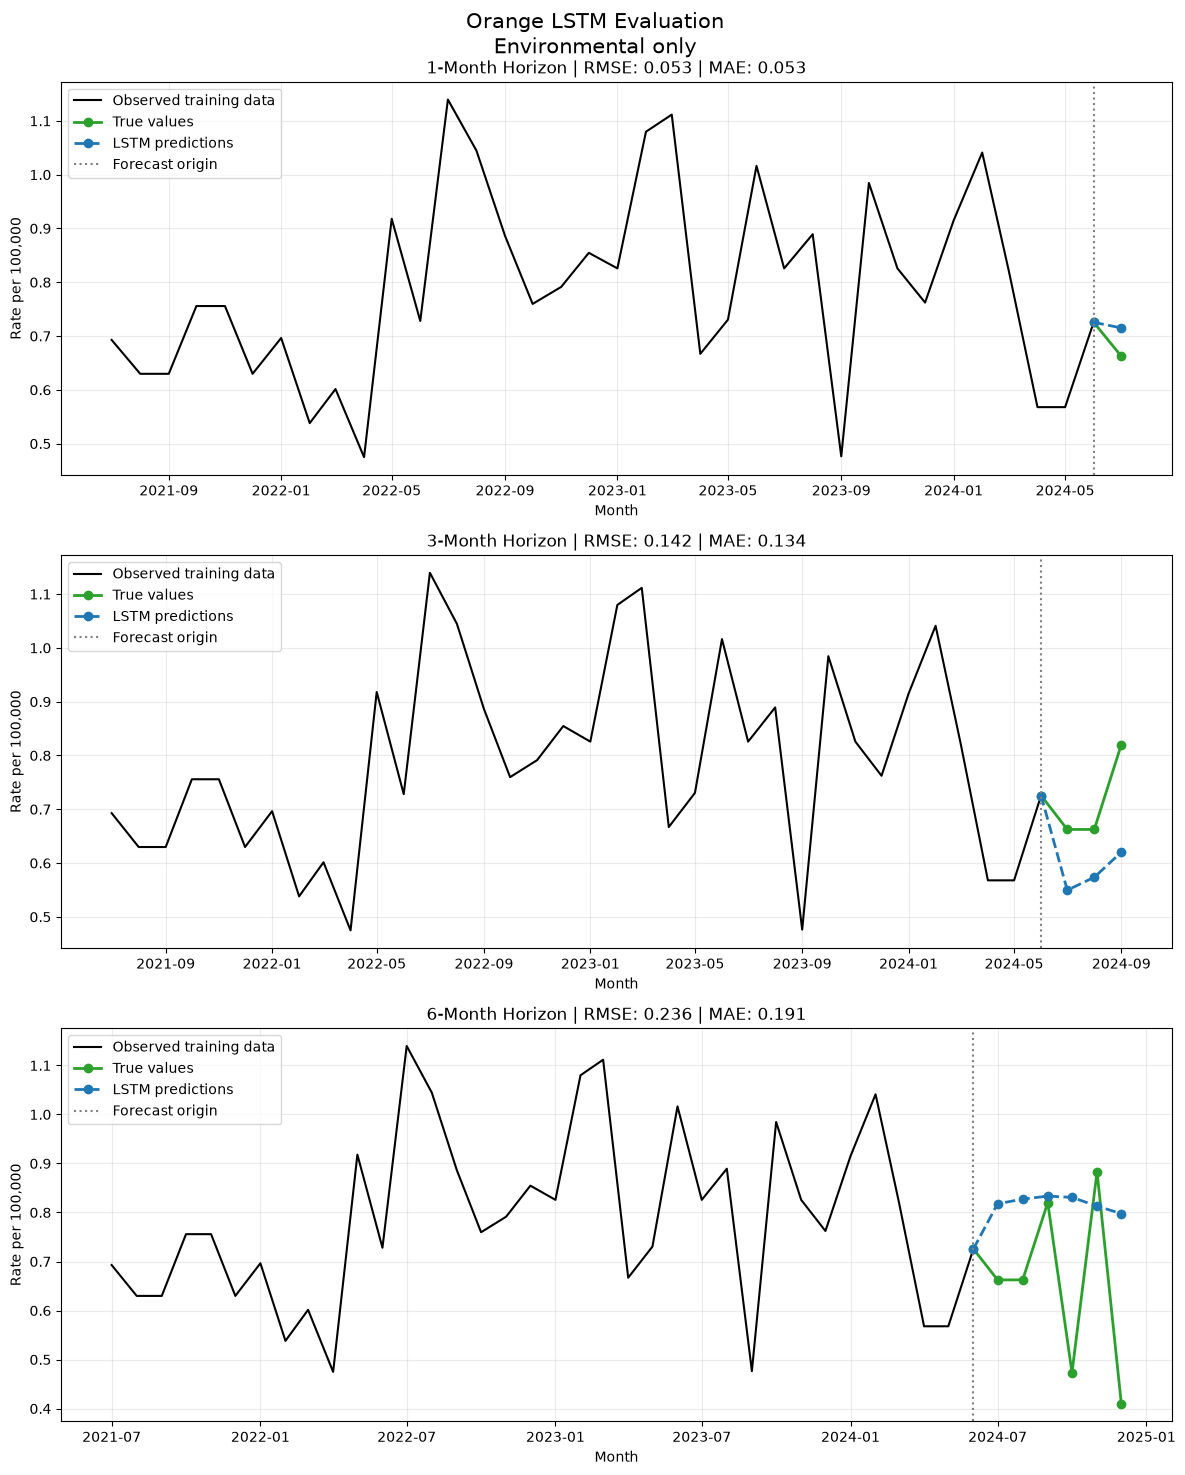


Running San Diego...
San Diego: training 1-month model...
Epoch 50/400 | Loss: 0.179104
Epoch 100/400 | Loss: 0.142325
Epoch 150/400 | Loss: 0.166649
Epoch 200/400 | Loss: 0.130330
Epoch 250/400 | Loss: 0.122165
Epoch 300/400 | Loss: 0.133524
Epoch 350/400 | Loss: 0.130938
Epoch 400/400 | Loss: 0.114241
San Diego: training 3-month model...
Epoch 50/400 | Loss: 0.208569
Epoch 100/400 | Loss: 0.175007
Epoch 150/400 | Loss: 0.198986
Epoch 200/400 | Loss: 0.169731
Epoch 250/400 | Loss: 0.175731
Epoch 300/400 | Loss: 0.156471
Epoch 350/400 | Loss: 0.162595
Epoch 400/400 | Loss: 0.165143
San Diego: training 6-month model...
Epoch 50/400 | Loss: 0.222766
Epoch 100/400 | Loss: 0.196682
Epoch 150/400 | Loss: 0.207816
Epoch 200/400 | Loss: 0.197879
Epoch 250/400 | Loss: 0.197504
Epoch 300/400 | Loss: 0.170249
Epoch 350/400 | Loss: 0.172190
Epoch 400/400 | Loss: 0.167792


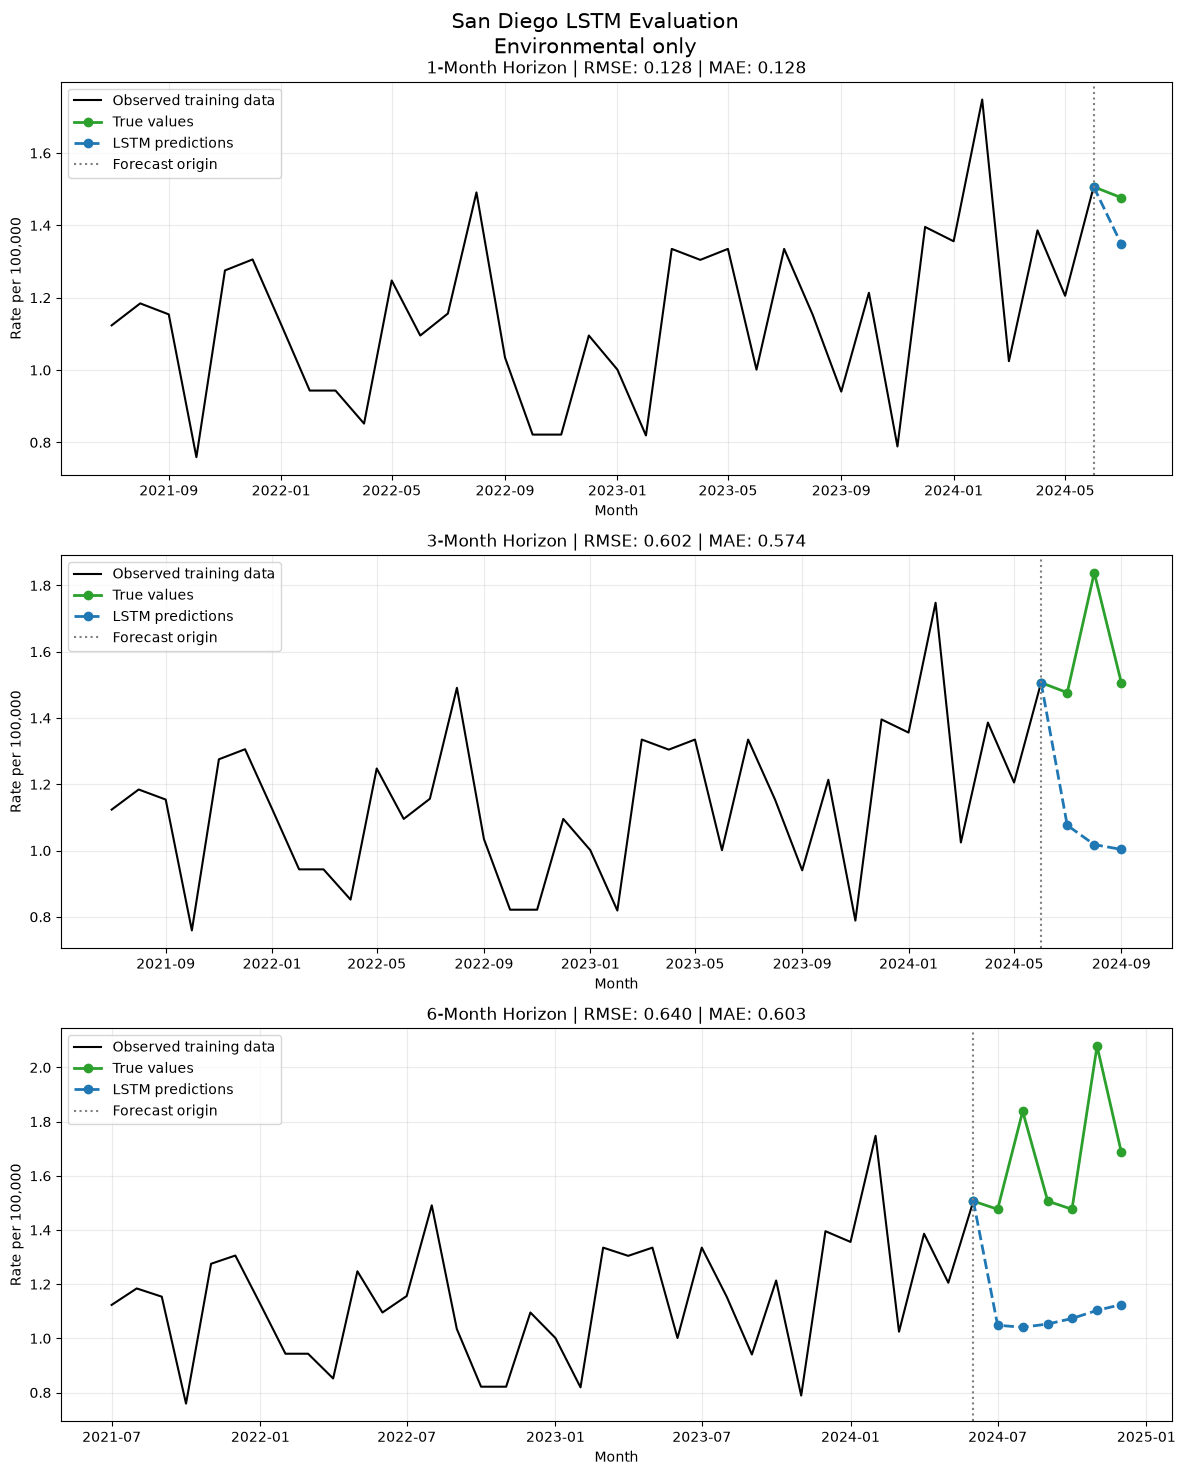


Running San Luis Obispo...
San Luis Obispo: training 1-month model...
Epoch 50/400 | Loss: 0.169208
Epoch 100/400 | Loss: 0.183362
Epoch 150/400 | Loss: 0.182542
Epoch 200/400 | Loss: 0.100311
Epoch 250/400 | Loss: 0.125690
Epoch 300/400 | Loss: 0.147480
Epoch 350/400 | Loss: 0.081186
Epoch 400/400 | Loss: 0.109687
San Luis Obispo: training 3-month model...
Epoch 50/400 | Loss: 0.288544
Epoch 100/400 | Loss: 0.193891
Epoch 150/400 | Loss: 0.172506
Epoch 200/400 | Loss: 0.175935
Epoch 250/400 | Loss: 0.145059
Epoch 300/400 | Loss: 0.185313
Epoch 350/400 | Loss: 0.185765
Epoch 400/400 | Loss: 0.192105
San Luis Obispo: training 6-month model...
Epoch 50/400 | Loss: 0.300644
Epoch 100/400 | Loss: 0.264342
Epoch 150/400 | Loss: 0.215138
Epoch 200/400 | Loss: 0.195309
Epoch 250/400 | Loss: 0.191883
Epoch 300/400 | Loss: 0.193215
Epoch 350/400 | Loss: 0.192833
Epoch 400/400 | Loss: 0.182793


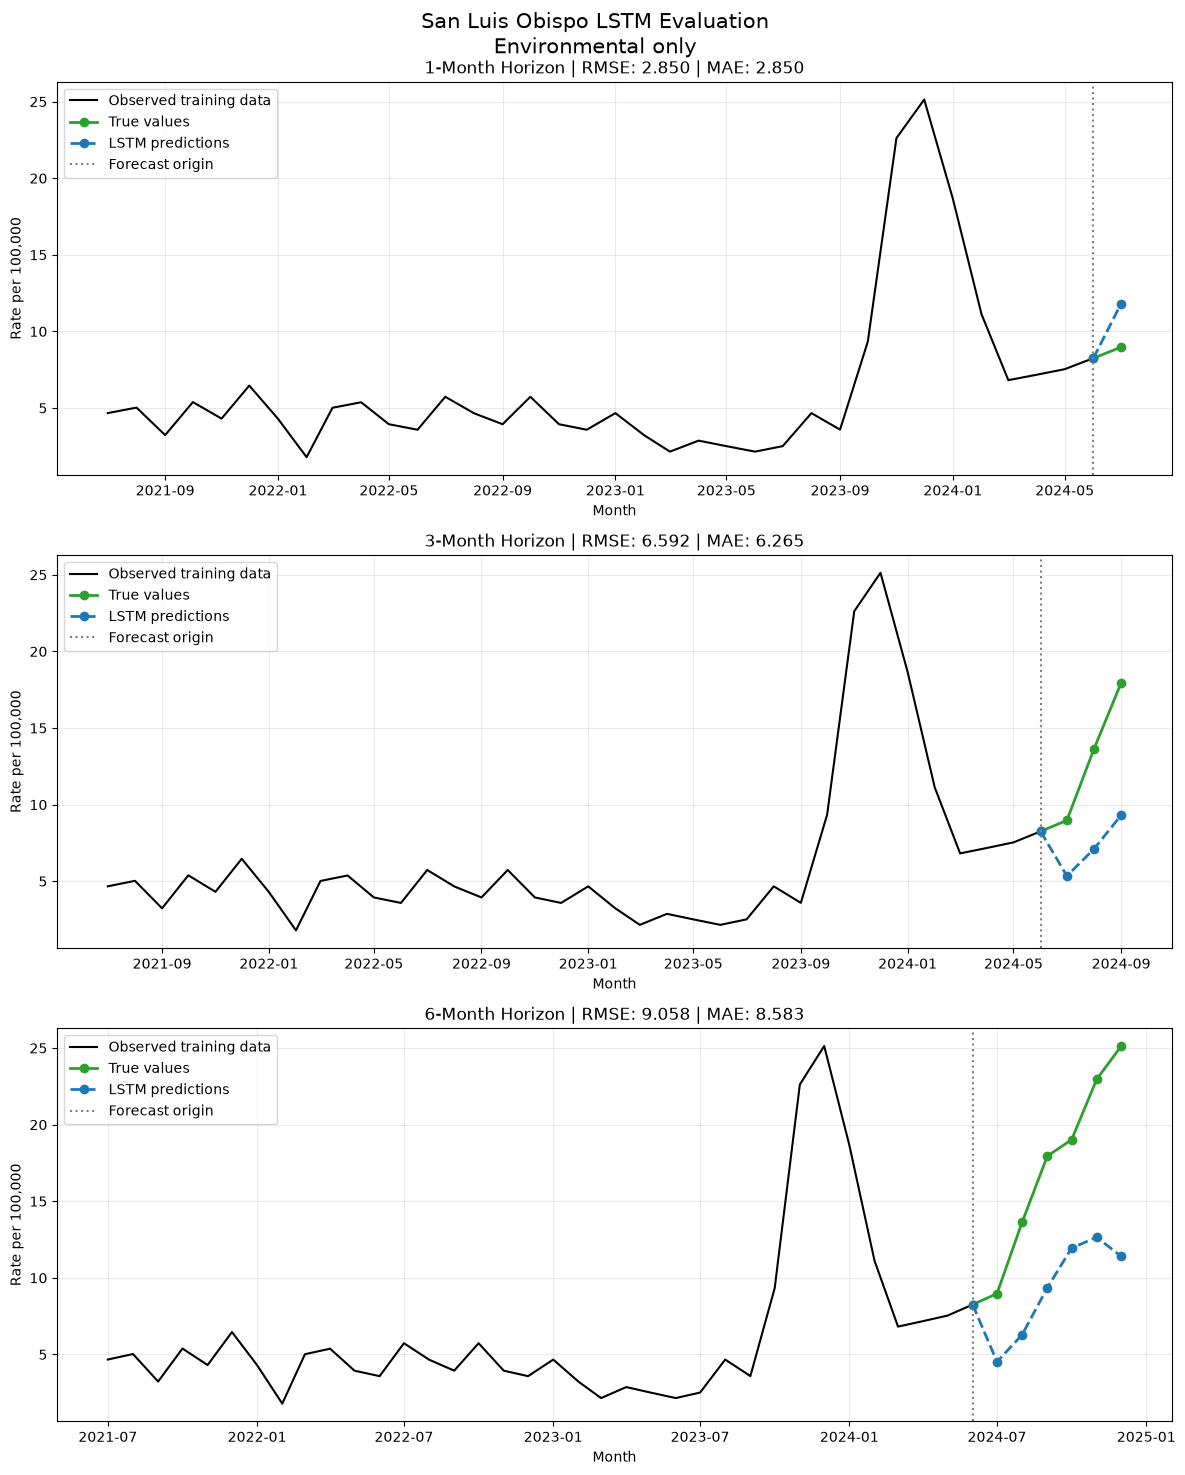


Running Tulare...
Tulare: training 1-month model...
Epoch 50/400 | Loss: 0.338644
Epoch 100/400 | Loss: 0.215916
Epoch 150/400 | Loss: 0.218681
Epoch 200/400 | Loss: 0.160808
Epoch 250/400 | Loss: 0.174112
Epoch 300/400 | Loss: 0.146881
Epoch 350/400 | Loss: 0.128287
Epoch 400/400 | Loss: 0.125396
Tulare: training 3-month model...
Epoch 50/400 | Loss: 0.332209
Epoch 100/400 | Loss: 0.214227
Epoch 150/400 | Loss: 0.192231
Epoch 200/400 | Loss: 0.207457
Epoch 250/400 | Loss: 0.188385
Epoch 300/400 | Loss: 0.183677
Epoch 350/400 | Loss: 0.181356
Epoch 400/400 | Loss: 0.185190
Tulare: training 6-month model...
Epoch 50/400 | Loss: 0.341468
Epoch 100/400 | Loss: 0.292918
Epoch 150/400 | Loss: 0.220805
Epoch 200/400 | Loss: 0.230617
Epoch 250/400 | Loss: 0.233194
Epoch 300/400 | Loss: 0.210111
Epoch 350/400 | Loss: 0.211050
Epoch 400/400 | Loss: 0.215866


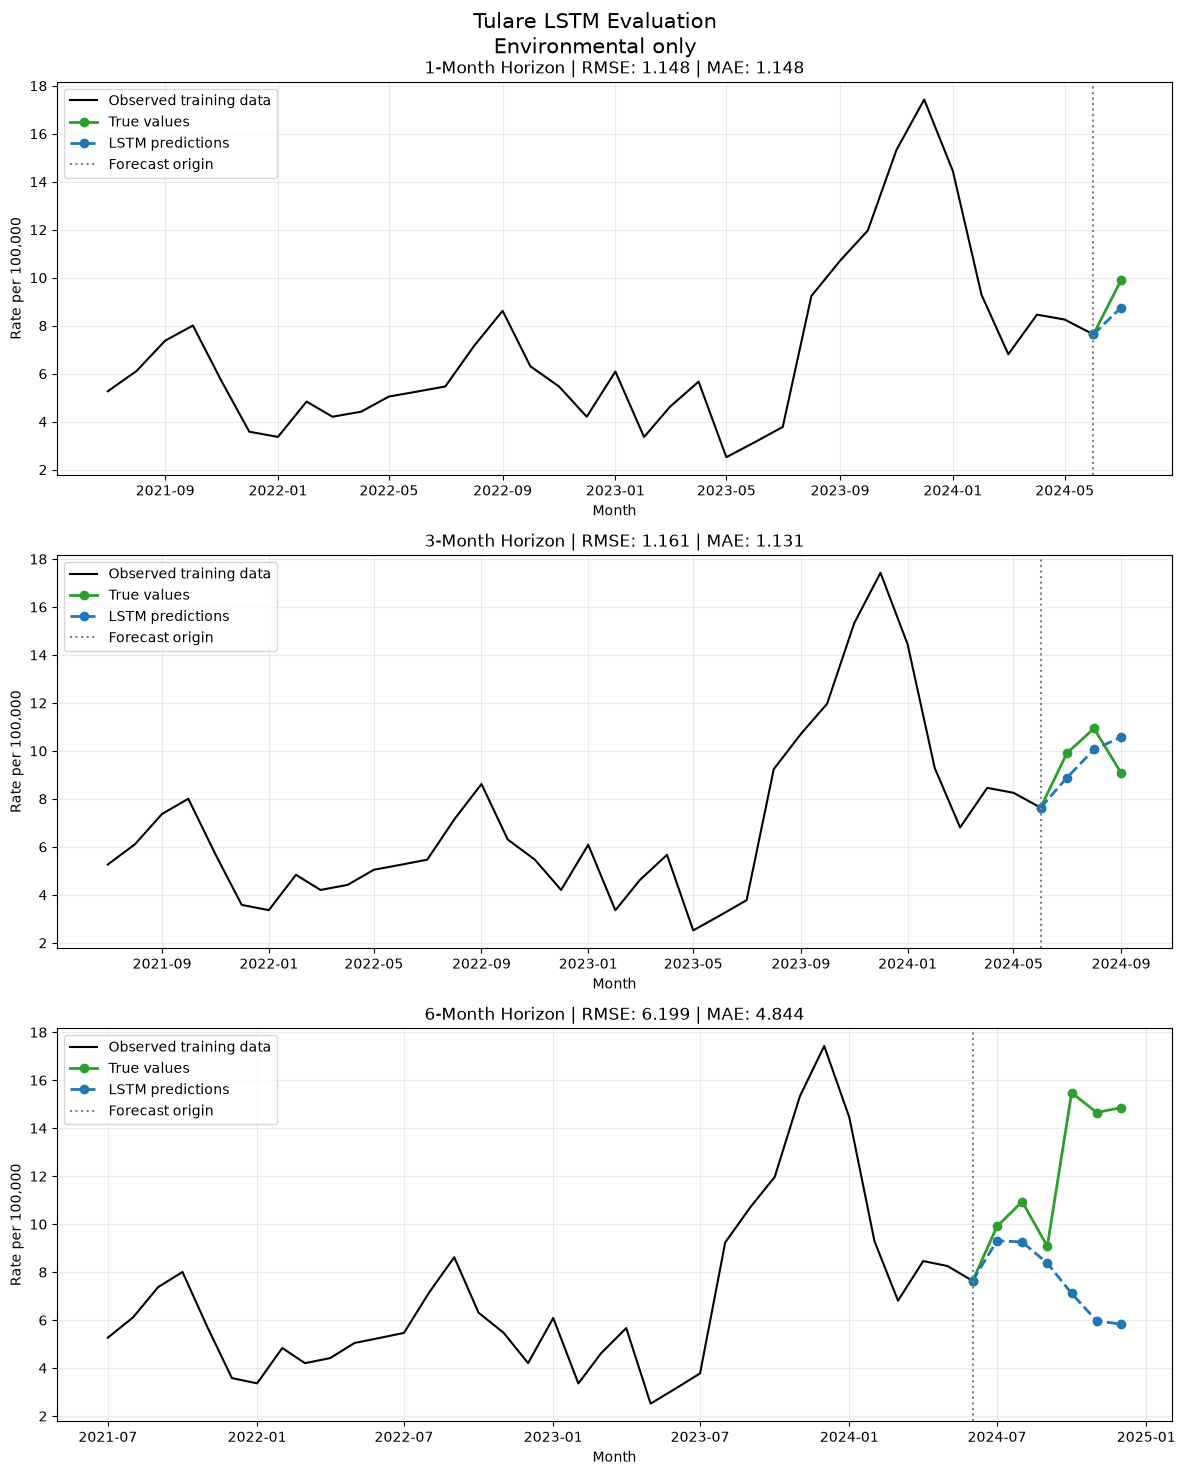


Running Ventura...
Ventura: training 1-month model...
Epoch 50/400 | Loss: 0.172755
Epoch 100/400 | Loss: 0.147439
Epoch 150/400 | Loss: 0.173709
Epoch 200/400 | Loss: 0.094403
Epoch 250/400 | Loss: 0.115612
Epoch 300/400 | Loss: 0.115565
Epoch 350/400 | Loss: 0.092070
Epoch 400/400 | Loss: 0.099789
Ventura: training 3-month model...
Epoch 50/400 | Loss: 0.214984
Epoch 100/400 | Loss: 0.166920
Epoch 150/400 | Loss: 0.159450
Epoch 200/400 | Loss: 0.154509
Epoch 250/400 | Loss: 0.135335
Epoch 300/400 | Loss: 0.164242
Epoch 350/400 | Loss: 0.150733
Epoch 400/400 | Loss: 0.164563
Ventura: training 6-month model...
Epoch 50/400 | Loss: 0.255119
Epoch 100/400 | Loss: 0.228117
Epoch 150/400 | Loss: 0.195580
Epoch 200/400 | Loss: 0.193938
Epoch 250/400 | Loss: 0.191058
Epoch 300/400 | Loss: 0.177668
Epoch 350/400 | Loss: 0.177993
Epoch 400/400 | Loss: 0.165771


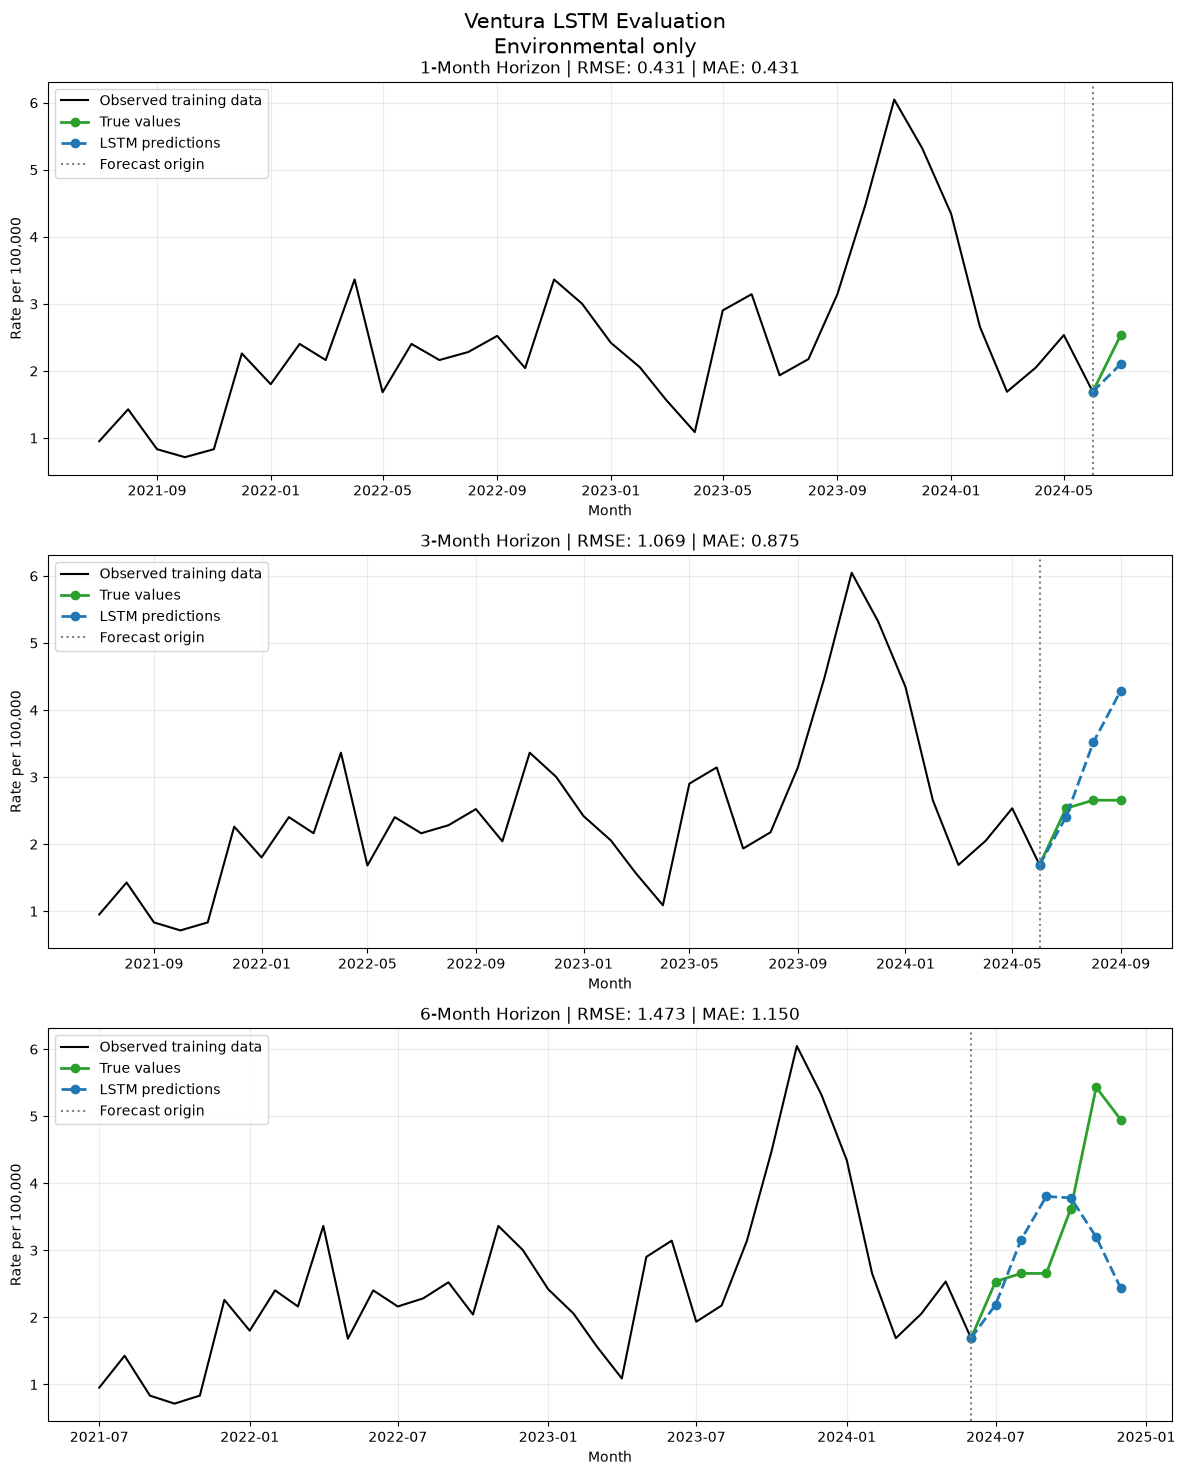

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Sequences,Lookback,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Hidden_Size,Number_Layers,Dropout,Epochs,Learning_Rate,Weight_Decay,Batch_Size,Final_Training_Loss
0,Fresno,Environmental only,2024-06-01,1,1,191,24,13,0.200446,0.200446,False,False,16,1,0.4,400,0.001,0.00001,32,0.119749
1,Fresno,Environmental only,2024-06-01,3,3,189,24,13,2.440043,2.395061,False,False,16,1,0.4,400,0.001,0.00001,32,0.166528
2,Fresno,Environmental only,2024-06-01,6,6,186,24,13,3.139791,2.933814,False,False,16,1,0.4,400,0.001,0.00001,32,0.192823
3,Kern,Environmental only,2024-06-01,1,1,191,24,13,3.416456,3.416456,False,False,16,1,0.4,400,0.001,0.00001,32,0.091806
4,Kern,Environmental only,2024-06-01,3,3,189,24,13,2.939637,2.865250,False,False,16,1,0.4,400,0.001,0.00001,32,0.126719
5,Kern,Environmental only,2024-06-01,6,6,186,24,13,8.565916,7.713149,False,False,16,1,0.4,400,0.001,0.00001,32,0.163476
6,Los Angeles,Environmental only,2024-06-01,1,1,191,24,13,0.169381,0.169381,False,False,16,1,0.4,400,0.001,0.00001,32,0.087124
7,Los Angeles,Environmental only,2024-06-01,3,3,189,24,13,0.171031,0.164560,False,False,16,1,0.4,400,0.001,0.00001,32,0.101086
8,Los Angeles,Environmental only,2024-06-01,6,6,186,24,13,0.227135,0.208886,False,False,16,1,0.4,400,0.001,0.00001,32,0.113274
9,Orange,Environmental only,2024-06-01,1,1,191,24,13,0.052564,0.052564,False,False,16,1,0.4,400,0.001,0.00001,32,0.126189


RMSE                           MAE                    
Forecast_Horizon         1         3         6         1         3         6
County                                                                      
Fresno            0.200446  2.440043  3.139791  0.200446  2.395061  2.933814
Kern              3.416456  2.939637  8.565916  3.416456  2.865250  7.713149
Los Angeles       0.169381  0.171031  0.227135  0.169381  0.164560  0.208886
Orange            0.052564  0.142112  0.236058  0.052564  0.133879  0.191421
San Diego         0.128317  0.601632  0.639771  0.128317  0.574487  0.603408
San Luis Obispo   2.849709  6.592384  9.057983  2.849709  6.264716  8.583263
Tulare            1.147674  1.161380  6.199473  1.147674  1.131310  4.844048
Ventura           0.431272  1.069411  1.473119  0.431272  0.875166  1.150182

In [31]:
all_lstm_environment_only = run_lstm_all_counties(
    counties=counties,
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config= {
        "lookback": 24,
        "use_rate_features": False,
        "use_log_target": False,
        "include_calendar_features": True,
    },
    lstm_parameters=lstm_parameters,
    output_dir=output_dir,
    show_plots=True,
)

display(all_lstm_environment_only["metrics"])
display(all_lstm_environment_only["metric_summary"])


Running Fresno...
Fresno: training 1-month model...
Epoch 50/400 | Loss: 0.738176
Epoch 100/400 | Loss: 0.369435
Epoch 150/400 | Loss: 0.275015
Epoch 200/400 | Loss: 0.252662
Epoch 250/400 | Loss: 0.223596
Epoch 300/400 | Loss: 0.218391
Epoch 350/400 | Loss: 0.158884
Epoch 400/400 | Loss: 0.138974
Fresno: training 3-month model...
Epoch 50/400 | Loss: 0.501429
Epoch 100/400 | Loss: 0.302750
Epoch 150/400 | Loss: 0.262543
Epoch 200/400 | Loss: 0.259835
Epoch 250/400 | Loss: 0.223662
Epoch 300/400 | Loss: 0.231907
Epoch 350/400 | Loss: 0.229044
Epoch 400/400 | Loss: 0.248516
Fresno: training 6-month model...
Epoch 50/400 | Loss: 0.565627
Epoch 100/400 | Loss: 0.362304
Epoch 150/400 | Loss: 0.317699
Epoch 200/400 | Loss: 0.300287
Epoch 250/400 | Loss: 0.300453
Epoch 300/400 | Loss: 0.241895
Epoch 350/400 | Loss: 0.281812
Epoch 400/400 | Loss: 0.256704


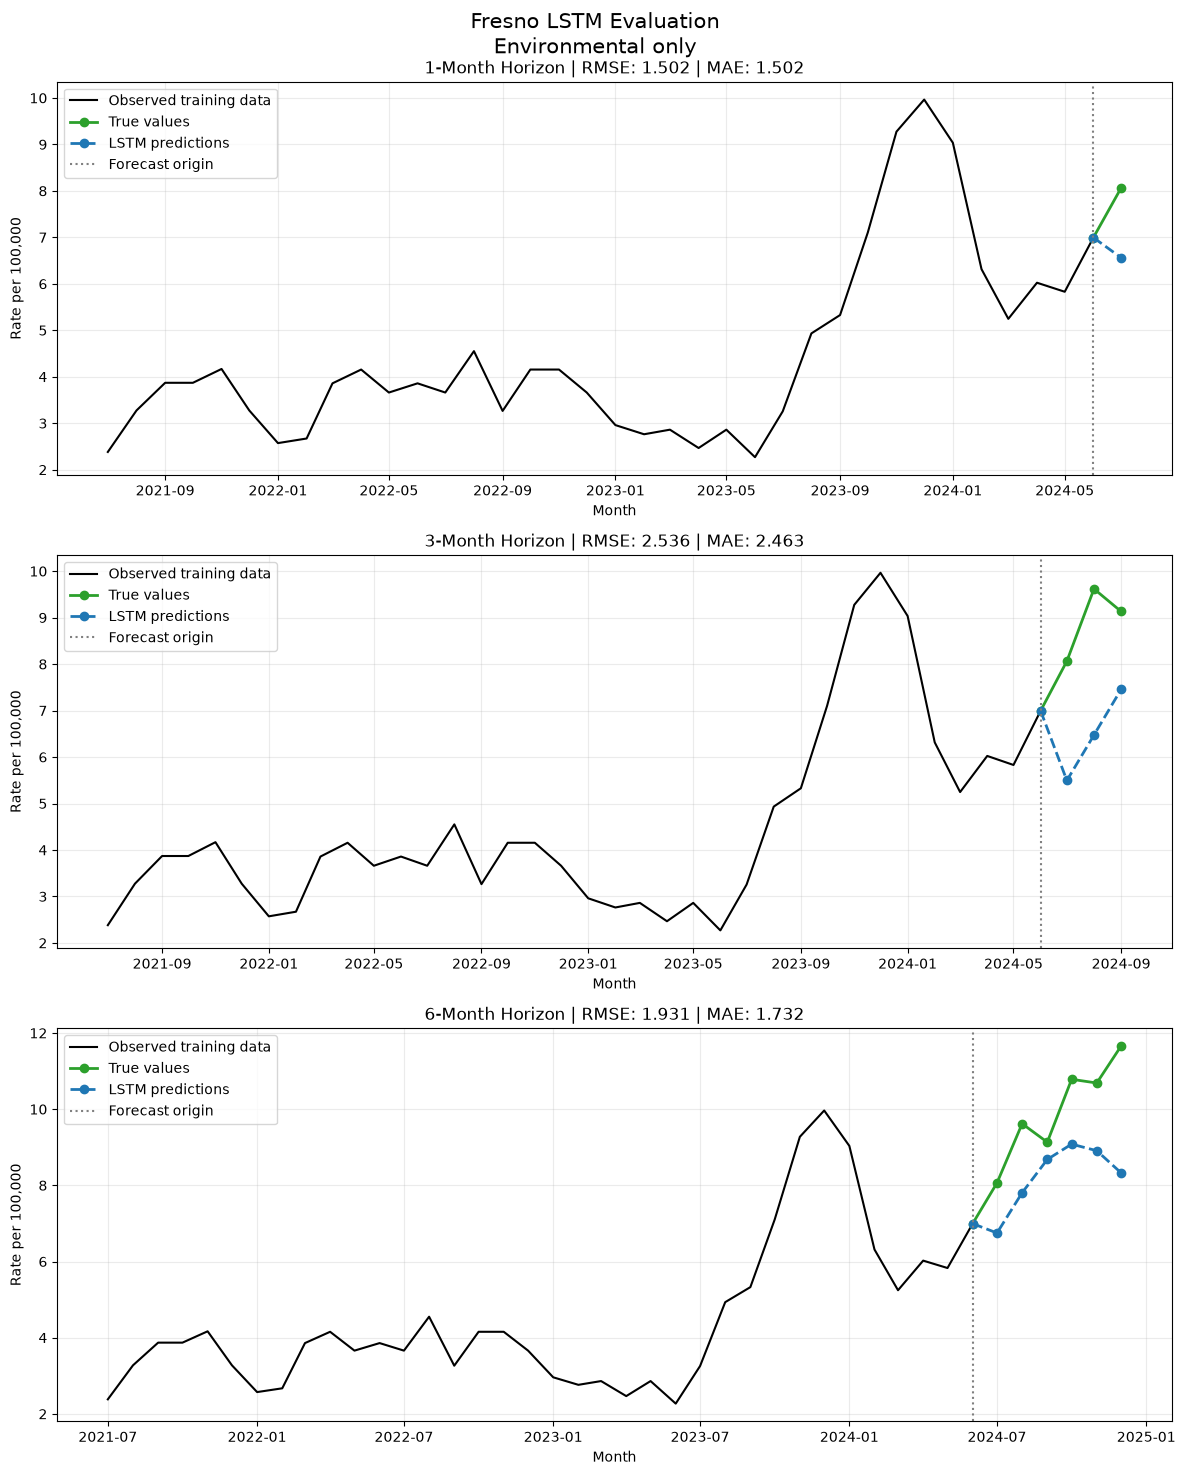


Running Kern...
Kern: training 1-month model...
Epoch 50/400 | Loss: 0.372902
Epoch 100/400 | Loss: 0.258428
Epoch 150/400 | Loss: 0.220826
Epoch 200/400 | Loss: 0.195993
Epoch 250/400 | Loss: 0.244996
Epoch 300/400 | Loss: 0.196547
Epoch 350/400 | Loss: 0.160584
Epoch 400/400 | Loss: 0.185738
Kern: training 3-month model...
Epoch 50/400 | Loss: 0.370725
Epoch 100/400 | Loss: 0.254659
Epoch 150/400 | Loss: 0.230133
Epoch 200/400 | Loss: 0.236705
Epoch 250/400 | Loss: 0.227531
Epoch 300/400 | Loss: 0.194955
Epoch 350/400 | Loss: 0.199546
Epoch 400/400 | Loss: 0.215187
Kern: training 6-month model...
Epoch 50/400 | Loss: 0.447049
Epoch 100/400 | Loss: 0.342558
Epoch 150/400 | Loss: 0.297457
Epoch 200/400 | Loss: 0.295742
Epoch 250/400 | Loss: 0.274058
Epoch 300/400 | Loss: 0.261418
Epoch 350/400 | Loss: 0.261958
Epoch 400/400 | Loss: 0.251880


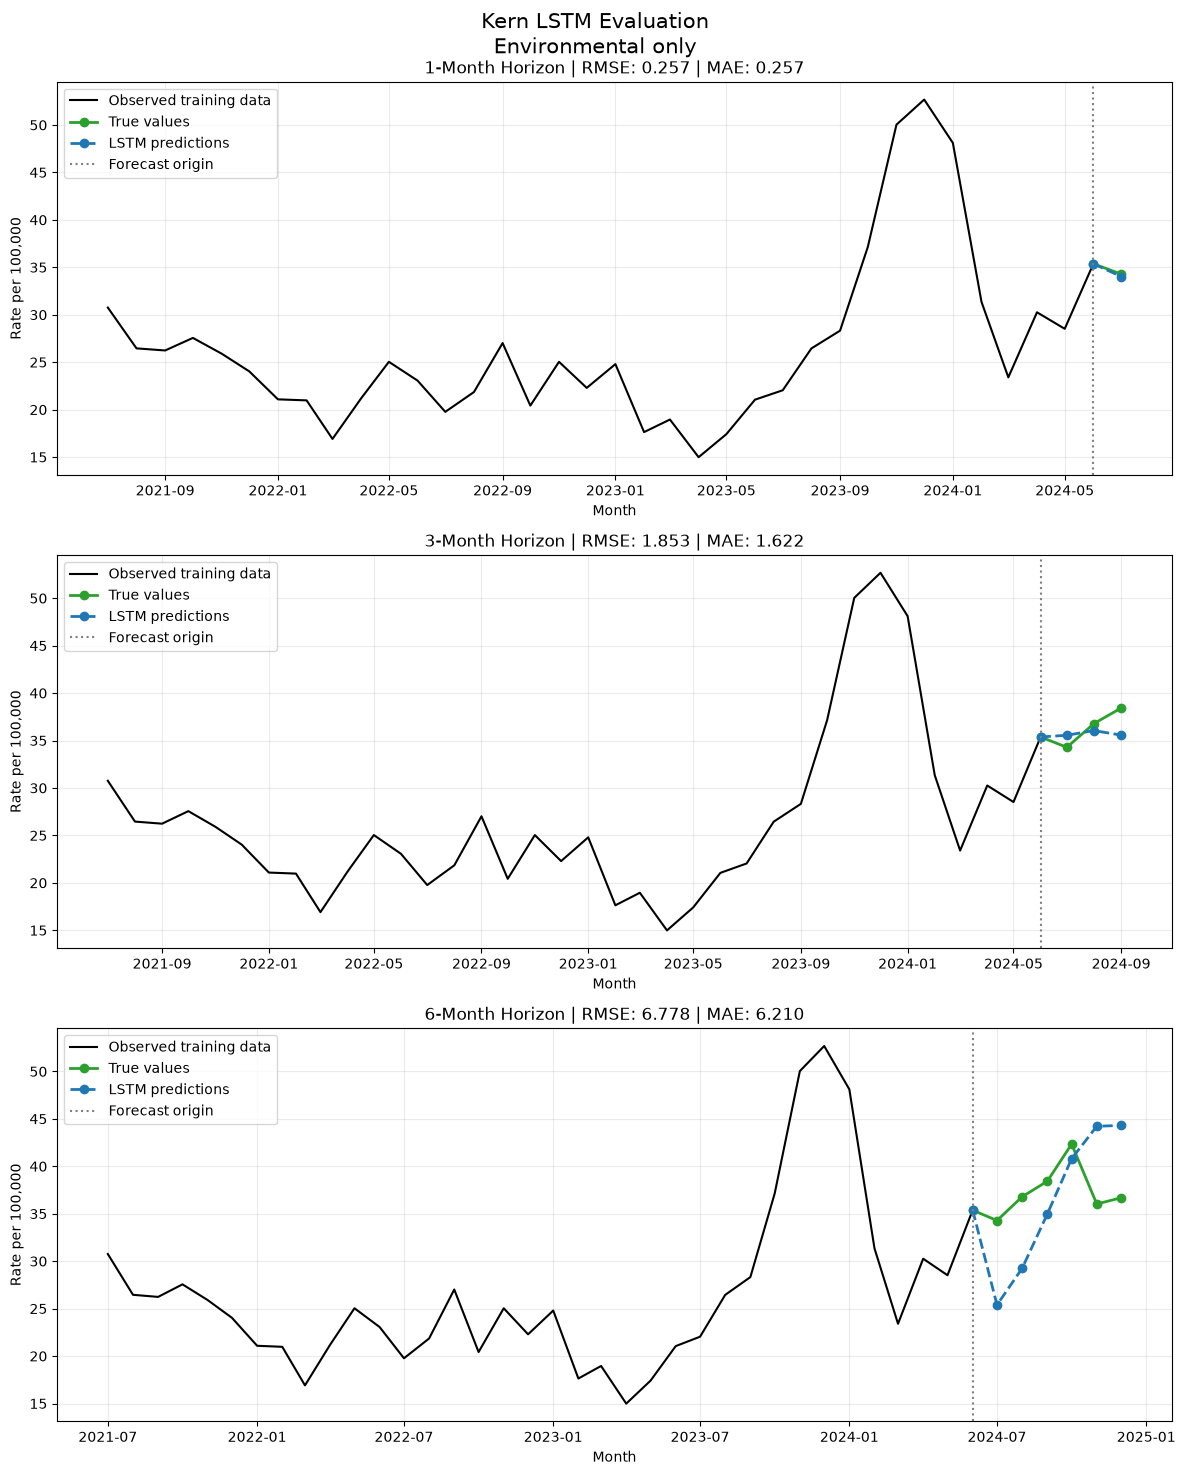


Running Los Angeles...
Los Angeles: training 1-month model...
Epoch 50/400 | Loss: 0.232862
Epoch 100/400 | Loss: 0.167273
Epoch 150/400 | Loss: 0.159940
Epoch 200/400 | Loss: 0.129279
Epoch 250/400 | Loss: 0.117329
Epoch 300/400 | Loss: 0.144096
Epoch 350/400 | Loss: 0.131921
Epoch 400/400 | Loss: 0.116939
Los Angeles: training 3-month model...
Epoch 50/400 | Loss: 0.277714
Epoch 100/400 | Loss: 0.208836
Epoch 150/400 | Loss: 0.159097
Epoch 200/400 | Loss: 0.158207
Epoch 250/400 | Loss: 0.161137
Epoch 300/400 | Loss: 0.154451
Epoch 350/400 | Loss: 0.132855
Epoch 400/400 | Loss: 0.136402
Los Angeles: training 6-month model...
Epoch 50/400 | Loss: 0.271187
Epoch 100/400 | Loss: 0.205642
Epoch 150/400 | Loss: 0.189599
Epoch 200/400 | Loss: 0.161248
Epoch 250/400 | Loss: 0.175999
Epoch 300/400 | Loss: 0.187727
Epoch 350/400 | Loss: 0.158234
Epoch 400/400 | Loss: 0.161888


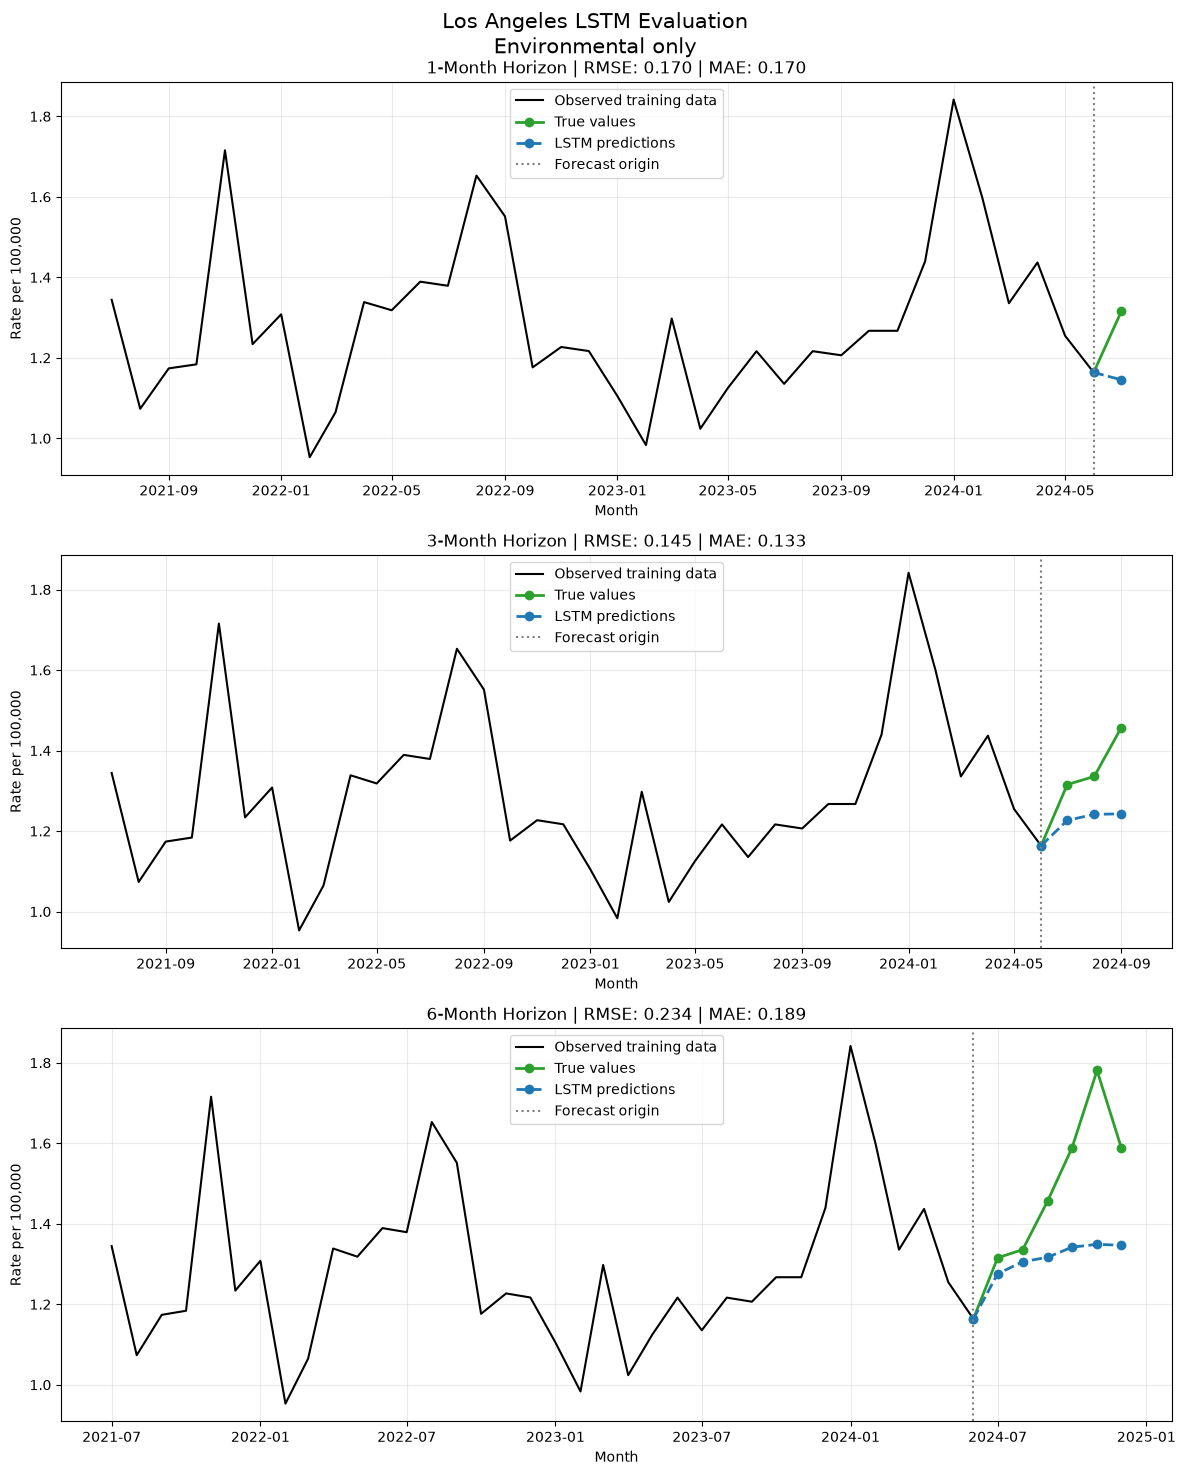


Running Orange...
Orange: training 1-month model...
Epoch 50/400 | Loss: 0.344894
Epoch 100/400 | Loss: 0.312136
Epoch 150/400 | Loss: 0.250382
Epoch 200/400 | Loss: 0.210917
Epoch 250/400 | Loss: 0.223940
Epoch 300/400 | Loss: 0.187274
Epoch 350/400 | Loss: 0.194154
Epoch 400/400 | Loss: 0.186757
Orange: training 3-month model...
Epoch 50/400 | Loss: 0.336429
Epoch 100/400 | Loss: 0.281971
Epoch 150/400 | Loss: 0.275188
Epoch 200/400 | Loss: 0.247832
Epoch 250/400 | Loss: 0.239572
Epoch 300/400 | Loss: 0.248780
Epoch 350/400 | Loss: 0.227799
Epoch 400/400 | Loss: 0.220049
Orange: training 6-month model...
Epoch 50/400 | Loss: 0.366789
Epoch 100/400 | Loss: 0.332416
Epoch 150/400 | Loss: 0.288335
Epoch 200/400 | Loss: 0.266145
Epoch 250/400 | Loss: 0.265299
Epoch 300/400 | Loss: 0.262953
Epoch 350/400 | Loss: 0.250290
Epoch 400/400 | Loss: 0.248130


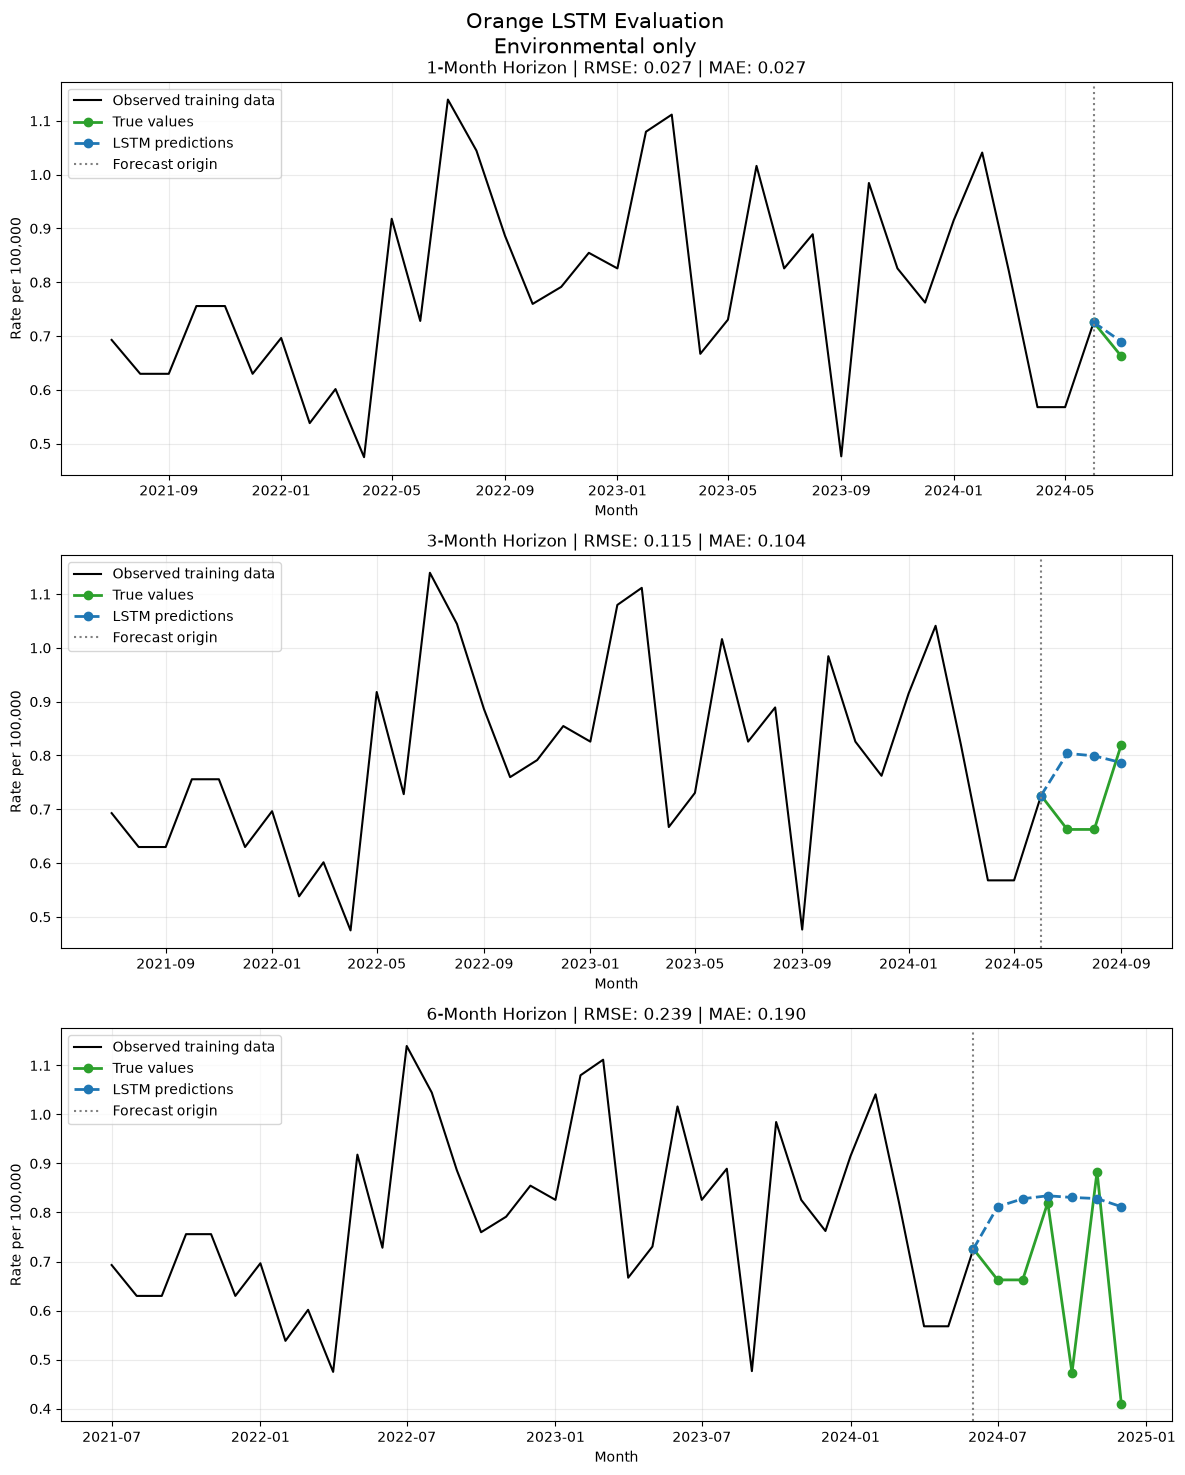


Running San Diego...
San Diego: training 1-month model...
Epoch 50/400 | Loss: 0.361743
Epoch 100/400 | Loss: 0.226460
Epoch 150/400 | Loss: 0.220000
Epoch 200/400 | Loss: 0.203980
Epoch 250/400 | Loss: 0.178190
Epoch 300/400 | Loss: 0.167354
Epoch 350/400 | Loss: 0.144520
Epoch 400/400 | Loss: 0.170564
San Diego: training 3-month model...
Epoch 50/400 | Loss: 0.330817
Epoch 100/400 | Loss: 0.243018
Epoch 150/400 | Loss: 0.229959
Epoch 200/400 | Loss: 0.216524
Epoch 250/400 | Loss: 0.215919
Epoch 300/400 | Loss: 0.194357
Epoch 350/400 | Loss: 0.191093
Epoch 400/400 | Loss: 0.190769
San Diego: training 6-month model...
Epoch 50/400 | Loss: 0.361887
Epoch 100/400 | Loss: 0.288460
Epoch 150/400 | Loss: 0.233101
Epoch 200/400 | Loss: 0.246902
Epoch 250/400 | Loss: 0.235878
Epoch 300/400 | Loss: 0.245363
Epoch 350/400 | Loss: 0.220250
Epoch 400/400 | Loss: 0.218945


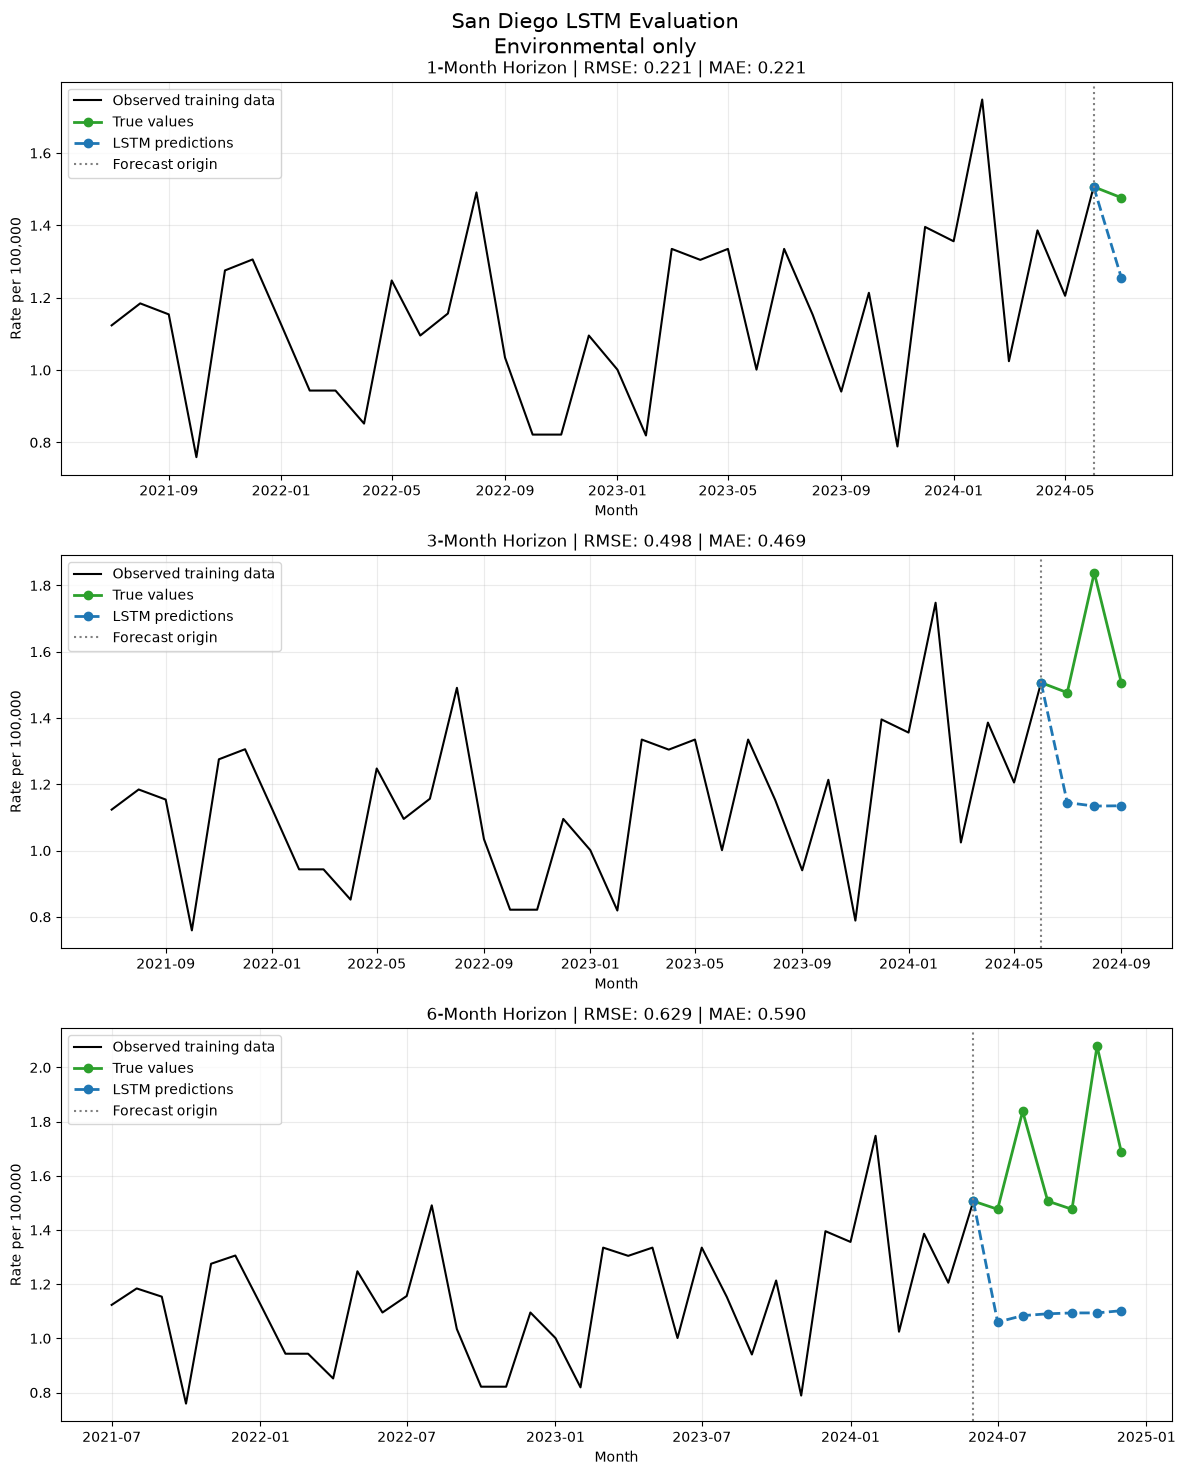


Running San Luis Obispo...
San Luis Obispo: training 1-month model...
Epoch 50/400 | Loss: 0.601001
Epoch 100/400 | Loss: 0.364565
Epoch 150/400 | Loss: 0.248358
Epoch 200/400 | Loss: 0.215794
Epoch 250/400 | Loss: 0.256373
Epoch 300/400 | Loss: 0.221525
Epoch 350/400 | Loss: 0.164221
Epoch 400/400 | Loss: 0.156083
San Luis Obispo: training 3-month model...
Epoch 50/400 | Loss: 0.467679
Epoch 100/400 | Loss: 0.275379
Epoch 150/400 | Loss: 0.300003
Epoch 200/400 | Loss: 0.269802
Epoch 250/400 | Loss: 0.214744
Epoch 300/400 | Loss: 0.199595
Epoch 350/400 | Loss: 0.182727
Epoch 400/400 | Loss: 0.272027
San Luis Obispo: training 6-month model...
Epoch 50/400 | Loss: 0.580890
Epoch 100/400 | Loss: 0.430366
Epoch 150/400 | Loss: 0.369568
Epoch 200/400 | Loss: 0.344252
Epoch 250/400 | Loss: 0.326470
Epoch 300/400 | Loss: 0.243133
Epoch 350/400 | Loss: 0.299518
Epoch 400/400 | Loss: 0.254893


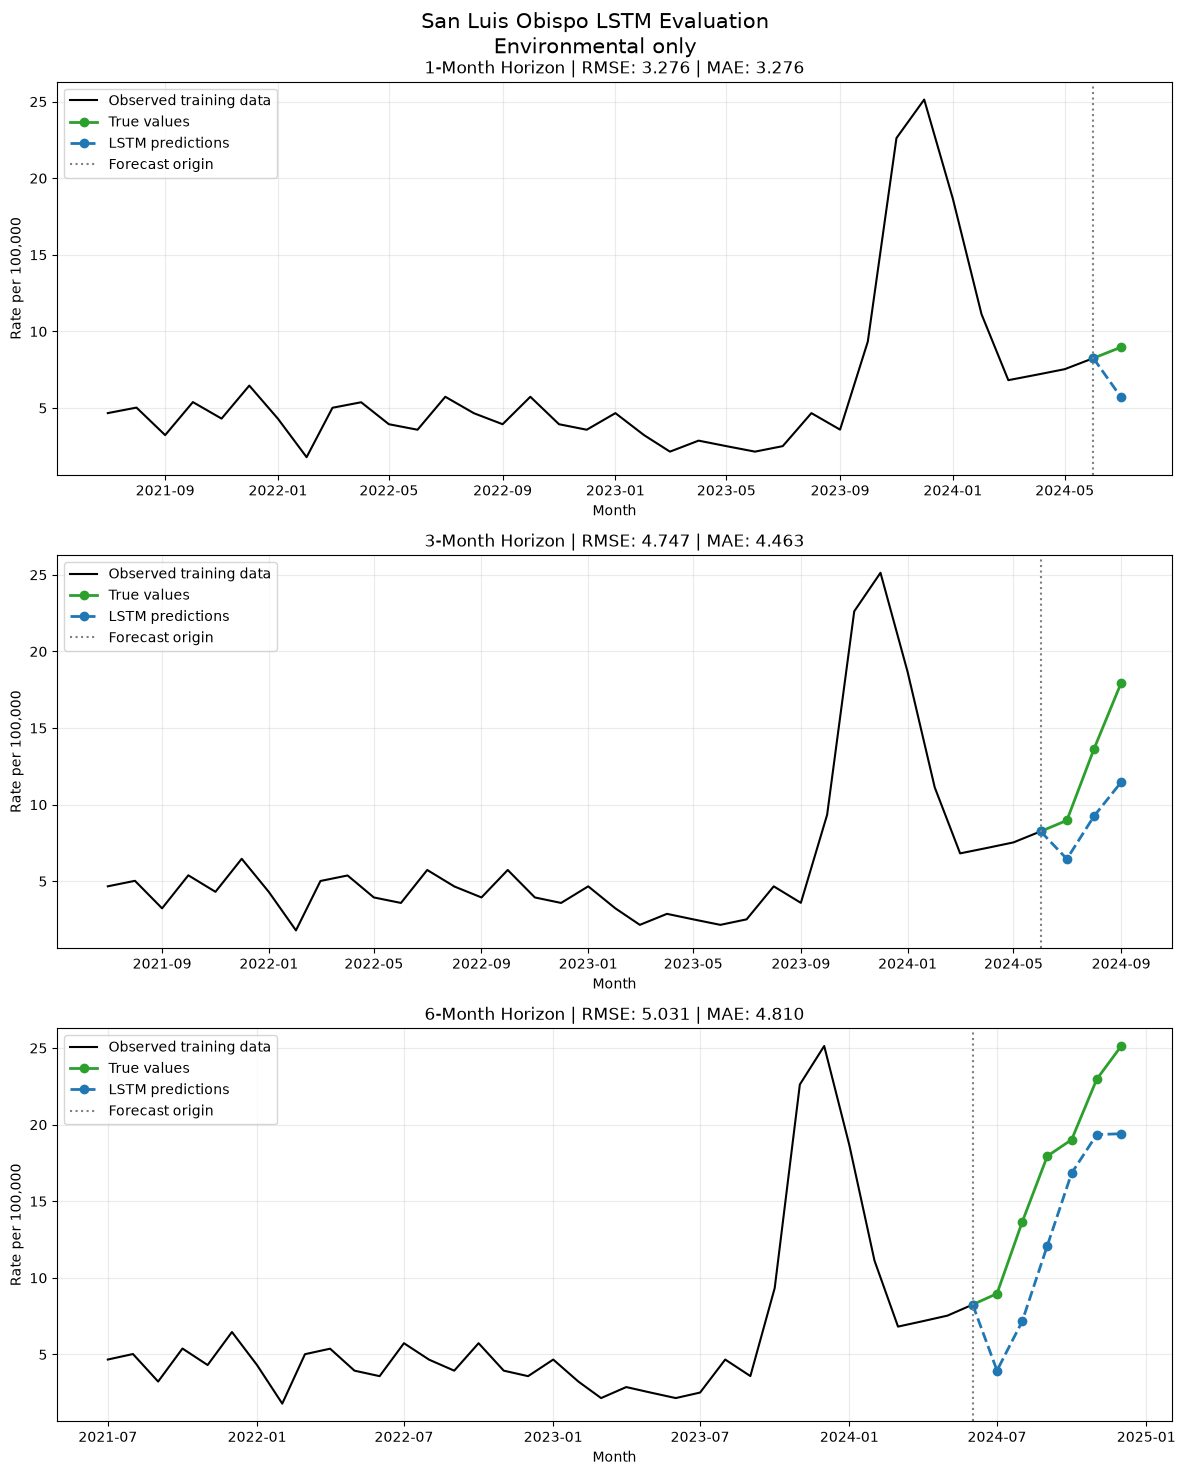


Running Tulare...
Tulare: training 1-month model...
Epoch 50/400 | Loss: 0.549099
Epoch 100/400 | Loss: 0.321669
Epoch 150/400 | Loss: 0.322098
Epoch 200/400 | Loss: 0.213996
Epoch 250/400 | Loss: 0.228101
Epoch 300/400 | Loss: 0.236342
Epoch 350/400 | Loss: 0.195397
Epoch 400/400 | Loss: 0.207720
Tulare: training 3-month model...
Epoch 50/400 | Loss: 0.506157
Epoch 100/400 | Loss: 0.359926
Epoch 150/400 | Loss: 0.296474
Epoch 200/400 | Loss: 0.333157


In [ ]:
# lookback 12, no log target, no rate, hidden size 8
all_lstm_environment_only = run_lstm_all_counties(
    counties=counties,
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config= {
        "lookback": 12,
        "use_rate_features": False,
        "use_log_target": False,
        "include_calendar_features": True,
    },
    lstm_parameters={
        'hidden_size': 8,
        'num_layers': 1,
        'dropout': 0.4,
        'epochs': 400,
        'learning_rate': 0.001,
        'weight_decay': 1e-05,
        'batch_size': 32,
        'seed': 42,
        'device': 'auto',
        'verbose_every': 50},
    output_dir=output_dir,
    show_plots=True,
)

display(all_lstm_environment_only["metrics"])
display(all_lstm_environment_only["metric_summary"])